# An Explainable, Ensemble-Based ML System for Detecting Anomalous Air Pollution Events
### Nairobi Low-Cost Sensor Network (2019–2026)

> **One-line summary:** an automated, explainable system that separates genuine air pollution events from sensor malfunctions in a multi-year archive of ~292k hourly readings from ~50 low-cost sensors.

---

## Table of Contents

| Part | Section | What happens |
|---|---|---|
| **A. Data** | 1. Setup and Configuration | Imports, `configs/config.yaml`, split boundaries |
| | 2. Load Data | Read the pipeline output, **UTC → Nairobi local time** |
| | 3. Sensor Type Audit | What each sensor can actually measure |
| | 4. Missingness Classification | Structural / MCAR / MAR / MNAR screens |
| | 5. Corrected Missingness Handling | Cleaning, **sensor-range faults**, training-only imputation |
| | 6. Missing-Month Handling | Gap-aware treatment, no fabricated data |
| **B. Understanding** | 7. Exploratory Data Analysis | Distributions, time, season, space, sensors |
| **C. Modelling** | 8. Feature Engineering | Past-only rolling, ratio and cross-sensor features |
| | 9. Leakage-Safe Splits | Temporal train / validation / test |
| | 10. Seasonal Baseline and Residuals | Train-fit baseline, residual signal |
| | 11. Base Anomaly Detectors | Five detector paradigms and pseudo-labels |
| | 12. Feature Pruning and Stacked Ensemble | SMOTE + XGBoost meta-model, **StratifiedGroupKFold** |
| **D. Evaluation** | 13. Evaluation and Ablation | Metrics, corroboration, ablation, locked test, **flag concentration, documented events** |
| | 14. Explainability with SHAP | Global and local explanations |
| **E. Interpretation** | 15. Severity and Cause Classification | Watch / Alert / Critical and genuine vs fault |
| | 16. Spatial Validation | Moran's I (**sensor-level coordinates**) and LISA |
| | 17. Case Studies and Dashboards | Events, monthly rates, map, Plotly dashboard |
| **F. Delivery** | 18. Deployment (FastAPI + Docker) | Scripted pipeline artifacts, **parity check**, API smoke test |
| | 19. Monitoring and Retraining | MLflow and Evidently |
| | 20. Technique Justification | Why these methods, and why not the alternatives |
| | 21. Conclusion, Limitations, Future Work | |
| | 22. References | |

> **How this notebook relates to the rest of the repository.** This notebook is the *analysis and evidence*: it explains and justifies every step. The *reproducible system* is the scripted package in `src/airq/` (`python -m airq.pipeline ingest | train | predict`) and the FastAPI service in `api/`. The dataset itself is rebuilt from the raw archive by `notebooks/01_data_pipeline.ipynb`. Section 18 asserts that the package reproduces this notebook's features, probabilities, severity and cause labels exactly.

### Changes from the previous version

| # | Change | Why |
|---|---|---|
| 1 | Hours, weekdays and splits use **Nairobi local time** (archive is UTC) | PM2.5 peaks at 04:00 and 16:00 in the file, which are 07:00 and 19:00 rush hours locally; the baseline should condition on local hour and weekday |
| 2 | PM readings above the sensors' measuring limit (> 1000 µg/m³) are **set aside as certain faults** | 410 such hours from one sensor (3626) sat in the validation year and inflated validation PR-AUC (0.975 vs 0.415 on test) |
| 3 | **Severity** uses residual size and health bands, not probability | With a 0.99 threshold every flag had p > 0.9, so all but two flags were "Critical" |
| 4 | Cross-validation is **StratifiedGroupKFold** | Keeps the proposal's stratification while never splitting a sensor across folds |
| 5 | Moran's I uses **sensor-level** coordinates | `NEIGHBORHOOD_LAT/LON` hold each sensor's own site, not a neighbourhood centroid |
| 6 | Added flag-concentration and documented-event checks; Streamlit-only deployment replaced by FastAPI + Docker | Honest evaluation; course deployment requirement |

## Research Questions

| # | Question | Answered in |
|---|---|---|
| 1 | What cleaning and preprocessing workflow does multi-year, multi-sensor air quality data need? | Sections 3–6 |
| 2 | How do statistical, density, kernel, clustering and time-series detectors perform individually? | Sections 11, 13.2 |
| 3 | Does a SMOTE-balanced stacked ensemble outperform individual base detectors? | Sections 12, 13 |
| 4 | Can flagged anomalies be validated with cross-sensor and external evidence? | Sections 13.2, 15, 16 |
| 5 | How can SHAP explain each flagged anomaly? | Section 14 |
| 6 | How can SHAP and cross-sensor evidence produce severity tiers and likely-cause categories? | Section 15 |

## Design Principles

1. **Train-only fitting.** Everything learned from data (imputation medians, seasonal baseline, MAD parameters, scalers, detectors, STL thresholds) is fit on the training period only.
2. **Past-only windows.** Rolling features use `shift(1)`, so a window never contains the reading being scored.
3. **No label leakage.** The meta-model does not see the detector flags or vote count, because the pseudo-label is a function of them.
4. **Independent evidence.** Cross-sensor corroboration is the independent check; agreement with a consensus label built from the same detectors is partly circular.
5. **No sampling.** Every detector is fit on the full training set, every model is evaluated on the full validation and test sets, and SHAP is computed on all validation rows.
6. **Lean features.** Only features that earn their place are modelled; calendar encodings and redundant or near-zero-importance features are dropped (Section 12.0).

## Data-Flow at a Glance

```
raw hourly readings
   └─► clean (5) ─► features (8) ─► temporal split (9) ─► baseline + residual (10)
                                                              │
                  five base detectors (11) ─► consensus pseudo-label
                                                              │
        feature pruning + SMOTE/XGBoost meta-model (12) ─► evaluation (13)
                                                              │
        SHAP (14) ─► severity + cause (15) ─► spatial checks (16) ─► dashboards (17)
                                                              │
                         FastAPI + Docker deployment (18) ─► monitoring (19)
```

---
# Part A: Data

## 1. Setup and Configuration

**Goal:** load libraries and define the constants that control the whole notebook.

| Constant | Purpose |
|---|---|
| `RANDOM_STATE` | Reproducibility |
| `DATA_PATH` | Hourly dataset written by the data pipeline (`notebooks/01_data_pipeline.ipynb`) |
| `TARGET_COL` | Primary pollutant (`PM25`) |
| `TRAIN_END`, `VAL_END` | Temporal split boundaries: train `< TRAIN_END`, validation `[TRAIN_END, VAL_END)`, test `>= VAL_END` |
| `RUN_RETRAIN_ABLATION` | Retraining five extra models is slow; flip to `True` to run it (Section 13.3) |

All constants come from `configs/config.yaml`, the same file the scripted pipeline and the API read, so the notebook and the deployed system cannot silently disagree. Split boundaries are in **Nairobi local time**.

In [1]:
import matplotlib
# ============================================================
# 1. SETUP AND CONFIGURATION
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
import joblib
import json
import os
from datetime import datetime

# Modelling
from sklearn.model_selection import (train_test_split, GroupKFold, TimeSeriesSplit,
                                     cross_validate, StratifiedKFold, StratifiedGroupKFold)
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, precision_recall_curve,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             f1_score, precision_score, recall_score, brier_score_loss)
from sklearn.ensemble import IsolationForest, RandomForestClassifier, VotingClassifier
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.covariance import EllipticEnvelope
from sklearn.calibration import CalibratedClassifierCV
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.neighbors import KDTree
from sklearn.base import BaseEstimator, ClassifierMixin

# Imbalance + boosting + explainability
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, SMOTENC
import xgboost as xgb
import shap

# Time series + stats
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import mannwhitneyu, chi2_contingency

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', None)

# Repository paths: make src/ importable from notebooks/ or the repo root
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.environ.setdefault('AIRQ_ROOT', str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

from airq.config import load_config, resolve
CFG = load_config()

RANDOM_STATE  = CFG['random_state']
DATA_PATH     = resolve(CFG['data_path'])          # written by notebooks/01_data_pipeline.ipynb
TARGET_COL    = 'PM25'
LOCAL_OFFSET  = CFG['local_utc_offset_hours']     # Africa/Nairobi = UTC+3
PM_SENSOR_MAX = CFG['cleaning']['pm_sensor_max']  # SDS011 / PMS5003 measuring limit (ug/m3)

# Temporal split boundaries in LOCAL time (train < TRAIN_END <= val < VAL_END <= test)
TRAIN_END = pd.Timestamp(CFG['split']['train_end'])
VAL_END   = pd.Timestamp(CFG['split']['val_end'])

# Retraining 5 extra models for the ablation is slow; flip to True when you want it
RUN_RETRAIN_ABLATION = False

print('Libraries loaded.')

# ------------------------------------------------------------------
# Plot helpers used by the EDA (Section 7)
# ------------------------------------------------------------------
PM_COLS = ['PM1', 'PM25', 'PM10']
PM_FLOOR = 0.5   # log axes cannot show 0; readings below this are drawn at the floor and counted

def pm_for_log(s):
    """Values ready for a log axis: NaN dropped, values below PM_FLOOR raised to it."""
    s = s.dropna()
    return s.clip(lower=PM_FLOOR), int((s < PM_FLOOR).sum())

def annotate_quantiles(ax, s, unit='µg/m³', log=False):
    """Mark median, 95th and 99th percentiles and print them with the max in a corner box."""
    q = s.quantile([0.5, 0.95, 0.99])
    for v, ls, lab in zip(q.values, ['-', '--', ':'], ['median', 'p95', 'p99']):
        ax.axvline(v, color='k', ls=ls, lw=1, alpha=0.8, label=f'{lab} = {v:,.1f}')
    ax.text(0.99, 0.95, f'n = {len(s):,}\nmax = {s.max():,.1f} {unit}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8, bbox=dict(boxstyle='round', fc='white', alpha=0.85))
    ax.legend(loc='upper left' if not log else 'center right', fontsize=7, frameon=True)


Libraries loaded.


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Data

**Goal:** read the hourly dataset produced by the data pipeline and take a first look.

**Steps**
1. Read the dataset (`.csv.gz` written by `notebooks/01_data_pipeline.ipynb`; the `.xlsx` has identical content).
2. Parse `DATE` + `TIME` into `DATETIME_UTC`. The sensors.AFRICA archive is in **UTC**, and the pipeline keeps it that way.
3. Convert to Nairobi local time (`DATETIME` = UTC + 3 h; Kenya has no daylight saving) and derive `HOUR`, `WEEKDAY`, `MONTH`, `YEAR` from local time. Rush hours, cooking peaks and weekdays are local phenomena, so the baseline must condition on local time.
4. Report shape, date range, sensor and neighbourhood counts.

In [2]:
# ============================================================
# 2. LOAD DATA
# ============================================================
from airq.data.ingest import load_dataset
df = load_dataset(DATA_PATH)

# The archive and the pipeline output are in UTC
df['DATETIME_UTC'] = pd.to_datetime(
    pd.to_datetime(df['DATE']).dt.strftime('%Y-%m-%d') + ' ' + df['TIME'].astype(str)
)
# Nairobi local time drives every calendar feature (and the split boundaries)
df['DATETIME'] = df['DATETIME_UTC'] + pd.Timedelta(hours=LOCAL_OFFSET)
df['HOUR']    = df['DATETIME'].dt.hour
df['WEEKDAY'] = df['DATETIME'].dt.day_name()
df['MONTH']   = df['DATETIME'].dt.month
df['YEAR']    = df['DATETIME'].dt.year

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range (local): {df['DATETIME'].min()} to {df['DATETIME'].max()}")
print(f"Sensors: {df['LOCATION'].nunique()}")
print(f"Neighbourhoods: {df['NEIGHBORHOOD'].nunique()}")
df.head()

Shape: 292,059 rows × 18 columns
Date range (local): 2019-01-01 03:00:00 to 2026-07-01 02:00:00
Sensors: 53
Neighbourhoods: 27


,DATE,TIME,PM1,PM25,PM10,HUMIDITY,TEMPERATURE,LOCATION,NEIGHBORHOOD,SENSOR_TYPE,YEAR,MONTH,WEEKDAY,HOUR,NEIGHBORHOOD_LAT,NEIGHBORHOOD_LON,DATETIME_UTC,DATETIME
0,2019-01-01,00:00:00,NaN,6.228333,9.785833,81.620834,15.083333,21,Kilimani sublocation,"DHT22, SDS011",2019,1,Tuesday,3,-1.287,36.811001,2019-01-01,2019-01-01 03:00:00
1,2019-01-01,00:00:00,NaN,8.235416,8.887083,99.900002,16.933332,27,Woodley/Kenyatta/Golf Course ward,"DHT22, SDS011",2019,1,Tuesday,3,-1.306,36.772999,2019-01-01,2019-01-01 03:00:00
2,2019-01-01,00:00:00,NaN,12.682800,24.133600,90.444000,17.275999,29,Woodley/Kenyatta/Golf Course ward,"DHT22, SDS011",2019,1,Tuesday,3,-1.300,36.785000,2019-01-01,2019-01-01 03:00:00
3,2019-01-01,00:00:00,NaN,18.980434,33.828697,89.327271,17.009092,30,Kileleshwa sublocation,"DHT22, SDS011",2019,1,Tuesday,3,-1.290,36.777000,2019-01-01,2019-01-01 03:00:00
4,2019-01-01,00:00:00,NaN,16.564348,26.259130,64.434784,20.900000,31,Kilimani sublocation,"DHT22, SDS011",2019,1,Tuesday,3,-1.291,36.780998,2019-01-01,2019-01-01 03:00:00


### 2.1 Evidence that the stored timestamps are UTC

If `TIME` were local, Nairobi's morning (≈ 07:00–08:00) and evening (≈ 18:00–20:00) traffic and cooking peaks would sit at those hours. In the stored (UTC) hour they sit three hours earlier.

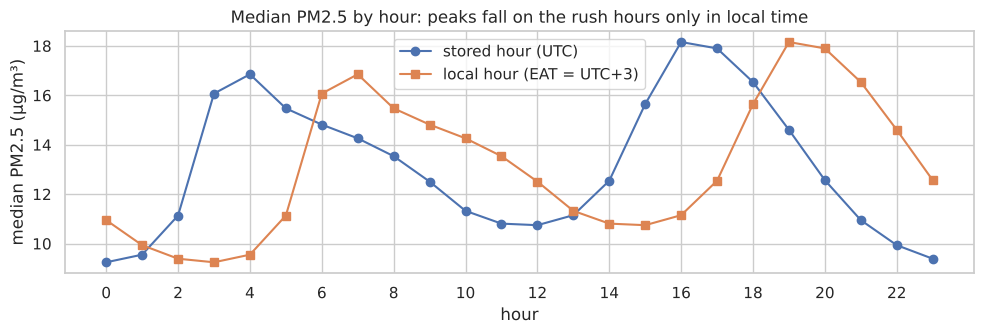

Peak hours, UTC  : [16, 17, 4]
Peak hours, local: [19, 20, 7]


In [3]:
# 2.1 Diurnal profile in stored (UTC) hour vs local hour
prof_utc   = df.groupby(df['DATETIME_UTC'].dt.hour)['PM25'].median()
prof_local = df.groupby('HOUR')['PM25'].median()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(prof_utc.index, prof_utc.values, marker='o', label='stored hour (UTC)')
ax.plot(prof_local.index, prof_local.values, marker='s', label='local hour (EAT = UTC+3)')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('hour'); ax.set_ylabel('median PM2.5 (µg/m³)')
ax.set_title('Median PM2.5 by hour: peaks fall on the rush hours only in local time'); ax.legend()
plt.tight_layout(); plt.show()
print('Peak hours, UTC  :', prof_utc.sort_values(ascending=False).head(3).index.tolist())
print('Peak hours, local:', prof_local.sort_values(ascending=False).head(3).index.tolist())

## 3. Sensor Type Audit

**Goal:** find out what each sensor type actually measures *before* touching missing values.

Low-cost networks combine sensors (e.g. `DHT22` for humidity/temperature, `SDS011` for PM2.5/PM10). If a column is missing for every row whose sensor combination cannot measure it, that missingness is **structural**, not accidental, and imputing it globally would be wrong.

**Outputs:** (1) counts per individual sensor type, (2) fraction non-null per individual type, (3) fraction non-null per full `SENSOR_TYPE` combination.

In [4]:
# ============================================================
# 3. SENSOR TYPE AUDIT
# ============================================================

# Split combined sensor strings like "DHT22, SDS011"
df['SENSOR_LIST'] = df['SENSOR_TYPE'].astype(str).str.split(', ')
df_exploded = df.explode('SENSOR_LIST')

print("Unique individual sensor types:")
print(df_exploded['SENSOR_LIST'].value_counts())

# What does each sensor type measure?
measure_cols = ['PM1', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE']
audit = (
    df_exploded
    .groupby('SENSOR_LIST')[measure_cols]
    .apply(lambda g: g.notna().mean())
    .round(3)
)
print("\nFraction non-null by individual sensor type:")
print(audit)

# Full combinations
combo_audit = (
    df.groupby('SENSOR_TYPE')[measure_cols]
    .apply(lambda g: g.notna().mean())
    .round(3)
)
print("\nFraction non-null by full SENSOR_TYPE combination:")
print(combo_audit)

Unique individual sensor types:
SENSOR_LIST
DHT22      254213
pms5003    162175
SDS011     121137
Name: count, dtype: int64

Fraction non-null by individual sensor type:
               PM1   PM25   PM10  HUMIDITY  TEMPERATURE
SENSOR_LIST                                            
DHT22        0.529  0.963  0.963     1.000        1.000
SDS011       0.013  1.000  1.000     0.921        0.921
pms5003      0.999  1.000  1.000     0.826        0.826

Fraction non-null by full SENSOR_TYPE combination:
                          PM1  PM25  PM10  HUMIDITY  TEMPERATURE
SENSOR_TYPE                                                     
DHT22                   0.000   0.0   0.0     1.000        1.000
DHT22, SDS011           0.006   1.0   1.0     1.000        1.000
DHT22, SDS011, pms5003  1.000   1.0   1.0     1.000        1.000
DHT22, pms5003          0.999   1.0   1.0     1.000        1.000
SDS011                  0.021   1.0   1.0     0.003        0.003
SDS011, pms5003         1.000   1.0   1.0  

## 4. Missingness Classification

**Goal:** classify each column's missingness, because the correct handling depends entirely on the mechanism.

| Class | Meaning | Example |
|---|---|---|
| **Structural** (MAR by sensor type) | Missing by design | `PM1` for sensors that cannot measure it |
| **MCAR** | Missing completely at random | A random API timeout drops a row |
| **MAR** | Missing at random given observables | Older devices drop humidity |
| **MNAR** | Missing depends on the missing value itself | A sensor fails when pollution is extreme |

### 4.1 Missingness by sensor type

In [5]:
# ============================================================
# 4. MISSINGNESS CLASSIFICATION
# ============================================================

missing_cols = ['PM1', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE',
                'NEIGHBORHOOD_LAT', 'NEIGHBORHOOD_LON']

def missingness_by_sensor(df, col):
    tmp = df.groupby('SENSOR_TYPE')[col].apply(lambda s: s.isna().mean())
    return tmp.sort_values(ascending=False)

for c in missing_cols:
    print(f"\n--- {c} ---")
    print(missingness_by_sensor(df, c))


--- PM1 ---
SENSOR_TYPE
DHT22                     0.999788
DHT22, SDS011             0.993686
SDS011                    0.979241
DHT22, pms5003            0.000968
pms5003                   0.000319
DHT22, SDS011, pms5003    0.000000
SDS011, pms5003           0.000000
Name: PM1, dtype: float64

--- PM25 ---
SENSOR_TYPE
DHT22                     0.999788
SDS011                    0.000209
pms5003                   0.000106
DHT22, pms5003            0.000083
DHT22, SDS011             0.000000
DHT22, SDS011, pms5003    0.000000
SDS011, pms5003           0.000000
Name: PM25, dtype: float64

--- PM10 ---
SENSOR_TYPE
DHT22                     0.999788
SDS011                    0.000209
pms5003                   0.000142
DHT22, pms5003            0.000083
DHT22, SDS011             0.000000
DHT22, SDS011, pms5003    0.000000
SDS011, pms5003           0.000000
Name: PM10, dtype: float64

--- HUMIDITY ---
SENSOR_TYPE
SDS011, pms5003           1.000000
pms5003                   0.999257
SDS011  

### 4.2 MCAR screen

Quick screen: compare the observed variables between rows where the column is missing and rows where it is present. Large differences argue against MCAR.

In [6]:
# ============================================================
# 4.2 MCAR SCREEN
# ============================================================
def mcar_screen(df, col, test_cols):
    """Quick screen: compare missing vs non-missing distributions."""
    miss = df[col].isna()
    if miss.sum() == 0 or miss.sum() == len(df):
        return None
    results = {}
    for t in test_cols:
        if df[t].dtype.kind in 'biufc':
            results[t] = df.loc[~miss, t].mean() - df.loc[miss, t].mean()
        else:
            ct = pd.crosstab(miss, df[t])
            chi2, p, _, _ = chi2_contingency(ct)
            results[t] = p
    return results

for c in ['HUMIDITY', 'TEMPERATURE', 'PM1']:
    print(f"\nMCAR screen for {c} (mean difference: non-missing minus missing):")
    print(mcar_screen(df, c, ['PM25', 'PM10', 'HOUR', 'MONTH']))


MCAR screen for HUMIDITY (mean difference: non-missing minus missing):
{'PM25': np.float64(-1.0524806490138197), 'PM10': np.float64(0.3776897714370051), 'HOUR': np.float64(-0.12481412791541757), 'MONTH': np.float64(0.1570328669436627)}

MCAR screen for TEMPERATURE (mean difference: non-missing minus missing):
{'PM25': np.float64(-1.0527074140039439), 'PM10': np.float64(0.37736405874755263), 'HOUR': np.float64(-0.12484084430764675), 'MONTH': np.float64(0.1570850473538954)}

MCAR screen for PM1 (mean difference: non-missing minus missing):
{'PM25': np.float64(26.916902259204818), 'PM10': np.float64(22.787865027621425), 'HOUR': np.float64(0.32077426638014117), 'MONTH': np.float64(1.3868929451034164)}


### 4.3 MNAR screen

If PM2.5 differs systematically when a companion variable is missing, the missingness may depend on pollution level (MNAR).

In [7]:
# ============================================================
# 4.3 MNAR SCREEN
# ============================================================
df['humidity_missing'] = df['HUMIDITY'].isna().astype(int)
df['pm1_missing']      = df['PM1'].isna().astype(int)

print("PM2.5 when humidity missing vs present:")
print(df.groupby('humidity_missing')['PM25'].agg(['mean', 'median', 'count']))

print("\nPM2.5 when PM1 missing vs present:")
print(df.groupby('pm1_missing')['PM25'].agg(['mean', 'median', 'count']))

PM2.5 when humidity missing vs present:
                       mean     median   count
humidity_missing                              
0                 23.846993  12.545133  244801
1                 24.899473  14.439875   37802

PM2.5 when PM1 missing vs present:
                  mean     median   count
pm1_missing                              
0            35.385430  20.767873  162938
1             8.468528   5.944782  119665


## 5. Corrected Missingness Handling

**Goal:** clean the data according to the missingness classes above, without leaking information from validation or test.

### Handling policy

| Classification | Example | Handling |
|---|---|---|
| Structural / MAR by sensor type | `PM1` missing because the sensor cannot measure it | Keep missing + indicator. Do not median-impute globally. |
| MCAR | Random API timeout drops a row | Median/mode imputation is acceptable, fit inside CV folds. |
| MAR | `HUMIDITY` missing more for a device type | Conditional imputation (neighbourhood × hour) + indicator. |
| MNAR | Sensor fails when pollution is extreme | Keep indicator, use tree models that accept NaN natively. |

> **Do not** globally median-impute `PM1`, `HUMIDITY` or `TEMPERATURE`. That destroys the informational value of missingness.

> **Leakage note:** the neighbourhood × hour medians used to fill humidity and temperature are computed from the **training period only** (`DATETIME < TRAIN_END`).

### Pipeline steps

| Step | Action |
|---|---|
| 5.1 | Physical bounds: out-of-range humidity/temperature become NaN |
| 5.1b | **Sensor-range faults:** PM2.5 or PM10 above 1000 µg/m³ (SDS011 limit 999.9, PMS5003 limit 1000) are set aside as certain malfunctions. They are labelled by rule at scoring time and kept out of every fitted quantity |
| 5.1c | PM ordering violations (PM10 < PM2.5 or PM2.5 < PM1) become NaN |
| 5.2 | Drop rows with missing `PM25` / `PM10` |
| 5.3 | Drop the `No coordinates` placeholder neighbourhood |
| 5.4 | Add missing indicators before any imputation |
| 5.5 | Sort by sensor and time |
| 5.6 | Interpolate short gaps (≤ 3 readings) per sensor |
| 5.7 | Fill the rest with training-period neighbourhood × hour medians |
| 5.8 | Leave `PM1` as NaN (structural) |

> **Why set the sensor-range faults aside rather than let the detectors find them?** They are certain faults, so detecting them needs no model. Left in, 410 hours from one sensor (3626, Sep–Oct 2024) dominated the validation year: they were 368 of the 393 "likely fault" flags and pushed validation PR-AUC to 0.975 while test was 0.415. Removing them makes validation an honest guide to test performance, and the API still reports them (`rule = pm_above_sensor_range`, severity Critical).

In [8]:
# ============================================================
# 5. CORRECTED MISSINGNESS HANDLING
# ============================================================
df_clean = df.copy()

# 5.1 Physical bounds → NaN (invalid values, not missing values)
temp_bad = ~df_clean['TEMPERATURE'].between(*CFG['cleaning']['temperature_range']) & df_clean['TEMPERATURE'].notna()
hum_bad  = ~df_clean['HUMIDITY'].between(*CFG['cleaning']['humidity_range']) & df_clean['HUMIDITY'].notna()
df_clean.loc[temp_bad, 'TEMPERATURE'] = np.nan
df_clean.loc[hum_bad, 'HUMIDITY'] = np.nan

# 5.1b Readings above the PM sensors' measuring limit are certain faults: set them aside
range_bad = ((df_clean['PM25'] > PM_SENSOR_MAX) | (df_clean['PM10'] > PM_SENSOR_MAX)).fillna(False)
range_faults = df_clean[range_bad].copy()
df_clean = df_clean[~range_bad].copy()

# 5.1c PM ordering violations → NaN
pm_order_bad = ((df_clean['PM10'] < df_clean['PM25']) | (df_clean['PM25'] < df_clean['PM1'])).fillna(False)
df_clean.loc[pm_order_bad, ['PM1', 'PM25', 'PM10']] = np.nan

print(f"Invalid temperature rows:       {temp_bad.sum():,}")
print(f"Invalid humidity rows:          {hum_bad.sum():,}")
print(f"PM above sensor range (faults): {range_bad.sum():,}  by sensor: {range_faults['LOCATION'].value_counts().to_dict()}")
print(f"PM ordering violations:         {pm_order_bad.sum():,}")

# 5.2 Drop rows where PM25 or PM10 is missing (target-related)
before = len(df_clean)
df_clean = df_clean.dropna(subset=['PM25', 'PM10']).copy()
print(f"Dropped {before - len(df_clean):,} rows with missing PM2.5/PM10")

# 5.3 Drop 'No coordinates' placeholder neighbourhood
n_no_coords = (df_clean['NEIGHBORHOOD'] == 'No coordinates').sum()
df_clean = df_clean[df_clean['NEIGHBORHOOD'] != 'No coordinates'].copy()
print(f"Dropped {n_no_coords:,} rows with no coordinates")

# 5.4 Add missing indicators BEFORE any imputation
for c in ['PM1', 'HUMIDITY', 'TEMPERATURE']:
    df_clean[f'{c}_missing'] = df_clean[c].isna().astype(int)

# 5.5 Sort by sensor + time
df_clean = df_clean.sort_values(['LOCATION', 'DATETIME']).reset_index(drop=True)

# 5.6 Interpolate short gaps (<= 3 consecutive readings) in HUMIDITY/TEMPERATURE per sensor
for c in ['HUMIDITY', 'TEMPERATURE']:
    df_clean[c] = df_clean.groupby('LOCATION')[c].transform(lambda s: s.interpolate(limit=CFG['cleaning']['interpolate_limit']))

# 5.7 Remaining HUMIDITY/TEMPERATURE: neighbourhood × hour medians from the TRAINING period only
train_mask = df_clean['DATETIME'] < TRAIN_END
for c in ['HUMIDITY', 'TEMPERATURE']:
    tbl = df_clean.loc[train_mask].groupby(['NEIGHBORHOOD', 'HOUR'])[c].median()
    keys = pd.MultiIndex.from_frame(df_clean[['NEIGHBORHOOD', 'HOUR']])
    fill = pd.Series(tbl.reindex(keys).values, index=df_clean.index)
    global_train_median = df_clean.loc[train_mask, c].median()
    df_clean[c] = df_clean[c].fillna(fill).fillna(global_train_median)

# 5.8 PM1: leave NaN — structural for some sensors. Tree models handle natively.
print(f"\nRemaining missing (post-clean):")
print(df_clean[['PM1', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE']].isna().mean().round(4))
print(f"\nTotal rows kept: {len(df_clean):,}")

Invalid temperature rows:       617
Invalid humidity rows:          336
PM above sensor range (faults): 439  by sensor: {3626: 410, 3967: 18, 68: 3, 3966: 3, 3981: 2, 76: 2, 70: 1}
PM ordering violations:         444


Dropped 9,901 rows with missing PM2.5/PM10
Dropped 26 rows with no coordinates



Remaining missing (post-clean):
PM1            0.4246
PM25           0.0000
PM10           0.0000
HUMIDITY       0.0000
TEMPERATURE    0.0000
dtype: float64

Total rows kept: 281,693


## 6. Missing-Month Handling (Gap-Aware)

**Goal:** treat months with no data as *no evidence*, never as clean air.

Several months contain **zero readings from any sensor** (listed by the cell below; in the UTC-based previous run they were `2020-08, 2024-03, 2025-03 … 2025-07`).

**Rules applied throughout the notebook**
1. Reindex to a full monthly calendar so gaps appear as breaks, not interpolated lines.
2. Flag coverage explicitly (calendar heatmap, shaded bands).
3. Fit STL on **unbroken segments** only, never across a multi-month hole (Section 11.5).
4. Report monthly anomaly *rates* over available readings only (Section 17.2).

### 6.1 Identify the missing months

In [9]:
# ============================================================
# 6. MISSING MONTHS: REINDEX WITHOUT FABRICATING DATA
# ============================================================
monthly_counts = df_clean.set_index('DATETIME')['PM25'].resample('ME').count()
full_months = pd.period_range(
    df_clean['DATETIME'].min().to_period('M'),
    df_clean['DATETIME'].max().to_period('M'),
    freq='M'
)
monthly_counts.index = monthly_counts.index.to_period('M')
monthly_counts = monthly_counts.reindex(full_months, fill_value=0)

missing_months = monthly_counts[monthly_counts == 0].index
print(f"Total months in period: {len(full_months)}")
print(f"Months with zero readings: {len(missing_months)}")
print("Missing months:", [str(m) for m in missing_months])

Total months in period: 91
Months with zero readings: 4
Missing months: ['2025-04', '2025-05', '2025-06', '2025-07']


### 6.2 Coverage calendar

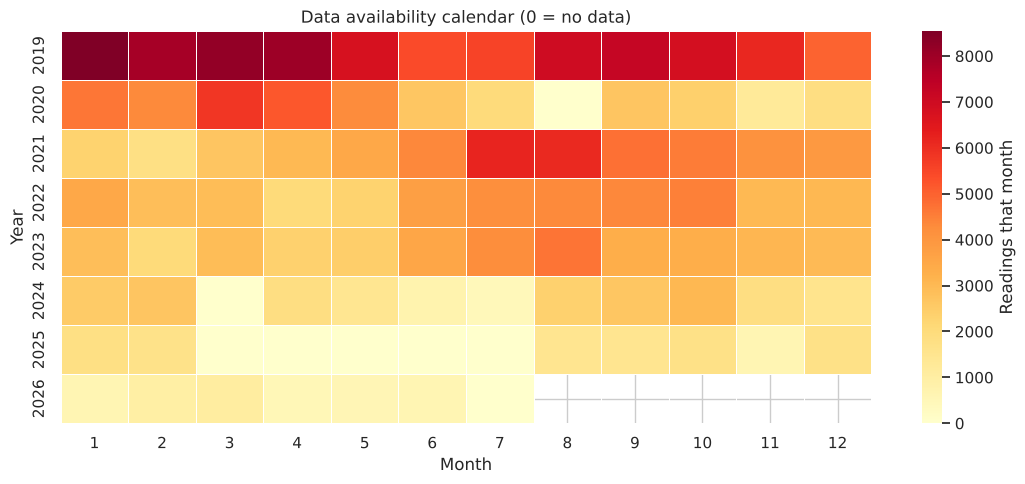

In [10]:
# Coverage calendar heatmap
fig, ax = plt.subplots(figsize=(11, 5))
cal = monthly_counts.copy()
cal.index = cal.index.to_timestamp()
cal_matrix = pd.DataFrame({
    'year': cal.index.year, 'month': cal.index.month, 'count': cal.values
}).pivot(index='year', columns='month', values='count')
cal_matrix = cal_matrix.reindex(columns=range(1, 13))
sns.heatmap(cal_matrix, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Readings that month'},
            linewidths=0.5, linecolor='white')
ax.set_title('Data availability calendar (0 = no data)')
ax.set_xlabel('Month'); ax.set_ylabel('Year')
plt.tight_layout(); plt.show()

### 6.3 Monthly mean PM2.5 with gaps preserved

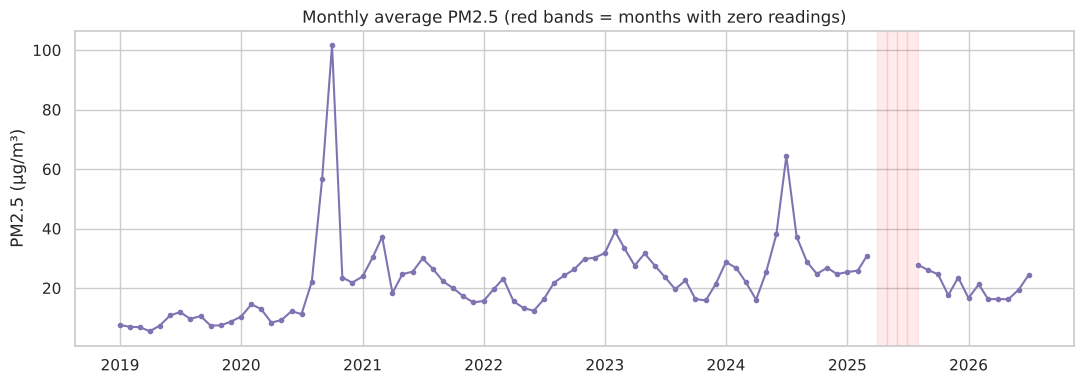

In [11]:
# Monthly mean with gaps left as breaks
monthly_mean = df_clean.set_index('DATETIME')['PM25'].resample('ME').mean()
monthly_mean.index = monthly_mean.index.to_period('M')
monthly_mean = monthly_mean.reindex(full_months)
monthly_mean.index = monthly_mean.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_mean.index, monthly_mean.values, marker='o', markersize=3, color='#8172B2')

# Shade missing months
for m in missing_months:
    start = m.to_timestamp()
    end = (m + 1).to_timestamp()
    ax.axvspan(start, end, color='red', alpha=0.08)

ax.set_title('Monthly average PM2.5 (red bands = months with zero readings)')
ax.set_ylabel('PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()

---
# Part B: Understanding the Data

## 7. Exploratory Data Analysis

**Goal:** describe distributions, relationships, time patterns, seasonality, space and sensor behaviour.

EDA is descriptive, so it uses the whole period. Read monthly and yearly views together with the coverage caveats from Section 6.

| Block | Sub-section | Question |
|---|---|---|
| Distributions | 7.1–7.2 | What do the variables look like and how do they correlate? |
| Time | 7.3–7.5, 7.10–7.11, 7.14 | Hourly, weekday, yearly, hour × weekday, month × hour, network trend |
| Season | 7.6 | Dry vs rainy |
| Space | 7.7, 7.12, 7.16 | Neighbourhoods, sensors, cross-sensor disagreement |
| Physics | 7.8–7.9 | Dust vs combustion, humidity effects |
| Structure | 7.13, 7.15 | Autocorrelation, sensor uptime |

### 7.1 Distributions

PM concentrations are heavily right-skewed: the median PM2.5 is about 13 µg/m³, but the tail runs to almost 1,000 µg/m³. On a linear axis every PM histogram collapses into one bar. The PM panels therefore use a **logarithmic x-axis over the full range**, so the bulk and the tail are both visible. Humidity and temperature are roughly bounded and stay linear.

* **Left:** histogram with a density curve; the vertical lines mark the median, 95th and 99th percentiles.
* **Right:** box plot with every point beyond the whiskers drawn, on the same axis as the histogram.

Readings below 0.5 µg/m³, mostly exact zeros, cannot be placed on a log axis. They are drawn at 0.5 and counted in each title.

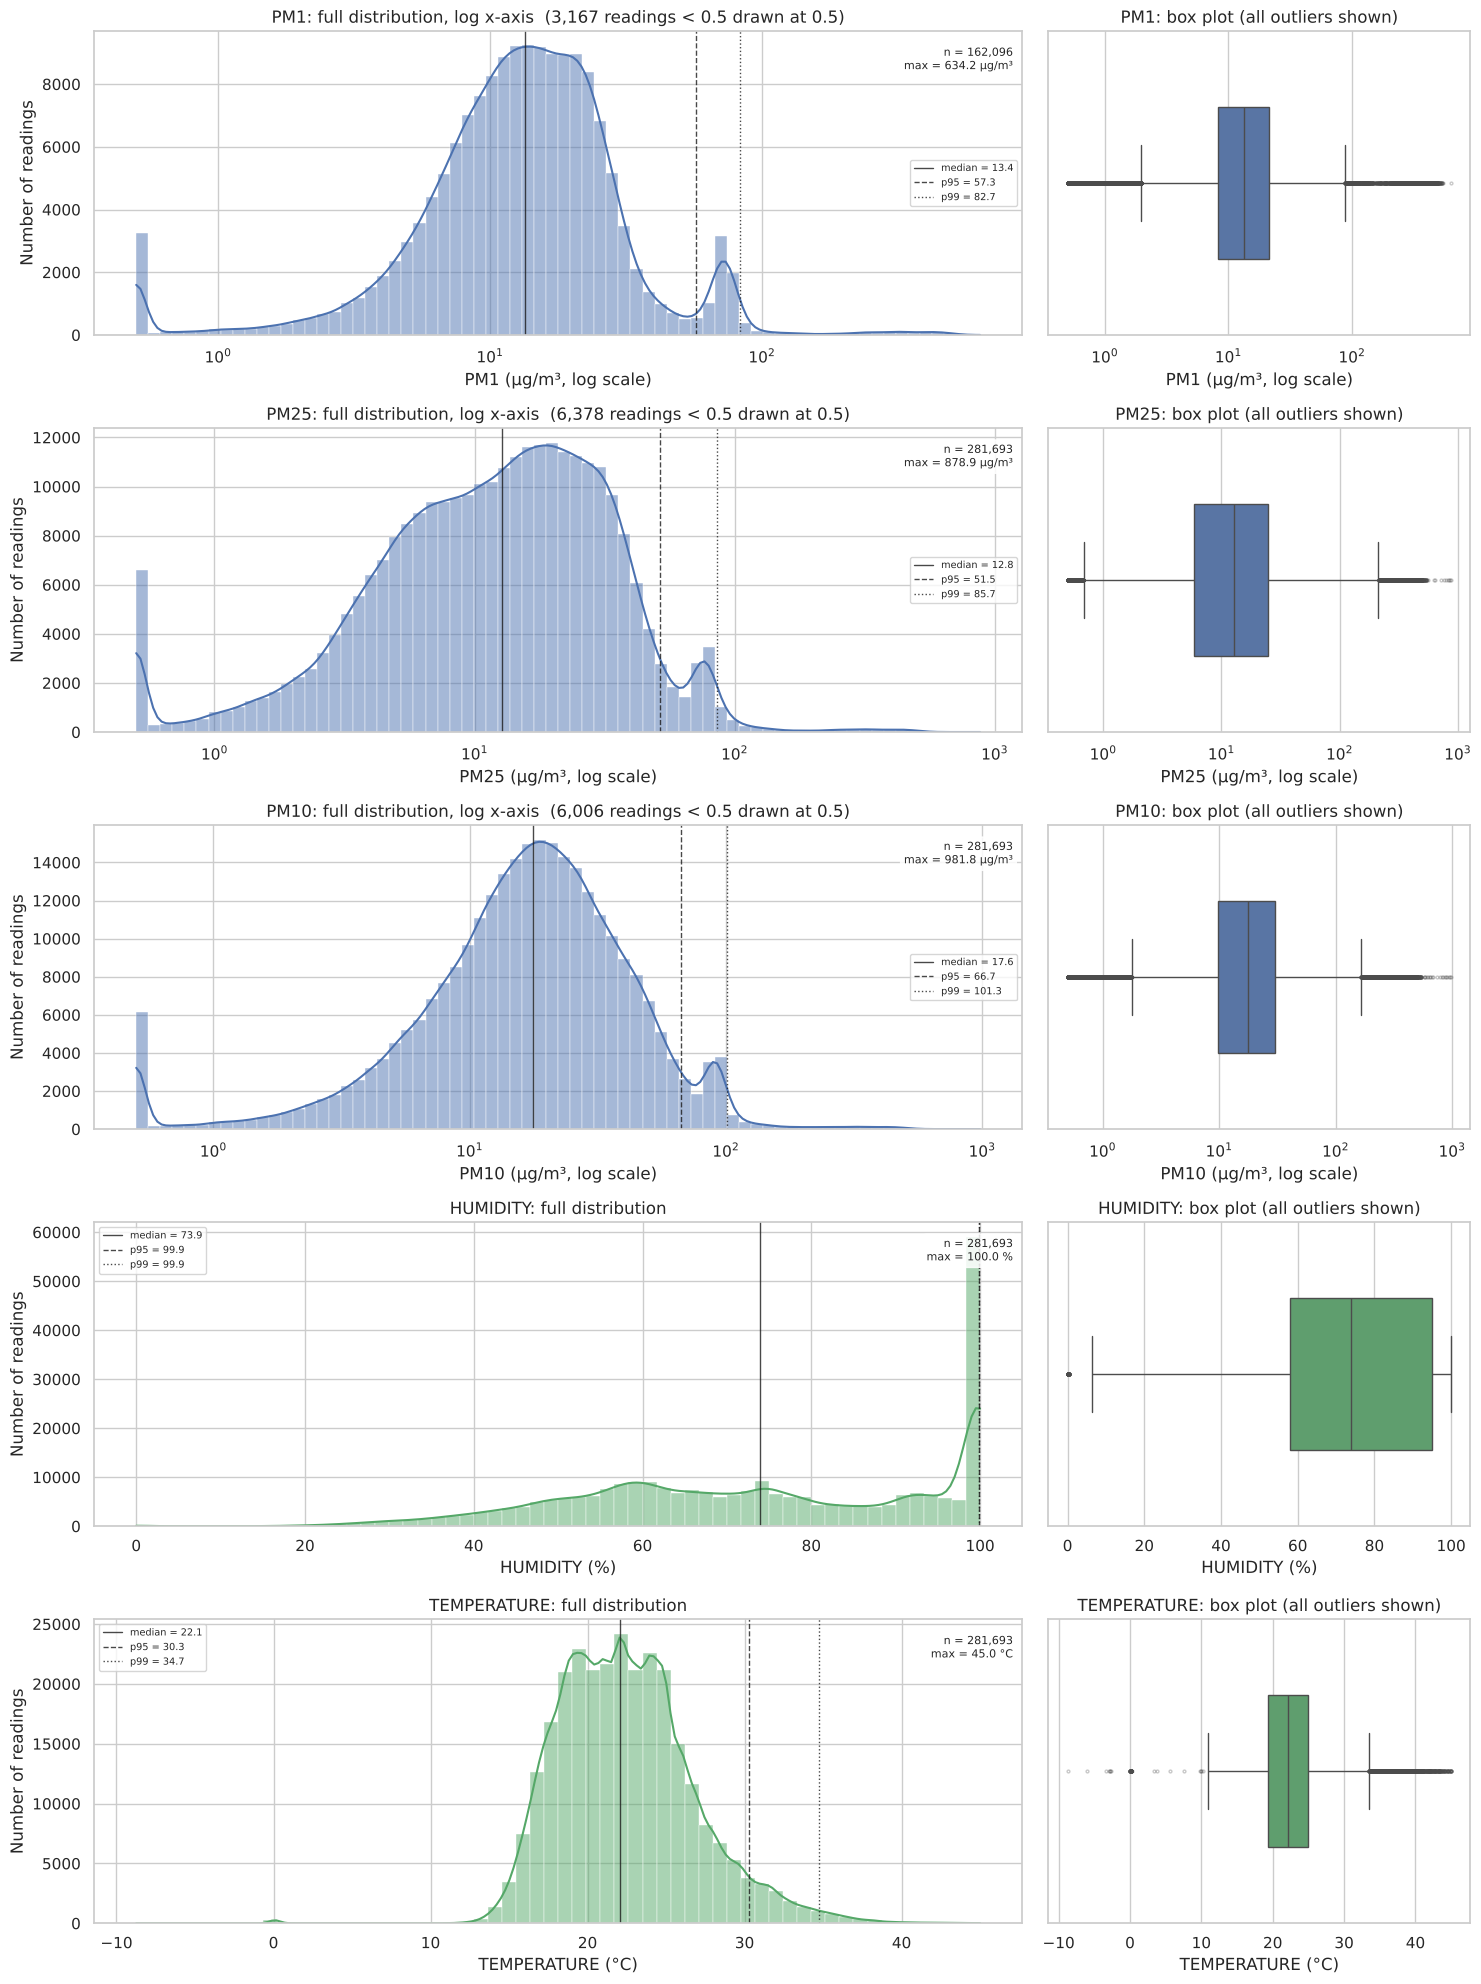

                count   mean    std   min     1%    25%    50%    75%    95%     99%     max  skew
PM1          162096.0  18.88  28.14  0.00   0.00   8.17  13.41  21.18  57.29   82.71  634.22  9.33
PM25         281693.0  18.93  25.72  0.00   0.00   5.88  12.80  24.70  51.47   85.73  878.90  8.79
PM10         281693.0  24.40  28.81  0.00   0.00   9.69  17.63  30.12  66.68  101.32  981.82  7.42
HUMIDITY     281693.0  73.90  20.57  0.00  28.20  57.96  73.94  94.93  99.90   99.90  100.00 -0.27
TEMPERATURE  281693.0  22.47   4.32 -8.74  14.81  19.29  22.09  25.00  30.29   34.73   45.00  0.54


In [12]:
# 7.1 Distributions (full range; log axis for the skewed PM variables)
cols = ['PM1', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE']
units = {'HUMIDITY': '%', 'TEMPERATURE': '°C'}
fig, axes = plt.subplots(len(cols), 2, figsize=(15, 4.0 * len(cols)),
                         gridspec_kw={'width_ratios': [2.2, 1]})
for r, c in enumerate(cols):
    ax_h, ax_b = axes[r]
    if c in PM_COLS:
        s, n_low = pm_for_log(df_clean[c])
        sns.histplot(s, bins=70, kde=True, log_scale=True, ax=ax_h, color='#4C72B0',
                     edgecolor='white', linewidth=0.3)
        sns.boxplot(x=s, ax=ax_b, color='#4C72B0', log_scale=True, width=0.5,
                    flierprops=dict(marker='o', markersize=2, alpha=0.3))
        ax_h.set_title(f'{c}: full distribution, log x-axis  ({n_low:,} readings < {PM_FLOOR} drawn at {PM_FLOOR})')
        ax_h.set_xlabel(f'{c} (µg/m³, log scale)'); ax_b.set_xlabel(f'{c} (µg/m³, log scale)')
        annotate_quantiles(ax_h, s, log=True)
    else:
        s = df_clean[c].dropna()
        sns.histplot(s, bins=60, kde=True, ax=ax_h, color='#55A868', edgecolor='white', linewidth=0.3)
        sns.boxplot(x=s, ax=ax_b, color='#55A868', width=0.5,
                    flierprops=dict(marker='o', markersize=2, alpha=0.3))
        ax_h.set_title(f'{c}: full distribution')
        ax_h.set_xlabel(f'{c} ({units[c]})'); ax_b.set_xlabel(f'{c} ({units[c]})')
        annotate_quantiles(ax_h, s, unit=units[c])
    ax_b.set_title(f'{c}: box plot (all outliers shown)')
    ax_h.set_ylabel('Number of readings')
plt.tight_layout(); plt.show()

# Numerical summary to read alongside the plots
summary = df_clean[cols].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T
summary['skew'] = df_clean[cols].skew()
print(summary.round(2).to_string())

### 7.2 Correlation matrix

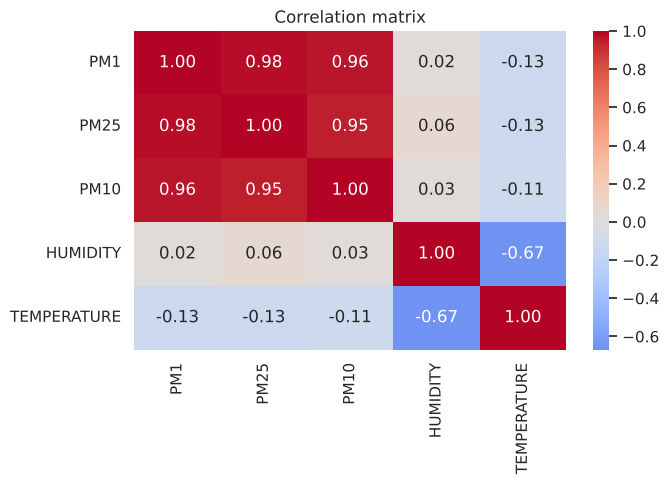

In [13]:
# 7.2 Correlation
corr = df_clean[cols].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix'); plt.tight_layout(); plt.show()

### 7.3 Hourly pattern

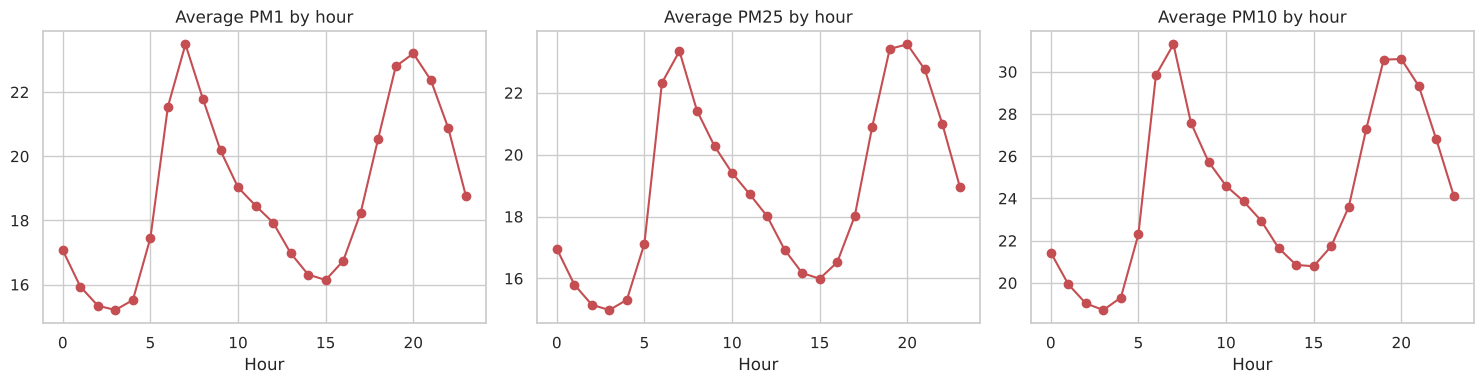

In [14]:
# 7.3 Hourly pattern
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ['PM1', 'PM25', 'PM10']):
    hourly = df_clean.groupby('HOUR')[c].mean()
    ax.plot(hourly.index, hourly.values, marker='o', color='#C44E52')
    ax.set_title(f'Average {c} by hour'); ax.set_xlabel('Hour')
plt.tight_layout(); plt.show()

### 7.4 Weekday pattern

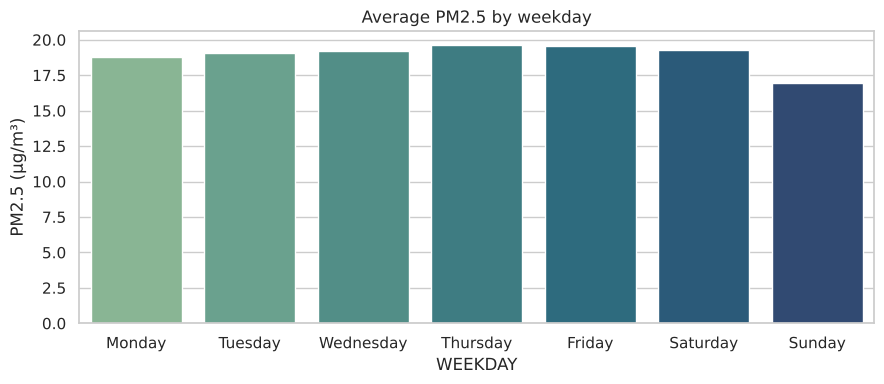

In [15]:
# 7.4 Weekday pattern
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
wk = df_clean.groupby('WEEKDAY')['PM25'].mean().reindex(weekday_order)
plt.figure(figsize=(9, 4))
sns.barplot(x=wk.index, y=wk.values, palette='crest')
plt.title('Average PM2.5 by weekday'); plt.ylabel('PM2.5 (µg/m³)')
plt.tight_layout(); plt.show()

### 7.5 Yearly trend (with coverage caveat)

Yearly means depend on how many months and sensors reported, so readings per year are drawn as bars underneath. The shaded band is the **interquartile range** (25th–75th percentile). The previous ± 1 standard deviation band went below zero because PM is skewed, which is impossible for a concentration.

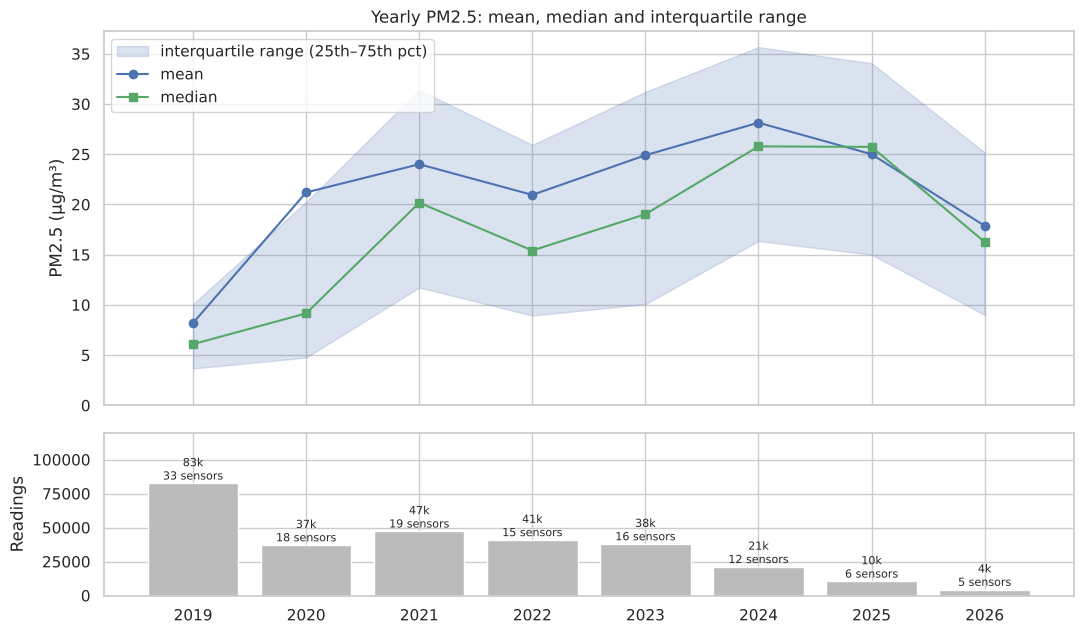

      mean  median   q25   q75  count  sensors
YEAR                                          
2019   8.2     6.1   3.7  10.1  82555       33
2020  21.2     9.2   4.8  20.2  37134       18
2021  24.0    20.2  11.7  31.4  47271       19
2022  21.0    15.4   8.9  25.9  40895       15
2023  24.9    19.0  10.1  31.2  37886       16
2024  28.1    25.8  16.4  35.7  21128       12
2025  25.0    25.7  15.0  34.1  10449        6
2026  17.9    16.3   9.0  25.2   4375        5


In [16]:
# 7.5 Yearly mean and median, interquartile band, readings per year
yearly = df_clean.groupby('YEAR')['PM25'].agg(
    mean='mean', median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
    count='count', sensors=lambda s: df_clean.loc[s.index, 'LOCATION'].nunique())
fig, (ax, axc) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [2.3, 1]})
ax.fill_between(yearly.index, yearly['q25'], yearly['q75'], alpha=0.2, color='#4C72B0',
                label='interquartile range (25th–75th pct)')
ax.plot(yearly.index, yearly['mean'], marker='o', label='mean', color='#4C72B0')
ax.plot(yearly.index, yearly['median'], marker='s', label='median', color='#55A868')
ax.set_ylim(bottom=0); ax.set_ylabel('PM2.5 (µg/m³)')
ax.set_title('Yearly PM2.5: mean, median and interquartile range'); ax.legend(loc='upper left')
bars = axc.bar(yearly.index, yearly['count'], color='#BBBBBB')
for x, (n, k) in zip(yearly.index, yearly[['count', 'sensors']].values):
    axc.text(x, n, f'{n/1000:.0f}k\n{k} sensors', ha='center', va='bottom', fontsize=8)
axc.set_ylabel('Readings'); axc.set_ylim(0, yearly['count'].max() * 1.45)
axc.set_xticks(yearly.index)
plt.tight_layout(); plt.show()
print(yearly.round(1).to_string())

### 7.6 Seasonal split (dry vs rainy)

Nairobi seasons: hot & dry (Jan–Feb), long rains (Mar–May), cool & dry (Jun–Sep), short rains (Oct–Dec). A one-sided Mann-Whitney test checks whether dry-season PM2.5 is higher.

> **Caution:** hourly readings are autocorrelated and sensors are repeated measures, so the p-value overstates the evidence. Read it alongside the effect size (median difference).

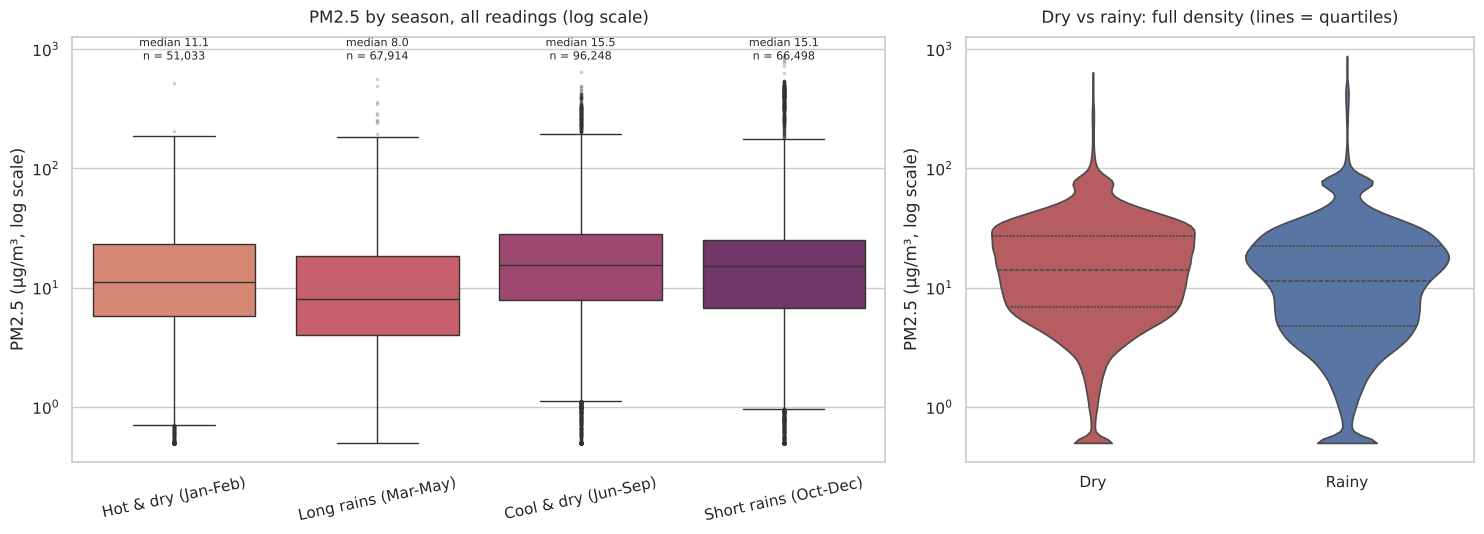

Dry median: 14.00 | Rainy median: 11.48
Mann-Whitney U=11,223,625,644, one-sided p=0.00e+00
Note: hourly readings are autocorrelated and sensors are repeated measures, so the p-value overstates evidence; read it alongside the effect size (median difference).


In [17]:
# 7.6 Seasonal split (log y-axis so whole distributions are visible, no clipping)
def assign_season(month):
    if month in [3, 4, 5]: return 'Long rains (Mar-May)'
    if month in [10, 11, 12]: return 'Short rains (Oct-Dec)'
    if month in [1, 2]: return 'Hot & dry (Jan-Feb)'
    return 'Cool & dry (Jun-Sep)'

df_clean['SEASON'] = df_clean['MONTH'].apply(assign_season)
df_clean['SEASON_SIMPLE'] = df_clean['SEASON'].apply(lambda s: 'Rainy' if 'rains' in s else 'Dry')

order = ['Hot & dry (Jan-Feb)', 'Long rains (Mar-May)', 'Cool & dry (Jun-Sep)', 'Short rains (Oct-Dec)']
season_plot = df_clean[['SEASON', 'SEASON_SIMPLE']].assign(PM25=df_clean['PM25'].clip(lower=PM_FLOOR))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.boxplot(data=season_plot, x='SEASON', y='PM25', order=order, hue='SEASON', legend=False, ax=axes[0],
            palette='flare', log_scale=True, flierprops=dict(marker='o', markersize=1.5, alpha=0.25))
for k, sname in enumerate(order):
    n = (season_plot['SEASON'] == sname).sum()
    med = season_plot.loc[season_plot['SEASON'] == sname, 'PM25'].median()
    axes[0].text(k, axes[0].get_ylim()[1], f'median {med:.1f}\nn = {n:,}', ha='center', va='top', fontsize=8)
axes[0].tick_params(axis='x', rotation=12)
axes[0].set_ylabel('PM2.5 (µg/m³, log scale)'); axes[0].set_xlabel('')
axes[0].set_title('PM2.5 by season, all readings (log scale)', pad=10)
sns.violinplot(data=season_plot, x='SEASON_SIMPLE', y='PM25', order=['Dry', 'Rainy'], hue='SEASON_SIMPLE',
               legend=False, palette=['#C44E52', '#4C72B0'], log_scale=True, cut=0, inner='quart', ax=axes[1])
axes[1].set_ylabel('PM2.5 (µg/m³, log scale)'); axes[1].set_xlabel('')
axes[1].set_title('Dry vs rainy: full density (lines = quartiles)', pad=10)
plt.tight_layout(); plt.show()

# Mann-Whitney test on dry vs rainy
dry_vals = df_clean.loc[df_clean['SEASON_SIMPLE']=='Dry', 'PM25'].dropna()
rainy_vals = df_clean.loc[df_clean['SEASON_SIMPLE']=='Rainy', 'PM25'].dropna()
u, p = mannwhitneyu(dry_vals, rainy_vals, alternative='greater')
print(f"Dry median: {dry_vals.median():.2f} | Rainy median: {rainy_vals.median():.2f}")
print(f"Mann-Whitney U={u:,.0f}, one-sided p={p:.2e}")
print("Note: hourly readings are autocorrelated and sensors are repeated measures, so the p-value "
      "overstates evidence; read it alongside the effect size (median difference).")

### 7.7 Spatial patterns: neighbourhoods

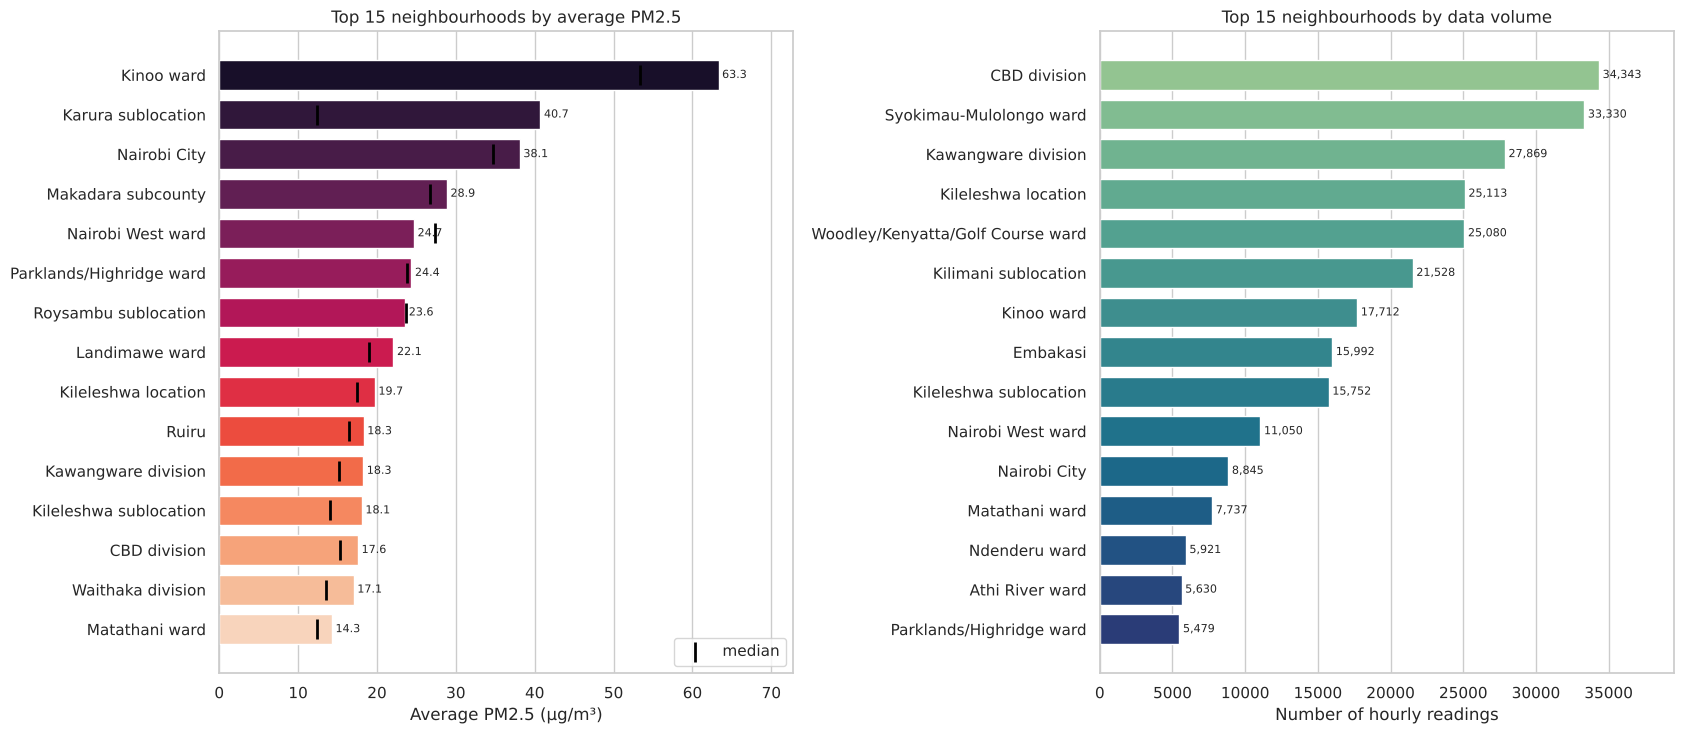

In [18]:
# 7.7 Spatial patterns (each label sits on its own bar; values printed at bar ends)
hood_mean = df_clean.groupby('NEIGHBORHOOD')['PM25'].agg(['mean', 'median', 'size'])
top_mean = hood_mean.sort_values('mean', ascending=False).head(15)
top_count = hood_mean.sort_values('size', ascending=False).head(15)
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, data, col, pal, xlabel, title, fmt in [
        (axes[0], top_mean, 'mean', 'rocket', 'Average PM2.5 (µg/m³)', 'Top 15 neighbourhoods by average PM2.5', '{:.1f}'),
        (axes[1], top_count, 'size', 'crest', 'Number of hourly readings', 'Top 15 neighbourhoods by data volume', '{:,.0f}')]:
    y = np.arange(len(data))
    ax.barh(y, data[col].values, color=sns.color_palette(pal, len(data)), height=0.75)
    ax.set_yticks(y, labels=data.index); ax.invert_yaxis()
    for yy, v in zip(y, data[col].values):
        ax.text(v, yy, ' ' + fmt.format(v), va='center', fontsize=8)
    ax.set_xlim(0, data[col].max() * 1.15); ax.set_xlabel(xlabel); ax.set_title(title)
    ax.grid(axis='y', visible=False)
axes[0].scatter(top_mean['median'], np.arange(len(top_mean)), marker='|', s=220, color='black',
                linewidths=2, label='median', zorder=3)
axes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

### 7.8 Dust vs combustion: PM2.5, PM10 and PM1

The PM2.5/PM10 ratio helps separate sources: a ratio near 1 suggests combustion (fine particles), below about 0.5 suggests coarse dust.

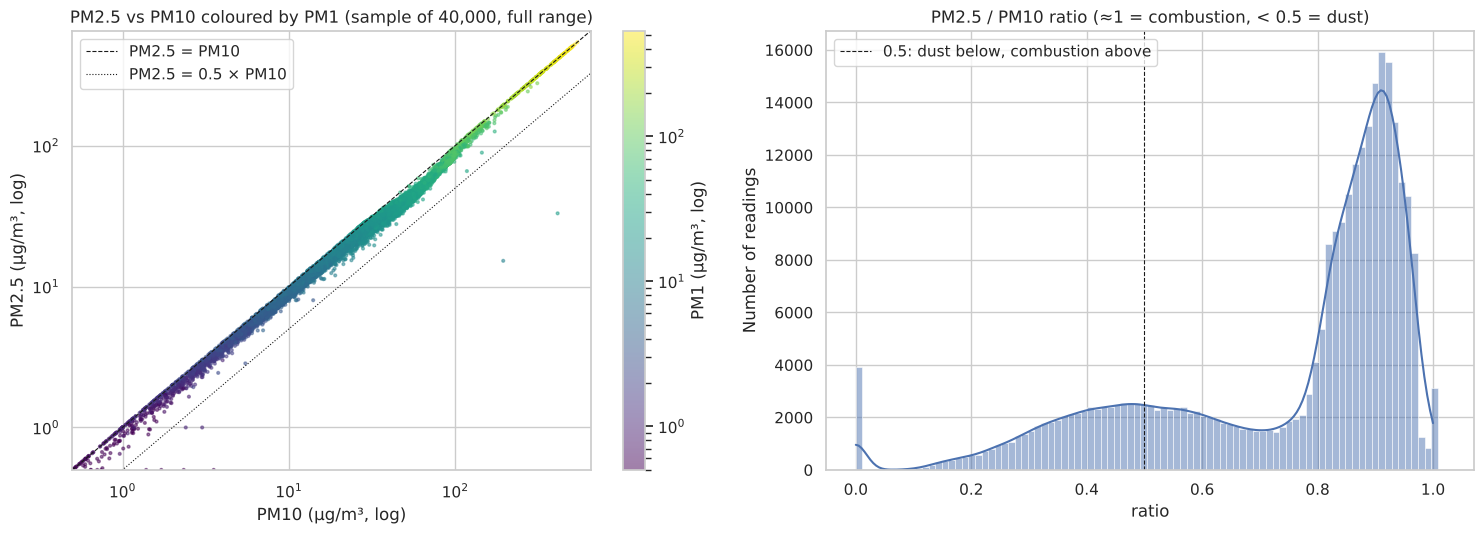

In [19]:
# 7.8 PM25 vs PM10 coloured by PM1: dust vs combustion (log-log, full range)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sub = df_clean.dropna(subset=['PM1']).sample(min(40000, df_clean['PM1'].notna().sum()), random_state=RANDOM_STATE)
x_, y_, c_ = (sub[k].clip(lower=PM_FLOOR) for k in ['PM10', 'PM25', 'PM1'])
sc = axes[0].scatter(x_, y_, c=c_, s=4, cmap='viridis', alpha=0.5, norm=matplotlib.colors.LogNorm())
lims = [PM_FLOOR, max(x_.max(), y_.max()) * 1.2]
axes[0].plot(lims, lims, 'k--', lw=0.8, label='PM2.5 = PM10')
axes[0].plot(lims, [l * 0.5 for l in lims], 'k:', lw=0.8, label='PM2.5 = 0.5 × PM10')
axes[0].set_xscale('log'); axes[0].set_yscale('log'); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel('PM10 (µg/m³, log)'); axes[0].set_ylabel('PM2.5 (µg/m³, log)')
axes[0].set_title(f'PM2.5 vs PM10 coloured by PM1 (sample of {len(sub):,}, full range)'); axes[0].legend(loc='upper left')
plt.colorbar(sc, ax=axes[0], label='PM1 (µg/m³, log)')

ratio = (df_clean['PM25'] / (df_clean['PM10'] + 1e-6)).dropna()
sns.histplot(ratio, bins=np.linspace(0, max(1.0, ratio.quantile(0.999)) + 0.02, 90), kde=True, ax=axes[1], color='#4C72B0')
axes[1].axvline(0.5, color='k', ls='--', lw=0.8, label='0.5: dust below, combustion above')
axes[1].set_title('PM2.5 / PM10 ratio (≈1 = combustion, < 0.5 = dust)')
axes[1].set_xlabel('ratio'); axes[1].set_ylabel('Number of readings'); axes[1].legend()
plt.tight_layout(); plt.show()

### 7.9 Humidity and temperature vs PM2.5

Low-cost optical sensors tend to over-read at high relative humidity (hygroscopic growth). Binned medians give a cleaner signal than the raw scatter.

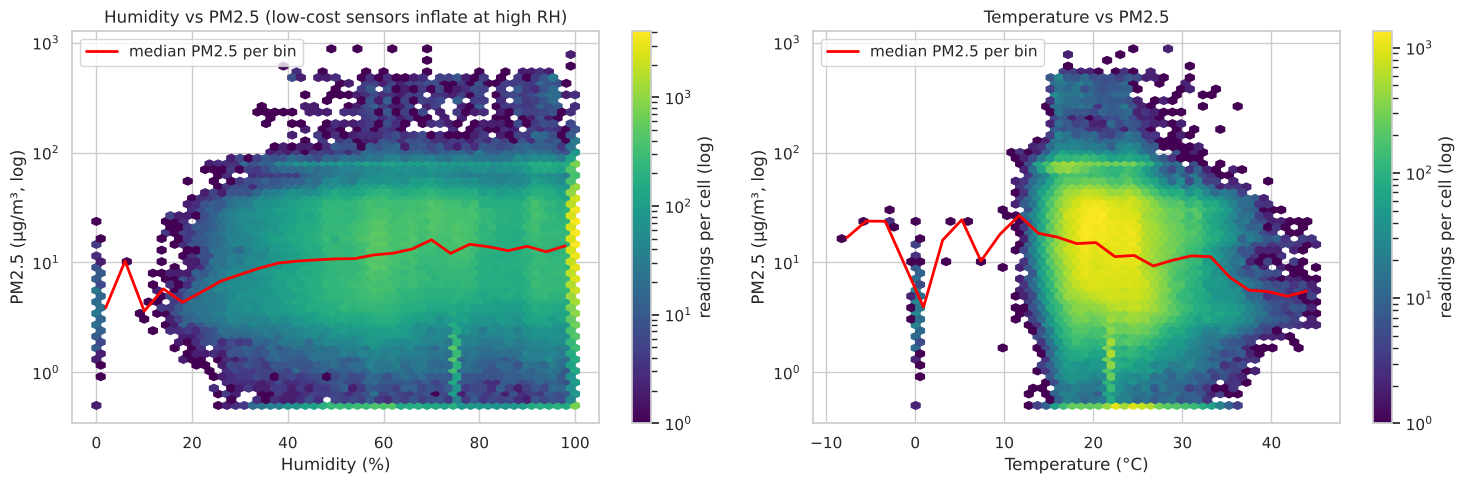

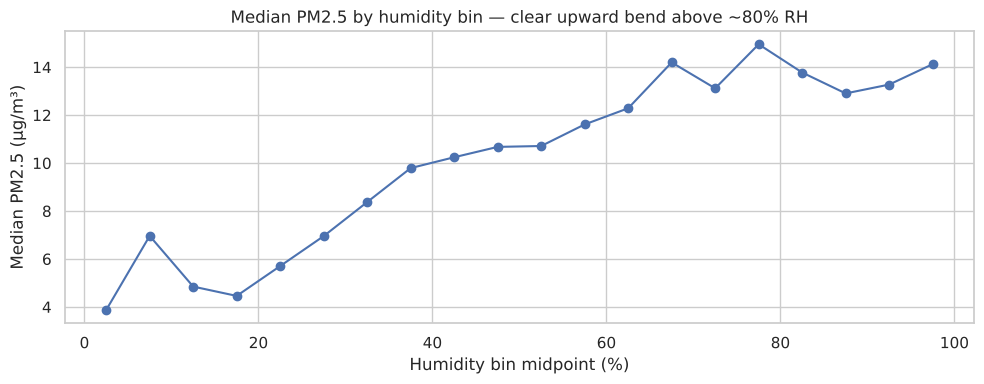

In [20]:
# 7.9 Humidity and temperature vs PM2.5: density (hexbin) over ALL readings, log PM axis
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, xcol, xlabel, title in [
        (axes[0], 'HUMIDITY', 'Humidity (%)', 'Humidity vs PM2.5 (low-cost sensors inflate at high RH)'),
        (axes[1], 'TEMPERATURE', 'Temperature (°C)', 'Temperature vs PM2.5')]:
    d_ = df_clean[[xcol, 'PM25']].dropna()
    hb = ax.hexbin(d_[xcol], d_['PM25'].clip(lower=PM_FLOOR), gridsize=55, yscale='log', bins='log',
                   cmap='viridis', mincnt=1)
    med = d_.groupby(pd.cut(d_[xcol], 25), observed=True)['PM25'].median()
    ax.plot([iv.mid for iv in med.index], med.values, color='red', lw=2, label='median PM2.5 per bin')
    ax.set_xlabel(xlabel); ax.set_ylabel('PM2.5 (µg/m³, log)'); ax.set_title(title); ax.legend(loc='upper left')
    plt.colorbar(hb, ax=ax, label='readings per cell (log)')
plt.tight_layout(); plt.show()

# Binned medians (cleaner signal than raw scatter)
rh_bins = pd.cut(df_clean['HUMIDITY'], bins=np.arange(0, 105, 5))
rh_prof = df_clean.groupby(rh_bins, observed=True)['PM25'].agg(['median', 'size'])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot([iv.mid for iv in rh_prof.index], rh_prof['median'].values, marker='o', color='#4C72B0')
ax.set_xlabel('Humidity bin midpoint (%)'); ax.set_ylabel('Median PM2.5 (µg/m³)')
ax.set_title('Median PM2.5 by humidity bin — clear upward bend above ~80% RH')
plt.tight_layout(); plt.show()

### 7.10 Weekday × hour heatmap

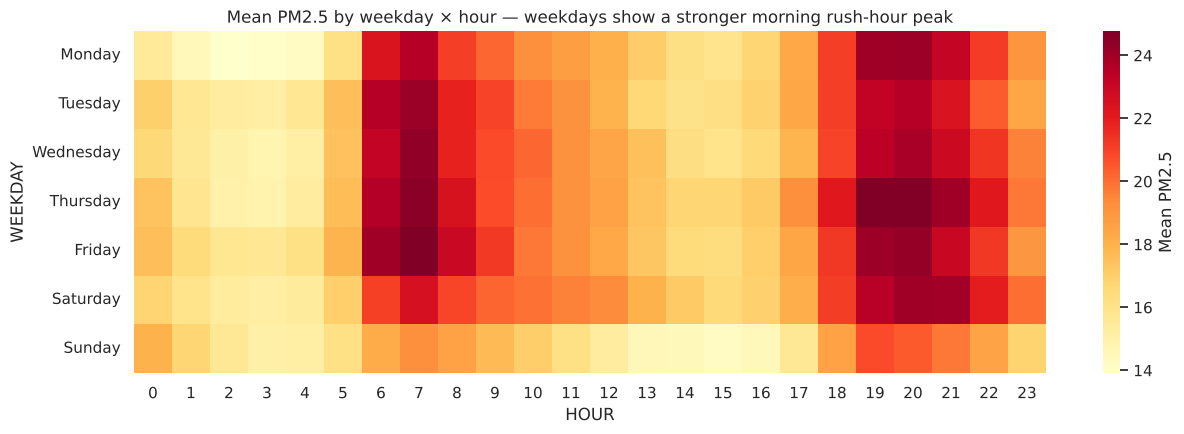

In [21]:
# 7.10 Hour × Weekday heatmap
wd_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
pivot_mean = df_clean.pivot_table(index='WEEKDAY', columns='HOUR', values='PM25', aggfunc='mean').reindex(wd_order)
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(pivot_mean, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Mean PM2.5'})
ax.set_title('Mean PM2.5 by weekday × hour — weekdays show a stronger morning rush-hour peak')
plt.tight_layout(); plt.show()

### 7.11 Month × hour heatmap (seasonal × diurnal structure, local time)

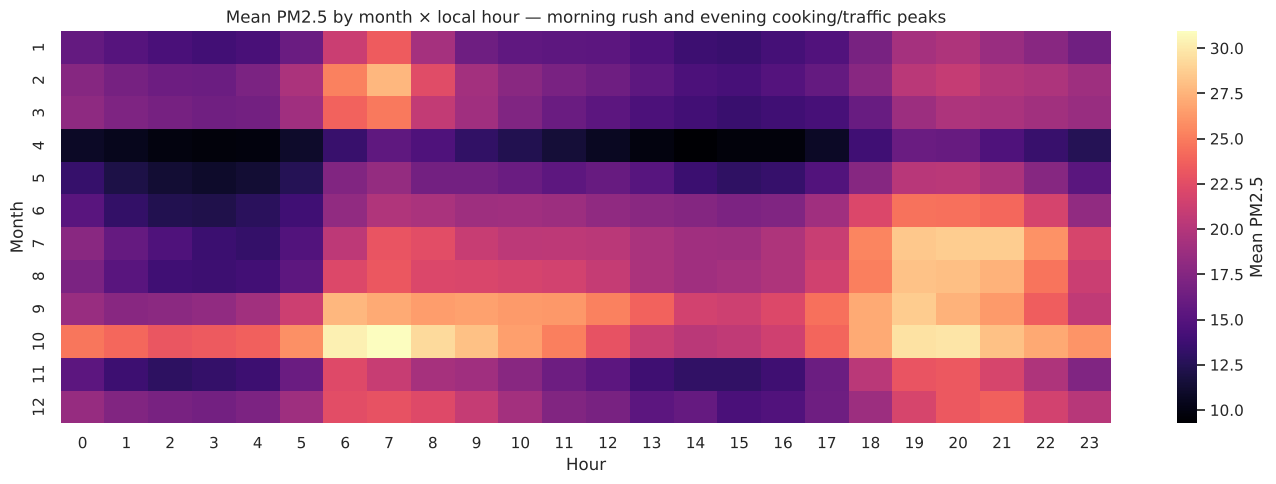

In [22]:
# 7.11 Month × Hour heatmap — seasonal × diurnal structure
pivot_mh = df_clean.pivot_table(index='MONTH', columns='HOUR', values='PM25', aggfunc='mean')
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot_mh, cmap='magma', ax=ax, cbar_kws={'label': 'Mean PM2.5'})
ax.set_title('Mean PM2.5 by month × local hour — morning rush and evening cooking/traffic peaks')
ax.set_xlabel('Hour'); ax.set_ylabel('Month')
plt.tight_layout(); plt.show()

### 7.12 Sensor-level distributions (top 20 by volume)

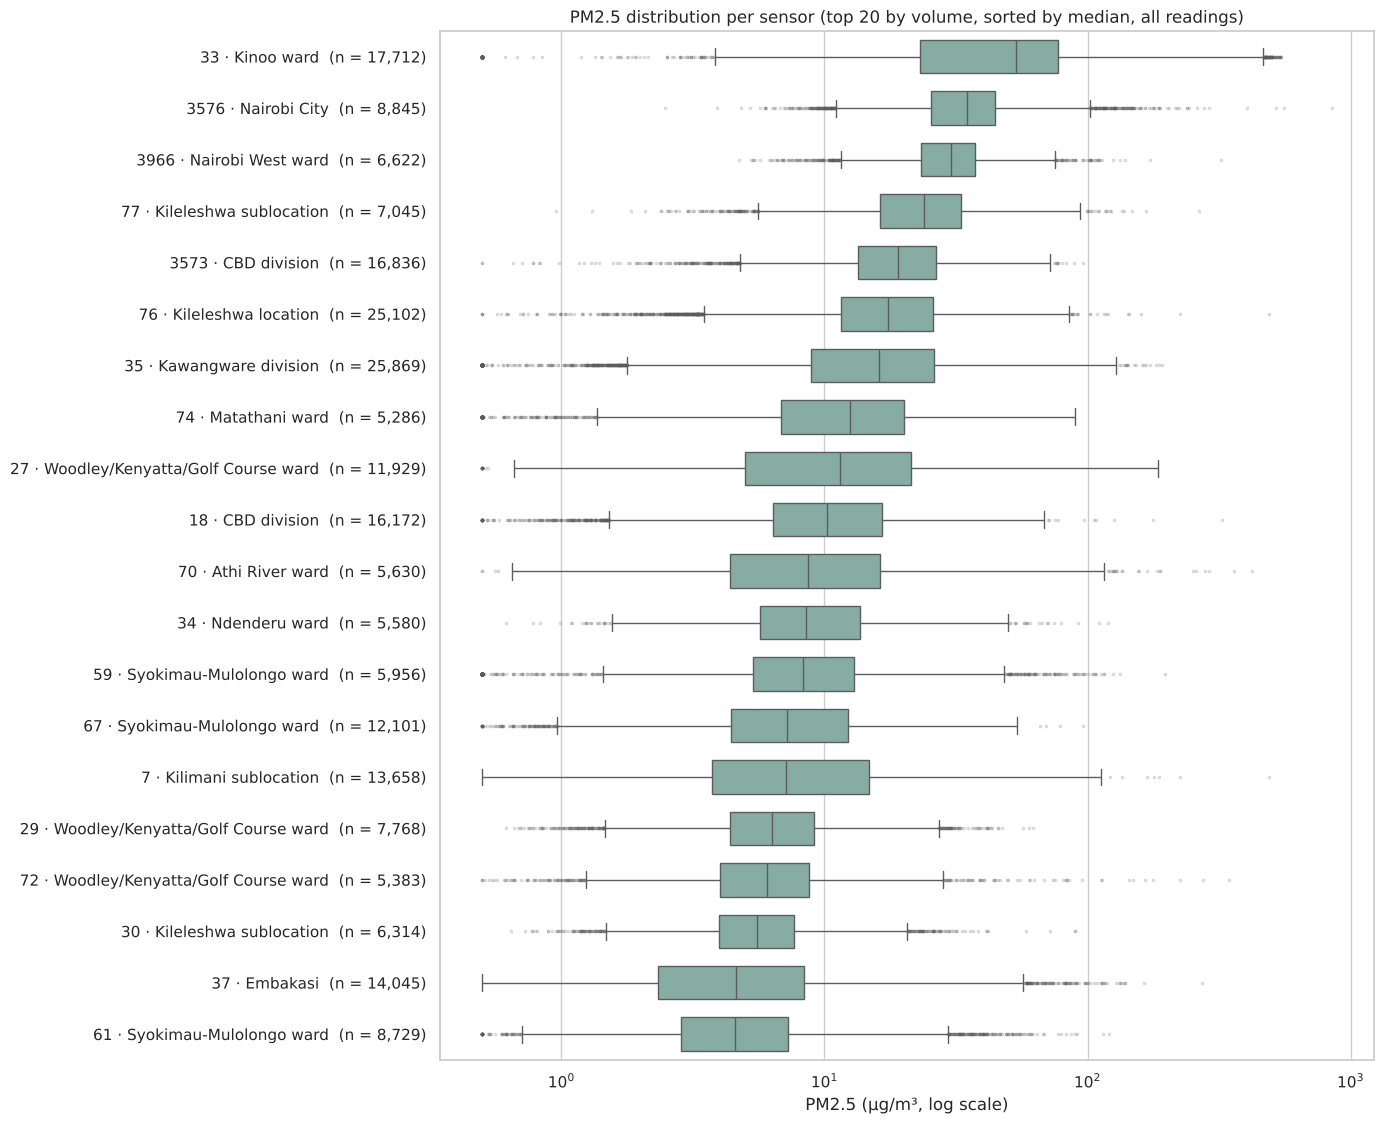

In [23]:
# 7.12 Sensor-level distributions (top 20 by volume, log scale, all readings shown)
# Horizontal layout: each "sensor · neighbourhood" label sits directly beside its own box.
top_sensors = df_clean['LOCATION'].value_counts().head(20).index
hood_of = df_clean.groupby('LOCATION')['NEIGHBORHOOD'].first()
sub = df_clean[df_clean['LOCATION'].isin(top_sensors)].assign(PM25=lambda d: d['PM25'].clip(lower=PM_FLOOR))
order_sensors = sub.groupby('LOCATION')['PM25'].median().sort_values(ascending=False).index
sub['sensor'] = sub['LOCATION'].map(lambda s: f'{s} · {hood_of[s]}')
order_labels = [f'{s} · {hood_of[s]}' for s in order_sensors]
n_per = sub['sensor'].value_counts()
fig, ax = plt.subplots(figsize=(14, 0.48 * len(order_labels) + 1.8))
sns.boxplot(data=sub, y='sensor', x='PM25', order=order_labels, color='#7FB3A6', ax=ax, log_scale=True,
            width=0.65, flierprops=dict(marker='o', markersize=1.5, alpha=0.25))
ax.set_yticks(range(len(order_labels)), labels=[f'{l}  (n = {n_per[l]:,})' for l in order_labels])
ax.set_xlabel('PM2.5 (µg/m³, log scale)'); ax.set_ylabel('')
ax.set_title('PM2.5 distribution per sensor (top 20 by volume, sorted by median, all readings)')
plt.tight_layout(); plt.show()

### 7.13 Autocorrelation (justifies the rolling windows)

ACF/PACF of the busiest sensor show how long PM2.5 "remembers" its past, which motivates the 6, 24 and 72-hour windows in Section 8.

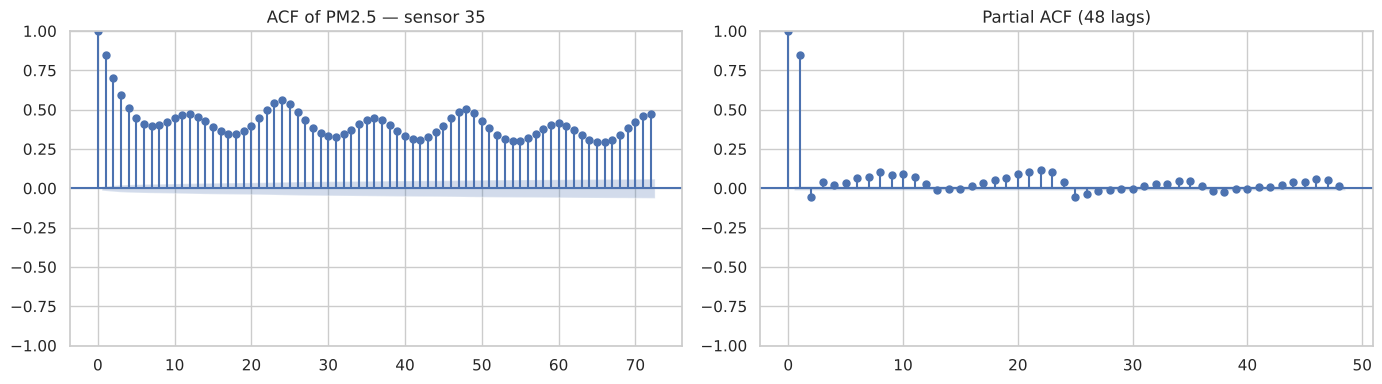

In [24]:
# 7.13 Autocorrelation of PM2.5 (helps justify rolling windows)
one_sensor = df_clean['LOCATION'].value_counts().index[0]
s_ts = (df_clean[df_clean['LOCATION'] == one_sensor]
        .sort_values('DATETIME')
        .set_index('DATETIME')['PM25'].asfreq('h').interpolate(limit=6).dropna())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(s_ts.values, lags=72, ax=axes[0], title=f'ACF of PM2.5 — sensor {one_sensor}')
plot_pacf(s_ts.values, lags=48, ax=axes[1], title='Partial ACF (48 lags)')
plt.tight_layout(); plt.show()

### 7.14 Network-wide trend (7-day rolling median)

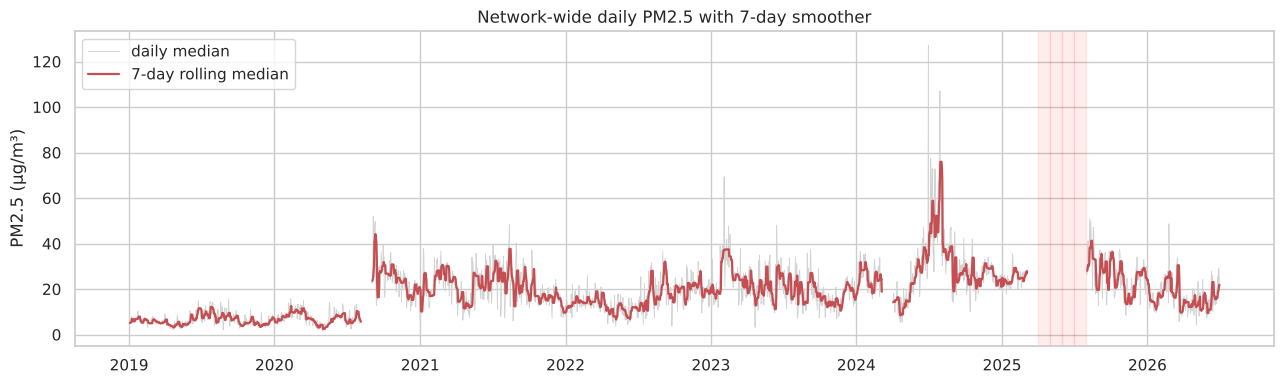

In [25]:
# 7.14 7-day rolling median over the whole period (network view)
daily = df_clean.set_index('DATETIME')['PM25'].resample('D').median()
roll7 = daily.rolling(7, min_periods=3).median()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(daily.index, daily.values, color='lightgrey', lw=0.6, label='daily median')
ax.plot(roll7.index, roll7.values, color='#C44E52', lw=1.6, label='7-day rolling median')
for m in missing_months:
    ax.axvspan(m.to_timestamp(), (m + 1).to_timestamp(), color='red', alpha=0.07)
ax.set_ylabel('PM2.5 (µg/m³)'); ax.legend(); ax.set_title('Network-wide daily PM2.5 with 7-day smoother')
plt.tight_layout(); plt.show()

### 7.15 Sensor × month coverage (uptime)

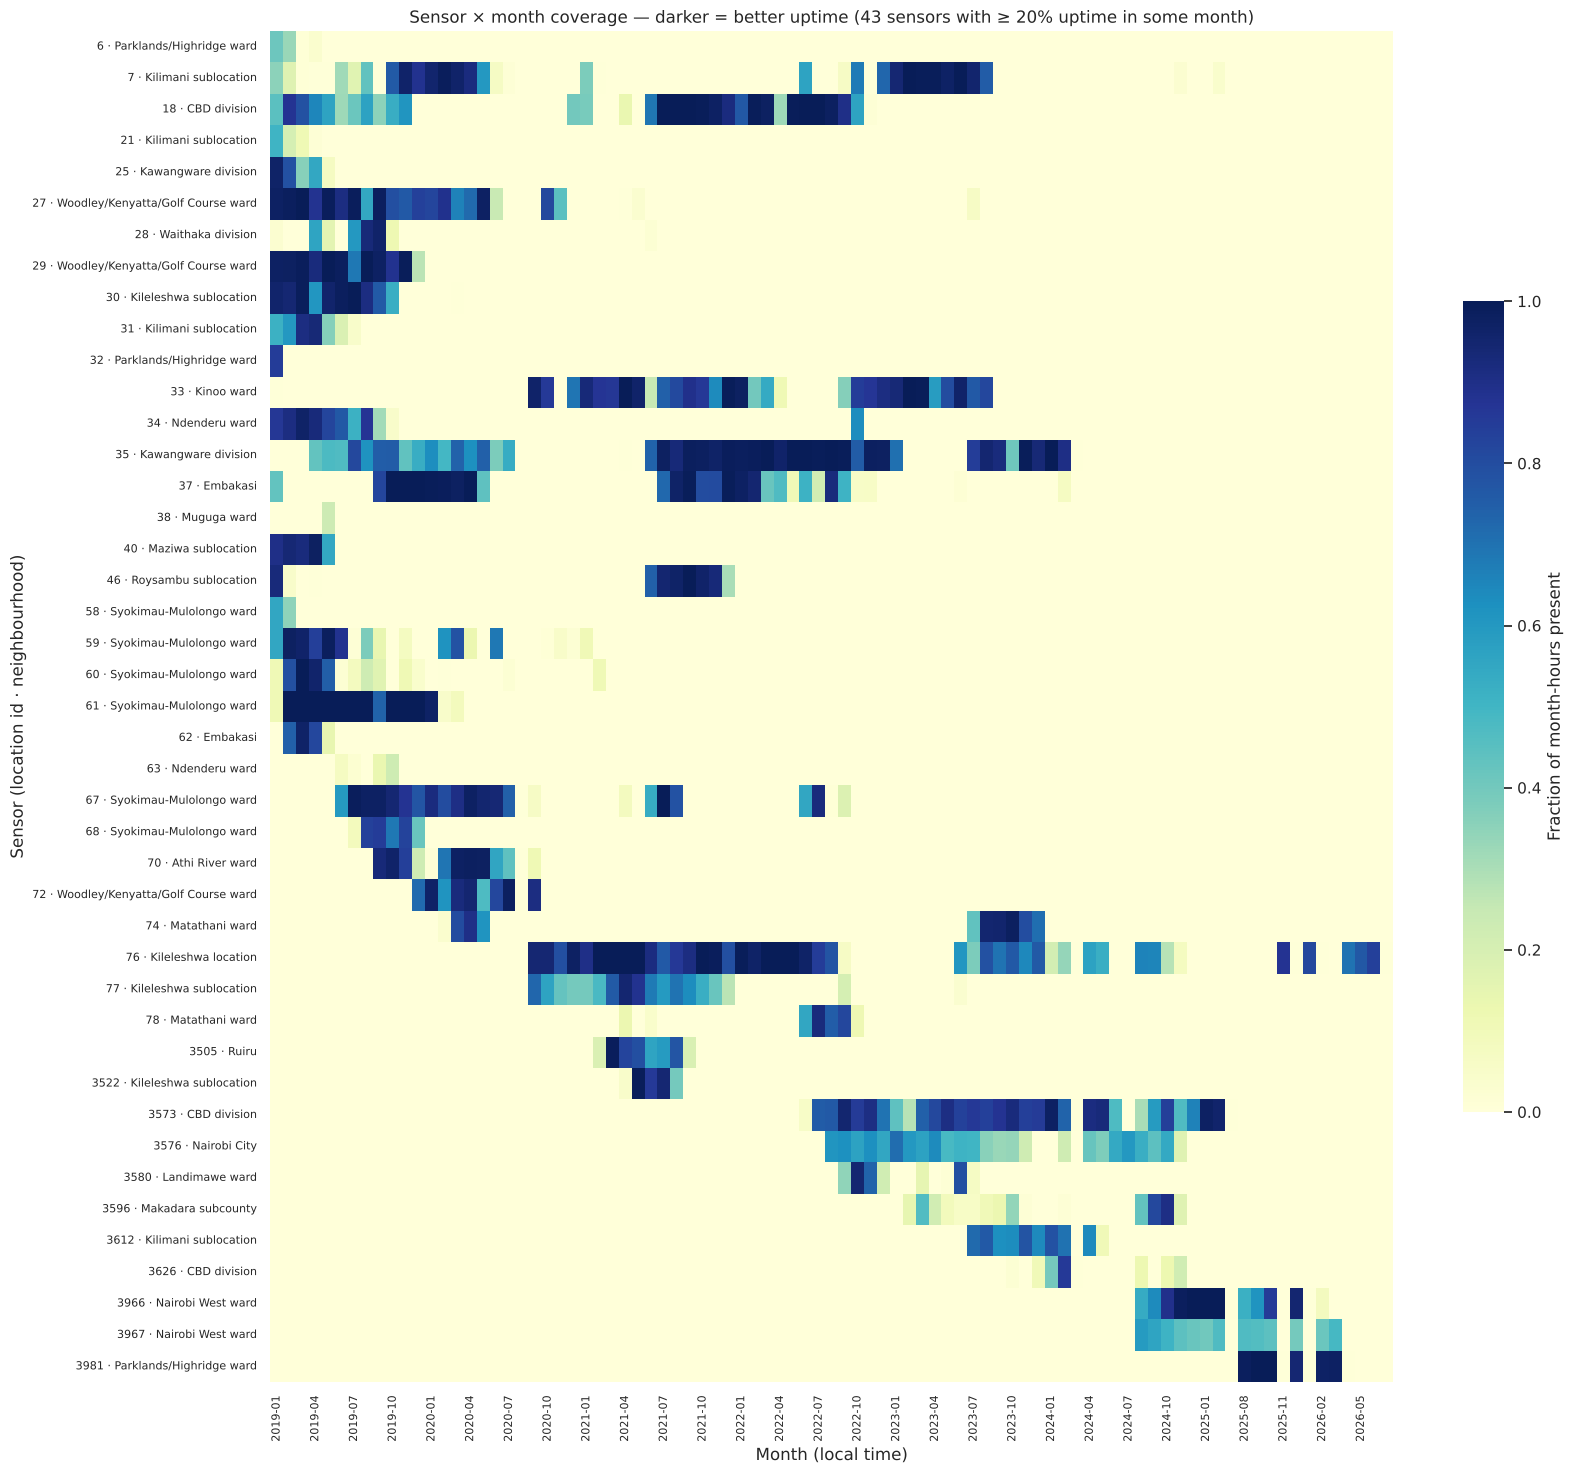

In [26]:
# 7.15 Missingness heatmap — sensor × month (share of hours present), every sensor labelled
tmp = df_clean.copy()
tmp['month'] = tmp['DATETIME'].dt.to_period('M')
coverage = tmp.groupby(['LOCATION', 'month']).size().unstack(fill_value=0)
hours_in_month = pd.Series({m: m.days_in_month * 24 for m in coverage.columns})
coverage_rate = coverage.div(hours_in_month, axis=1).clip(0, 1)
keep = coverage_rate.max(axis=1) > 0.2
cov = coverage_rate[keep]
fig, ax = plt.subplots(figsize=(17, max(6, 0.3 * len(cov) + 2)))
sns.heatmap(cov, cmap='YlGnBu', ax=ax, yticklabels=True, xticklabels=3, linewidths=0,
            cbar_kws={'label': 'Fraction of month-hours present', 'shrink': 0.6})
ax.set_yticklabels([f'{s} · {hood_of[s]}' for s in cov.index], fontsize=8, rotation=0)
ax.set_xticklabels([str(cov.columns[int(t.get_text())]) if t.get_text().isdigit() else t.get_text()
                    for t in ax.get_xticklabels()], rotation=90, fontsize=8)
ax.set_xlabel('Month (local time)'); ax.set_ylabel('Sensor (location id · neighbourhood)')
ax.set_title(f'Sensor × month coverage — darker = better uptime ({len(cov)} sensors with ≥ 20% uptime in some month)')
plt.tight_layout(); plt.show()

### 7.16 Cross-sensor disagreement

How much do sensors in the same neighbourhood disagree in the same hour? Large spread points to faulty sensors or very local sources, and motivates the cross-sensor features and corroboration check used later.

Spread can only be computed where **at least two sensors** reported in the same neighbourhood and hour, so the second chart includes only neighbourhoods with at least 100 such hours. Neighbourhood names sit on the vertical axis, each level with its own box, sorted by median spread. The histogram uses a log x-axis so the long tail is visible.

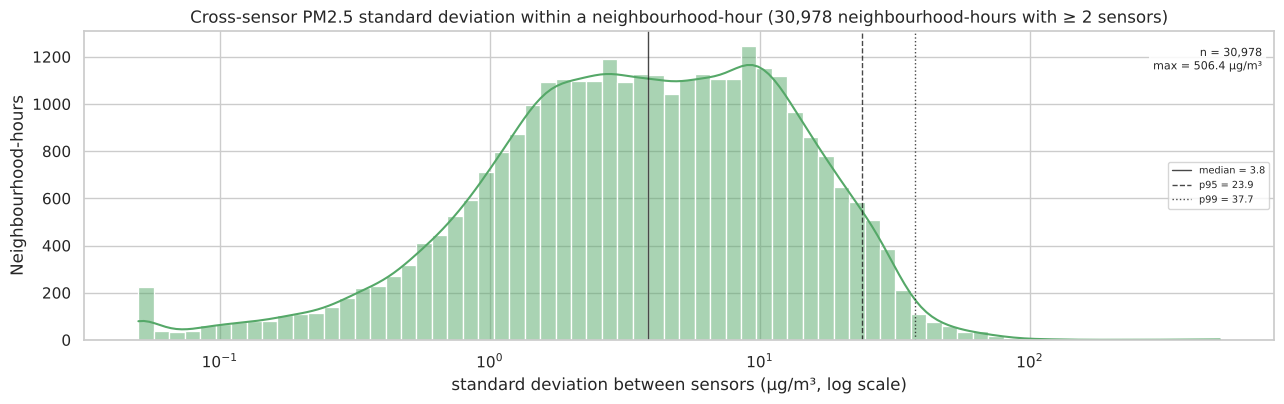

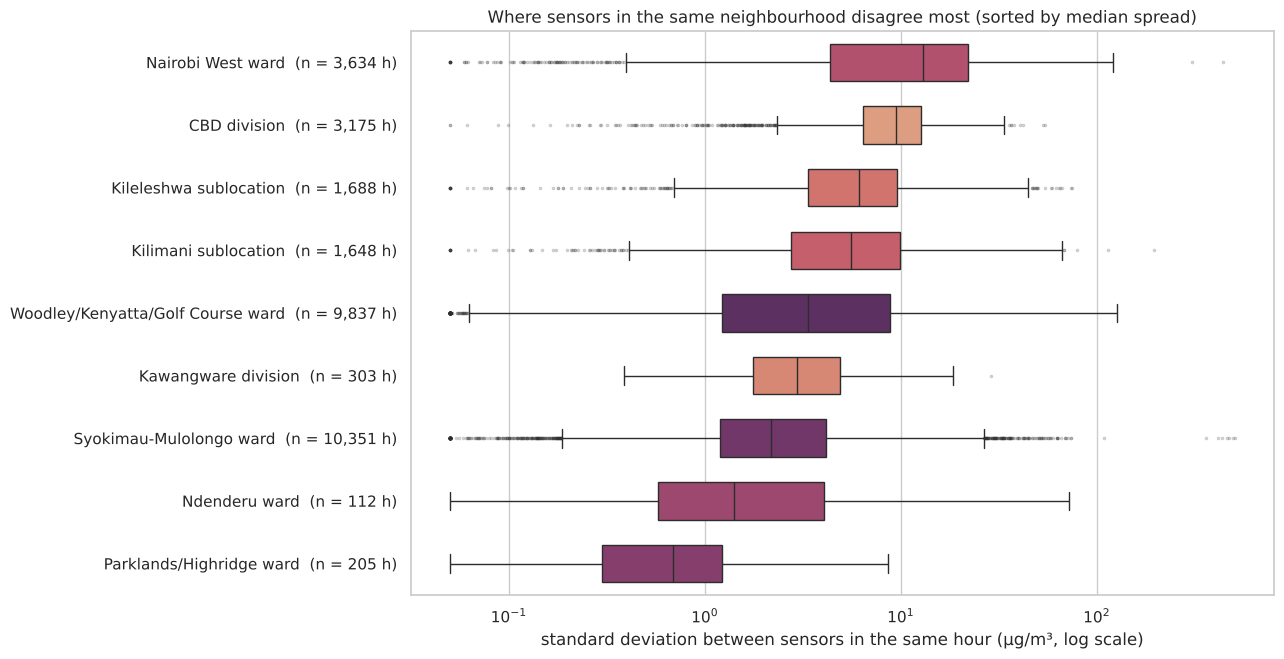

                                     count    50%    90%     max
NEIGHBORHOOD                                                    
Nairobi West ward                   3634.0  12.99  27.69  438.56
CBD division                        3175.0   9.47  16.27   54.72
Kileleshwa sublocation              1688.0   6.16  14.51   75.11
Kilimani sublocation                1648.0   5.57  16.72  195.61
Woodley/Kenyatta/Golf Course ward   9837.0   3.35  16.51  127.02
Kawangware division                  303.0   2.95   8.56   28.73
Syokimau-Mulolongo ward            10351.0   2.19   8.25  506.42
Ndenderu ward                        112.0   1.41  14.63   72.66
Parklands/Highridge ward             205.0   0.69   2.02    8.65


In [27]:
# 7.16 Cross-sensor disagreement (same neighbourhood & hour)
hood_std_df = (df_clean.groupby(['NEIGHBORHOOD', 'DATETIME'])['PM25'].agg(['std', 'size'])
               .query('size >= 2').reset_index().rename(columns={'std': 'pm25_std'}))
hood_std_df['pm25_std_plot'] = hood_std_df['pm25_std'].clip(lower=0.05)

# (a) overall distribution of the spread
fig, ax = plt.subplots(figsize=(13, 4.2))
s = hood_std_df['pm25_std_plot']
sns.histplot(s, bins=70, log_scale=True, kde=True, ax=ax, color='#55A868')
annotate_quantiles(ax, s, log=True)
ax.set_title(f'Cross-sensor PM2.5 standard deviation within a neighbourhood-hour '
             f'({len(s):,} neighbourhood-hours with ≥ 2 sensors)')
ax.set_xlabel('standard deviation between sensors (µg/m³, log scale)'); ax.set_ylabel('Neighbourhood-hours')
plt.tight_layout(); plt.show()

# (b) by neighbourhood — horizontal so every name lines up with its own box
counts = hood_std_df['NEIGHBORHOOD'].value_counts()
eligible = counts[counts >= 100].index
d_ = hood_std_df[hood_std_df['NEIGHBORHOOD'].isin(eligible)]
order_h = d_.groupby('NEIGHBORHOOD')['pm25_std'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(13, 0.55 * len(order_h) + 1.8))
sns.boxplot(data=d_, y='NEIGHBORHOOD', x='pm25_std_plot', order=order_h, hue='NEIGHBORHOOD', legend=False,
            palette='flare', log_scale=True, width=0.6, flierprops=dict(marker='o', markersize=1.5, alpha=0.25), ax=ax)
ax.set_yticks(range(len(order_h)), labels=[f'{h}  (n = {counts[h]:,} h)' for h in order_h])
ax.set_xlabel('standard deviation between sensors in the same hour (µg/m³, log scale)'); ax.set_ylabel('')
ax.set_title('Where sensors in the same neighbourhood disagree most (sorted by median spread)')
plt.tight_layout(); plt.show()
print(d_.groupby('NEIGHBORHOOD')['pm25_std'].describe(percentiles=[.5, .9]).loc[order_h]
      [['count', '50%', '90%', 'max']].round(2).to_string())

---
# Part C: Modelling

## 8. Feature Engineering

**Goal:** build the model inputs that do not depend on a fitted baseline.

### Features built here

| Feature | Definition | Leakage-safe because |
|---|---|---|
| `pm25_roll_mean_{6,24,72}` | Rolling mean of past PM2.5 per sensor | Uses `shift(1)`, so the current reading is excluded |
| `pm25_roll_std_{6,24,72}` | Rolling std of past PM2.5 per sensor | Same |
| `pm25_pm10_ratio` | PM2.5 / PM10 | Same-row quantity |
| `hood_hour_mean`, `hood_hour_std` | Mean / std of PM2.5 across sensors in the same neighbourhood and hour | Contemporaneous; legitimate at scoring time because all sensors report together |
| `hood_deviation` | PM2.5 minus `hood_hour_mean` | Same |

### Decisions
- **No cyclical hour/weekday/month encodings.** Removing them changed validation PR-AUC by under 0.01 (0.9319 → 0.9234 in the previous run), and the seasonal baseline in Section 10 already conditions on hour and weekday.
- **Convention:** every rolling window ends *before* the scoring timestamp.
- `baseline` and `residual` depend on a fitted baseline and are therefore built in Section 10, after the split.

In [28]:
# ============================================================
# 8. FEATURE ENGINEERING
# ============================================================
# Rolling features per sensor — PAST ONLY (shift(1) excludes the current reading)
df_clean = df_clean.sort_values(['LOCATION', 'DATETIME'])
past_pm25 = df_clean.groupby('LOCATION')['PM25'].shift(1)
past_pm25 = past_pm25.groupby(df_clean['LOCATION'])
for w in [6, 24, 72]:
    df_clean[f'pm25_roll_mean_{w}'] = past_pm25.transform(lambda x: x.rolling(w, min_periods=1).mean())
    df_clean[f'pm25_roll_std_{w}']  = past_pm25.transform(lambda x: x.rolling(w, min_periods=2).std())

# Ratios
df_clean['pm25_pm10_ratio'] = df_clean['PM25'] / (df_clean['PM10'] + 1e-6)

# Cross-sensor features at same neighbourhood and hour
df_clean['hood_hour_mean'] = df_clean.groupby(['NEIGHBORHOOD', 'DATETIME'])['PM25'].transform('mean')
df_clean['hood_hour_std']  = df_clean.groupby(['NEIGHBORHOOD', 'DATETIME'])['PM25'].transform('std')
df_clean['hood_deviation'] = df_clean['PM25'] - df_clean['hood_hour_mean']

print(f"Feature columns after engineering: {df_clean.shape[1]}")

Feature columns after engineering: 36


## 9. Leakage-Safe Splits

**Goal:** split the data so that no evaluation row can influence anything that was fitted.

| Split | Period | Role |
|---|---|---|
| **Train** | `< 2024-01-01` | Fit baseline, scalers, detectors, STL thresholds, meta-model |
| **Validation** | `2024-01-01` to `< 2025-01-01` | Choose the operating threshold, run diagnostics, compute SHAP |
| **Test** | `>= 2025-01-01` | **Locked** until the final evaluation (Section 13.5) |

**Design notes**
- Sensors appear in every period (what a deployed monitor would see), so the **temporal split is the primary leakage guard**.
- Within the training set, cross-validation uses **`GroupKFold` by sensor**, so checks are not inflated by sensor-specific memorisation.
- Everything fitted from here on uses `train` only.

> Boundaries are in **Nairobi local time** (e.g. the validation year starts at 2024-01-01 00:00 EAT = 2023-12-31 21:00 UTC).

In [29]:
# ============================================================
# 9. SPLITS
# ============================================================
train = df_clean[df_clean['DATETIME'] <  TRAIN_END].copy().reset_index(drop=True)
val   = df_clean[(df_clean['DATETIME'] >= TRAIN_END) & (df_clean['DATETIME'] < VAL_END)].copy().reset_index(drop=True)
test  = df_clean[df_clean['DATETIME'] >= VAL_END].copy().reset_index(drop=True)

for name, d in [('train', train), ('val', val), ('test', test)]:
    assert 'LOCATION' in d.columns
    print(f"{name:5s}: {len(d):,} rows | sensors={d['LOCATION'].nunique()} | "
          f"{d['DATETIME'].min()} → {d['DATETIME'].max()}")

assert len(train) > 0 and len(val) > 0 and len(test) > 0, "One of the splits is empty — check split dates."

train: 245,741 rows | sensors=47 | 2019-01-01 03:00:00 → 2023-12-31 23:00:00
val  : 21,128 rows | sensors=12 | 2024-01-01 00:00:00 → 2024-12-31 23:00:00
test : 14,824 rows | sensors=7 | 2025-01-01 00:00:00 → 2026-07-01 02:00:00


## 10. Seasonal Baseline and Residual Construction

**Goal:** turn "high PM2.5" into "unusual for this place and time".

An anomaly is not a high raw value; it is a **deviation from what is normal for that neighbourhood, hour and weekday**. A robust baseline (median) is computed **from the training period only**, and the residual `PM25 − baseline` becomes the primary anomaly signal.

**Fallback chain for unseen combinations**

`neighbourhood × hour × weekday` → `neighbourhood × hour` → global training median

> Because the baseline is fitted on `train`, training residuals are slightly smaller than validation/test residuals. That is expected and honest.

In [30]:
# ============================================================
# 10. SEASONAL BASELINE (fit on train only)
# ============================================================
base_keys = ['NEIGHBORHOOD', 'HOUR', 'WEEKDAY']
tbl3 = train.groupby(base_keys)['PM25'].median()
tbl2 = train.groupby(['NEIGHBORHOOD', 'HOUR'])['PM25'].median()
glob_median = train['PM25'].median()

def add_baseline(d):
    d = d.copy()
    b3 = tbl3.reindex(pd.MultiIndex.from_frame(d[base_keys])).values
    b2 = tbl2.reindex(pd.MultiIndex.from_frame(d[['NEIGHBORHOOD', 'HOUR']])).values
    b = np.where(np.isnan(b3), b2, b3)
    b = np.where(np.isnan(b), glob_median, b)
    d['baseline'] = b
    d['residual'] = d['PM25'] - d['baseline']
    return d

train = add_baseline(train)
val   = add_baseline(val)
test  = add_baseline(test)

print(train[['PM25', 'baseline', 'residual']].describe().round(3))
print("\nValidation residual summary:")
print(val['residual'].describe().round(3))

             PM25    baseline    residual
count  245741.000  245741.000  245741.000
mean       17.900      14.824       3.076
std        26.453      12.654      22.432
min         0.000       0.000    -190.971
25%         5.461       6.727      -3.866
50%        11.312      10.837       0.000
75%        22.260      17.441       6.889
max       878.902     198.811     875.460

Validation residual summary:
count    21128.000
mean        11.053
std         18.365
min        -48.045
25%          0.740
50%          8.788
75%         18.925
max        818.484
Name: residual, dtype: float64


## 11. Base Anomaly Detectors

**Goal:** produce five independent opinions on whether each reading is anomalous, then combine them into a consensus pseudo-label.

| # | Paradigm | Method | Input | Sub-section |
|---|---|---|---|---|
| 1 | Statistical | Median/MAD z-score | `residual` | 11.1 |
| 2 | Density | Local Outlier Factor | 6 scaled features | 11.2 |
| 3 | Kernel | One-Class SVM (Nystroem + SGD) | 6 scaled features | 11.3 |
| 4 | Clustering | DBSCAN noise rule (KD-tree) | 6 scaled features | 11.4 |
| 5 | Time series | STL residual, per-sensor MAD | PM2.5 series | 11.5 |

**Rules**
- Each detector is fit on the **full training set only** (no subsampling), then applied to train, validation and test.
- Two scalable choices make full-data fitting possible: the kernel detector is a Nystroem-approximated RBF One-Class SVM trained with SGD (an exact RBF One-Class SVM is quadratic in rows), and DBSCAN's noise rule is evaluated exactly with KD-tree distances instead of building the full neighbourhood graph.
- **Consensus label:** a reading is a pseudo-positive when **≥ 3 of 5** detectors flag it (11.6).

### 11.1 Statistical detector: MAD on the residual

Modified z-score `0.6745 × (x − median) / MAD`, flagged when `|z| > 3.5`. Median and MAD come from the training residuals.

In [31]:
# ============================================================
# 11.1 STATISTICAL: MAD on residual (parameters from train)
# ============================================================
res_med = train['residual'].median()
res_mad = np.median(np.abs(train['residual'] - res_med))

def mad_flag(x, med=res_med, mad=res_mad, threshold=3.5):
    if mad == 0:
        return pd.Series(0, index=x.index)
    z = 0.6745 * (x - med) / mad
    return (np.abs(z) > threshold).astype(int)

for d in [train, val, test]:
    d['stat_flag'] = mad_flag(d['residual'])
print(f"Stat flag rate — train: {train['stat_flag'].mean():.4f}, val: {val['stat_flag'].mean():.4f}")

Stat flag rate — train: 0.0721, val: 0.1357


### 11.2 Density detector: Local Outlier Factor

LOF in novelty mode (`contamination=0.01`, 20 neighbours) on six robust-scaled features. The scaler and the NaN fill values come from the training set.

In [32]:
# ============================================================
# 11.2 DENSITY: LOF
# ============================================================
feature_cols = ['PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE', 'HOUR', 'residual']
train_medians = train[feature_cols].median()
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(train[feature_cols].fillna(train_medians))
X_val_scaled   = scaler.transform(val[feature_cols].fillna(train_medians))
X_test_scaled  = scaler.transform(test[feature_cols].fillna(train_medians))

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01, novelty=True)
lof.fit(X_train_scaled)
train['lof_flag'] = (lof.predict(X_train_scaled) == -1).astype(int)
val['lof_flag']   = (lof.predict(X_val_scaled)   == -1).astype(int)
test['lof_flag']  = (lof.predict(X_test_scaled)  == -1).astype(int)
print(f"LOF flag rate — train: {train['lof_flag'].mean():.4f}, val: {val['lof_flag'].mean():.4f}")

LOF flag rate — train: 0.0084, val: 0.0207


### 11.3 Kernel detector: One-Class SVM

A Nystroem RBF feature map (200 components) feeds an SGD One-Class SVM (`nu=0.01`), which scales to the full training set.

In [33]:
# ============================================================
# 11.3 KERNEL: One-Class SVM
# ============================================================
# Nystroem RBF feature map + SGD one-class SVM: scales to the full training set
gamma_scale = 1.0 / (X_train_scaled.shape[1] * X_train_scaled.var())
ocsvm = Pipeline([
    ('nystroem', Nystroem(kernel='rbf', gamma=gamma_scale, n_components=200, random_state=RANDOM_STATE)),
    ('svm',      SGDOneClassSVM(nu=0.01, tol=1e-4, max_iter=1000, random_state=RANDOM_STATE)),
])
ocsvm.fit(X_train_scaled)
train['svm_flag'] = (ocsvm.predict(X_train_scaled) == -1).astype(int)
val['svm_flag']   = (ocsvm.predict(X_val_scaled)   == -1).astype(int)
test['svm_flag']  = (ocsvm.predict(X_test_scaled)  == -1).astype(int)
print(f"SVM flag rate — train: {train['svm_flag'].mean():.4f}, val: {val['svm_flag'].mean():.4f}")

SVM flag rate — train: 0.0101, val: 0.0106


### 11.4 Clustering detector: DBSCAN (exact noise rule)

A point is a DBSCAN **core point** iff its `min_samples`-th nearest neighbour (itself included) lies within `eps`. For any split, a reading is flagged as noise when it is farther than `eps` from every training core point. Parameters: `eps = 0.8`, `min_samples = 10`.

In [34]:
# ============================================================
# 11.4 CLUSTERING: DBSCAN (exact noise rule, full training set)
# ============================================================
eps_value, min_samples_val = 0.8, 10

def batched(fn, X, size=20_000):
    return np.concatenate([fn(X[i:i + size]) for i in range(0, len(X), size)])

# A point is a DBSCAN core point iff its min_samples-th nearest neighbour (itself included) lies within eps.
train_tree = KDTree(X_train_scaled)
kth_dist = batched(lambda b: train_tree.query(b, k=min_samples_val)[0][:, -1], X_train_scaled)
core_mask = kth_dist <= eps_value
print(f"DBSCAN core points: {core_mask.sum():,} of {len(core_mask):,} training rows")

# DBSCAN noise = not a core point and not within eps of any core point.
# Scoring rule for any split: flagged if farther than eps from every training core point.
if core_mask.sum() > 0:
    core_tree = KDTree(X_train_scaled[core_mask])
    def dbscan_flag(X):
        return (batched(lambda b: core_tree.query(b, k=1)[0][:, 0], X) > eps_value).astype(int)
    train['dbscan_flag'] = dbscan_flag(X_train_scaled)
    val['dbscan_flag']   = dbscan_flag(X_val_scaled)
    test['dbscan_flag']  = dbscan_flag(X_test_scaled)
else:
    print("DBSCAN found no core points — try a larger eps. Flags set to 0.")
    for d in [train, val, test]:
        d['dbscan_flag'] = 0
print(f"DBSCAN flag rate — train: {train['dbscan_flag'].mean():.4f}, val: {val['dbscan_flag'].mean():.4f}")

DBSCAN core points: 243,993 of 245,741 training rows


DBSCAN flag rate — train: 0.0041, val: 0.0082


### 11.5 Time-series detector: STL residual

**Step 1: decompose.** STL is a two-sided smoother, so each split gets its own decomposition. Validation and test residuals never use training-period data to shape their trend or seasonality (and vice versa). Within a split, STL runs on unbroken segments per sensor (a gap > 1 day starts a new segment; segments shorter than 48 hours are skipped).

In [35]:
# ============================================================
# 11.5 TIME-SERIES: STL residual (segment-aware, one STL per split)
# ============================================================
# STL is a two-sided smoother, so each split gets its own decomposition: validation/test
# residuals never use training-period data to shape their trend or seasonality (and vice versa).
# Within a split, STL is fit on unbroken segments per sensor (a gap > 1 day starts a new segment).
def stl_on_segments(df_sensor, period=24, min_len=2*24):
    df_sensor = df_sensor.sort_values('DATETIME').copy()
    gap = df_sensor['DATETIME'].diff() > pd.Timedelta('1D')
    df_sensor['segment'] = gap.cumsum()

    results = []
    for seg_id, seg in df_sensor.groupby('segment'):
        seg = seg.copy()
        seg['stl_trend'] = np.nan
        seg['stl_seasonal'] = np.nan
        seg['stl_resid'] = np.nan
        if len(seg) >= min_len:
            try:
                res = STL(seg['PM25'].astype(float).values, period=period, robust=True).fit()
                seg['stl_trend']    = res.trend
                seg['stl_seasonal'] = res.seasonal
                seg['stl_resid']    = res.resid
            except Exception:
                pass
        results.append(seg)
    return pd.concat(results)

def run_stl(d):
    parts = []
    for loc_id, g in d.groupby('LOCATION', sort=False):
        try:
            parts.append(stl_on_segments(g))
        except Exception as e:
            print(f"STL failed for LOCATION={loc_id}: {e}")
            g = g.copy()
            g['stl_trend'] = g['stl_seasonal'] = g['stl_resid'] = np.nan
            parts.append(g)
    return pd.concat(parts).sort_index()

train = run_stl(train)
val   = run_stl(val)
test  = run_stl(test)

for name, d in [('train', train), ('val', val), ('test', test)]:
    print(f"{name} STL residual coverage: {d['stl_resid'].notna().mean():.3f}")

train STL residual coverage: 0.985
val STL residual coverage: 0.986
test STL residual coverage: 0.994


**Step 2: threshold.** Per-sensor median/MAD of the **training** STL residuals are applied to every split (`|z| > 3.5`). Sensors with too few training residuals or zero MAD get no STL flag.

In [36]:
# STL flag: per-sensor median/MAD of the TRAINING STL residuals, applied to every split
stl_params = {}
for loc_id, g in train.groupby('LOCATION'):
    r = g['stl_resid'].dropna()
    if len(r) >= 24:
        med = r.median()
        mad = np.median(np.abs(r - med))
        if mad > 0:
            stl_params[loc_id] = (med, mad)

def stl_flag(d, threshold=3.5):
    flag = np.zeros(len(d), dtype=int)
    resid = d['stl_resid'].values
    for loc_id, pos in d.groupby('LOCATION').indices.items():
        if loc_id in stl_params:
            med, mad = stl_params[loc_id]
            z = 0.6745 * (resid[pos] - med) / mad
            flag[pos] = (np.abs(z) > threshold).astype(int)   # NaN compares False
    return flag

for d in [train, val, test]:
    d['stl_flag'] = stl_flag(d)
print(f"STL flag rate — train: {train['stl_flag'].mean():.4f}, val: {val['stl_flag'].mean():.4f}")
print(f"Sensors with usable STL parameters: {len(stl_params)} of {train['LOCATION'].nunique()}")

STL flag rate — train: 0.1298, val: 0.1435
Sensors with usable STL parameters: 42 of 47


### 11.6 Base votes and consensus pseudo-label

`base_votes` counts how many of the five detectors flag a reading; `pseudo_label = 1` when `base_votes ≥ 3`. This is the training target for the meta-model.

> There is no ground-truth anomaly label. Every label-based metric later in the notebook therefore measures **how well the detector consensus is reproduced**, not accuracy against truth.

In [37]:
# ============================================================
# 11.6 BASE VOTES AND PSEUDO-LABELS
# ============================================================
base_flags = ['stat_flag', 'lof_flag', 'svm_flag', 'dbscan_flag', 'stl_flag']
for d in [train, val, test]:
    d['base_votes']    = d[base_flags].sum(axis=1)
    d['pseudo_label']  = (d['base_votes'] >= 3).astype(int)

print("Pseudo-label distribution (train):")
print(train['pseudo_label'].value_counts(normalize=True))
print("\nBase votes distribution (train):")
print(train['base_votes'].value_counts().sort_index())

needed = ['LOCATION', 'pseudo_label'] + base_flags + ['base_votes', 'residual']
for name, d in [('train', train), ('val', val), ('test', test)]:
    miss = [c for c in needed if c not in d.columns]
    assert not miss, f"{name} missing {miss}"
    print(f"{name}: pseudo-positive rate = {d['pseudo_label'].mean():.4f}")
assert train['pseudo_label'].nunique() == 2, "Pseudo-label has one class in train — relax the vote threshold."

Pseudo-label distribution (train):
pseudo_label
0    0.993204
1    0.006796
Name: proportion, dtype: float64

Base votes distribution (train):
base_votes
0    200249
1     38109
2      5713
3      1085
4       544
5        41
Name: count, dtype: int64
train: pseudo-positive rate = 0.0068
val: pseudo-positive rate = 0.0109
test: pseudo-positive rate = 0.0055


## 12. Feature Pruning and SMOTE-Balanced Stacked Ensemble

**Goal:** train a single fast scorer that reproduces the detector consensus from a small set of features.

### 12.0 Feature pruning (training data only)

Candidates exclude the five detector flags and `base_votes` (the pseudo-label is a function of them) and exclude calendar encodings. Three pruning steps use the **training set only**:

| Step | Rule | Example |
|---|---|---|
| 1. Exact redundancy | Drop a feature that is an exact function of others | `hood_hour_mean = PM25 − hood_deviation` |
| 2. Near-duplicates | For any pair with \|correlation\| > 0.95, drop the later one | |
| 3. Negligible importance | Probe XGBoost: drop features with < 1% of total gain (keep at least 6) | |

In [38]:
# ============================================================
# 12.0 FEATURE PRUNING (training data only)
# ============================================================
candidate_features = [
    'residual', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE',
    'pm25_pm10_ratio', 'hood_deviation', 'hood_hour_mean', 'hood_hour_std',
    'pm25_roll_mean_6', 'pm25_roll_mean_24', 'pm25_roll_mean_72',
    'pm25_roll_std_6',  'pm25_roll_std_24',  'pm25_roll_std_72',
    'PM1_missing', 'HUMIDITY_missing', 'TEMPERATURE_missing',
]
assert not set(candidate_features) & set(base_flags + ['base_votes', 'pseudo_label']), "Leaky candidate feature"

kept, dropped = list(candidate_features), {}

# Step 1: exact algebraic redundancy
if ('hood_hour_mean' in kept and
        np.allclose(train['PM25'] - train['hood_deviation'], train['hood_hour_mean'], equal_nan=True)):
    kept.remove('hood_hour_mean')
    dropped['hood_hour_mean'] = 'exactly PM25 - hood_deviation'

# Step 2: near-duplicate features (|r| > 0.95), keeping the earlier one in the list
corr = train[kept].corr().abs()
cols_, to_drop = list(kept), set()
for a in range(len(cols_)):
    if cols_[a] in to_drop:
        continue
    for b in range(a + 1, len(cols_)):
        if cols_[b] not in to_drop and corr.loc[cols_[a], cols_[b]] > 0.95:
            to_drop.add(cols_[b])
            dropped[cols_[b]] = f"|r| = {corr.loc[cols_[a], cols_[b]]:.2f} with {cols_[a]}"
kept = [c for c in kept if c not in to_drop]

# Step 3: negligible gain on a probe model (train only)
y_pos = train['pseudo_label'].sum()
probe = xgb.XGBClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=(len(train) - y_pos) / max(y_pos, 1),
    random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1)
probe_imp = SimpleImputer(strategy='median')
probe.fit(probe_imp.fit_transform(train[kept]), train['pseudo_label'])
gain_share = pd.Series(probe.feature_importances_, index=kept).sort_values(ascending=False)
low = list(gain_share[gain_share < 0.01].index)
min_keep = 6
if len(kept) - len(low) < min_keep:
    low = list(gain_share.nsmallest(max(len(kept) - min_keep, 0)).index)
for f in low:
    dropped[f] = f"gain share {gain_share[f]:.3%} (< 1%)"
kept = [c for c in kept if c not in low]

meta_features = kept
print("Gain share of probe model (after steps 1-2):")
print(gain_share.round(4).to_string())
print(f"\nDropped ({len(dropped)}):")
for k, v in dropped.items():
    print(f"  {k:20s} {v}")
print(f"\nFinal meta_features ({len(meta_features)}): {meta_features}")

Gain share of probe model (after steps 1-2):
PM10                 0.4386
residual             0.2491
PM1_missing          0.0949
PM25                 0.0780
TEMPERATURE          0.0308
pm25_pm10_ratio      0.0206
pm25_roll_mean_72    0.0195
hood_deviation       0.0182
HUMIDITY             0.0112
pm25_roll_mean_6     0.0085
pm25_roll_std_72     0.0069
pm25_roll_std_24     0.0068
hood_hour_std        0.0064
HUMIDITY_missing     0.0053
pm25_roll_std_6      0.0052

Dropped (9):
  hood_hour_mean       exactly PM25 - hood_deviation
  pm25_roll_mean_24    |r| = 0.96 with pm25_roll_mean_6
  TEMPERATURE_missing  |r| = 1.00 with HUMIDITY_missing
  pm25_roll_mean_6     gain share 0.847% (< 1%)
  pm25_roll_std_72     gain share 0.692% (< 1%)
  pm25_roll_std_24     gain share 0.676% (< 1%)
  hood_hour_std        gain share 0.643% (< 1%)
  HUMIDITY_missing     gain share 0.531% (< 1%)
  pm25_roll_std_6      gain share 0.521% (< 1%)

Final meta_features (9): ['residual', 'PM25', 'PM10', 'HUMIDITY', '

### 12.1 Stacked meta-model: design and cross-validation

| Component | Choice |
|---|---|
| Target | Consensus pseudo-label (≥ 3 of 5 detectors) |
| Classifier | XGBoost (500 trees, depth 6, learning rate 0.05) |
| Preprocessing | Median imputation + `RobustScaler` |
| Imbalance | `SMOTE` **inside the `imblearn` pipeline**, so only training folds are resampled |
| Cross-validation | `StratifiedGroupKFold` (5 folds): each fold keeps roughly the training anomaly rate (the proposal's stratified k-fold) **and** never splits a sensor across folds (prevents group leakage) |

**Interpretation:** the model learns *how well the detector consensus can be reproduced from the retained features*, so it works as one fast scorer for new readings. Section 13.4 measures how much it adds beyond the residual alone.

> SMOTE shifts the class prior, so the 0.5 probability cutoff is not guaranteed to be sensible. The operating threshold is chosen on validation in Section 13.1.

In [39]:
# ============================================================
# 12.1 META MODEL PIPELINE
# ============================================================
assert not set(meta_features) & set(base_flags + ['base_votes', 'pseudo_label']), "Leaky feature in meta_features"

X_train = train[meta_features]
y_train = train['pseudo_label']
groups  = train['LOCATION']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median', add_indicator=False)),
    ('scaler',  RobustScaler())
])

def make_meta_model(features, n_estimators=500):
    return ImbPipeline([
        ('prep',  ColumnTransformer([('num', num_pipeline, features)])),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', xgb.XGBClassifier(
            n_estimators=n_estimators, learning_rate=CFG['meta_model']['learning_rate'], max_depth=CFG['meta_model']['max_depth'],
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1
        ))
    ])

meta_model = make_meta_model(meta_features)

n_splits = min(CFG['meta_model']['cv_folds'], train['LOCATION'].nunique())
cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(
    meta_model, X_train, y_train, groups=groups, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1'],
    return_train_score=False
)
print(f"CV ROC-AUC: {scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}")
print(f"CV PR-AUC:  {scores['test_average_precision'].mean():.4f} ± {scores['test_average_precision'].std():.4f}")
print(f"CV F1:      {scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}")

CV ROC-AUC: 0.9909 ± 0.0083
CV PR-AUC:  0.8211 ± 0.0979
CV F1:      0.6681 ± 0.1525


### 12.2 Fit the final meta-model

In [40]:
# ============================================================
# 12.2 FIT FINAL META MODEL
# ============================================================
meta_model.fit(X_train, y_train)
print("Meta model trained on full training set.")

Meta model trained on full training set.


---
# Part D: Evaluation and Explainability

## 13. Evaluation, Cross-Sensor Corroboration and Ablation

| Sub-section | Purpose |
|---|---|
| **13.1** Validation metrics | Classification report, confusion matrix, ROC-AUC, PR-AUC; operating threshold chosen here (max F1) and then frozen |
| **13.2** Baseline comparison + corroboration | Stacked model vs each single detector. Majority vote is **not** compared on label agreement because it *is* the label definition (it would score 1.0 by construction) |
| **13.3** Ablation | How much the consensus label depends on each detector; optional retrain ablation |
| **13.4** Contribution check | What the stacked model adds beyond `|residual|` alone and beyond PM-level features |
| **13.5** Locked test set | Final evaluation with the frozen threshold |

**Cross-sensor corroboration** is the independent check: of the readings a method flags in neighbourhoods with at least two reporting sensors, what fraction are also flagged by another sensor in the same hour? Genuine pollution events should be seen by neighbours; isolated flags point to a faulty sensor.

### 13.1 Validation metrics and operating threshold

Validation-optimal threshold: 0.970  (default 0.5 shown for comparison)

Classification report (validation, threshold = 0.5):
              precision    recall  f1-score   support

           0      0.999     0.993     0.996     20898
           1      0.580     0.878     0.699       230

    accuracy                          0.992     21128
   macro avg      0.790     0.936     0.847     21128
weighted avg      0.994     0.992     0.993     21128

Classification report (validation, threshold = 0.970):
              precision    recall  f1-score   support

           0      0.998     0.998     0.998     20898
           1      0.841     0.783     0.811       230

    accuracy                          0.996     21128
   macro avg      0.919     0.890     0.904     21128
weighted avg      0.996     0.996     0.996     21128

ROC-AUC: 0.9935
PR-AUC:  0.8521
Confusion matrix (tuned threshold):
[[20864    34]
 [   50   180]]


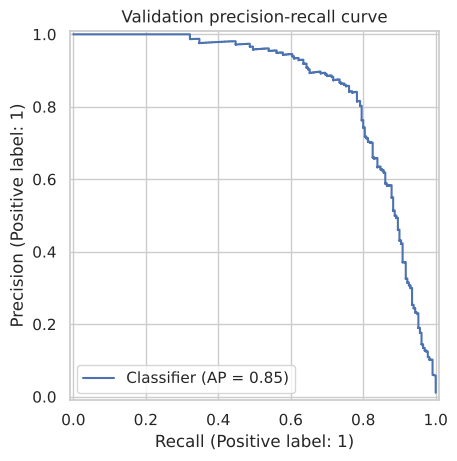

In [41]:
# ============================================================
# 13.1 VALIDATION EVALUATION
# ============================================================
X_val = val[meta_features]
y_val = val['pseudo_label']

val_proba = meta_model.predict_proba(X_val)[:, 1]

# Threshold chosen on validation (max F1), frozen afterwards
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)]) if len(thr) else 0.5
print(f"Validation-optimal threshold: {best_thr:.3f}  (default 0.5 shown for comparison)\n")

val_pred_05 = (val_proba >= 0.5).astype(int)
val_pred    = (val_proba >= best_thr).astype(int)

print("Classification report (validation, threshold = 0.5):")
print(classification_report(y_val, val_pred_05, digits=3, zero_division=0))
print(f"Classification report (validation, threshold = {best_thr:.3f}):")
print(classification_report(y_val, val_pred, digits=3, zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")
print(f"PR-AUC:  {average_precision_score(y_val, val_proba):.4f}")
print(f"Confusion matrix (tuned threshold):\n{confusion_matrix(y_val, val_pred)}")

PrecisionRecallDisplay.from_predictions(y_val, val_proba)
plt.title('Validation precision-recall curve'); plt.show()

### 13.2 Baseline comparison and cross-sensor corroboration

> The "vs label" columns are partly circular (the label is built from these detectors). **Corroboration is the independent column.**

In [42]:
# ============================================================
# 13.2 BASELINE COMPARISON + CROSS-SENSOR CORROBORATION
# ============================================================
def corroboration(d, flag):
    """Of flagged rows in neighbourhoods with >=2 sensors reporting that hour,
    the share where at least one OTHER sensor in the neighbourhood is also flagged."""
    f = pd.Series(np.asarray(flag).astype(int), index=d.index)
    hood_n = d.groupby(['NEIGHBORHOOD', 'DATETIME'])['LOCATION'].transform('nunique')
    hood_f = f.groupby([d['NEIGHBORHOOD'], d['DATETIME']]).transform('sum')
    eligible = (f == 1) & (hood_n >= 2)
    n_elig = int(eligible.sum())
    rate = float(((hood_f >= 2) & eligible).sum() / n_elig) if n_elig else np.nan
    return rate, n_elig

rows = {}
for name, col in [('stat', 'stat_flag'), ('lof', 'lof_flag'), ('svm', 'svm_flag'),
                  ('dbscan', 'dbscan_flag'), ('stl', 'stl_flag')]:
    rate, n_el = corroboration(val, val[col])
    rows[name] = {
        'flag_rate': val[col].mean(),
        'PR-AUC vs label': average_precision_score(y_val, val[col]),
        'F1 vs label': f1_score(y_val, val[col], zero_division=0),
        'corroboration': rate, 'n_eligible': n_el
    }
rate, n_el = corroboration(val, val['pseudo_label'])
rows['consensus (label)'] = {'flag_rate': val['pseudo_label'].mean(), 'PR-AUC vs label': np.nan,
                             'F1 vs label': np.nan, 'corroboration': rate, 'n_eligible': n_el}
rate, n_el = corroboration(val, val_pred)
rows['stacked'] = {
    'flag_rate': val_pred.mean(),
    'PR-AUC vs label': average_precision_score(y_val, val_proba),
    'F1 vs label': f1_score(y_val, val_pred, zero_division=0),
    'corroboration': rate, 'n_eligible': n_el
}
print(pd.DataFrame(rows).T.round(4))
print("\nNote: 'vs label' columns are partly circular (the label is built from these detectors). "
      "Corroboration is the independent column.")

                   flag_rate  PR-AUC vs label  F1 vs label  corroboration  \
stat                  0.1357           0.0802       0.1485         0.4040   
lof                   0.0207           0.0344       0.1529         0.0000   
svm                   0.0106           0.6285       0.7912         0.0667   
dbscan                0.0082           0.6229       0.7792         0.0833   
stl                   0.1435           0.0502       0.1122         0.1487   
consensus (label)     0.0109              NaN          NaN         0.0645   
stacked               0.0101           0.8521       0.8108         0.0833   

                   n_eligible  
stat                   1089.0  
lof                     128.0  
svm                      60.0  
dbscan                   24.0  
stl                    1022.0  
consensus (label)        31.0  
stacked                  24.0  

Note: 'vs label' columns are partly circular (the label is built from these detectors). Corroboration is the independent colum

### 13.3 Ablation: drop one base detector at a time

**(a) Consensus ablation.** Recompute the consensus from the remaining four detectors (≥ 3 of 4) and compare with the full label. A higher flip rate and lower F1 mean that detector matters more.

In [43]:
# ============================================================
# 13.3a ABLATION: DROP ONE BASE DETECTOR AT A TIME
# ============================================================
# (a) How much does the consensus label depend on each detector?
#     Recompute the consensus from the remaining four (>= 3 of 4) and compare with the full label.
ablation = {}
for drop_col in base_flags:
    rest = [c for c in base_flags if c != drop_col]
    votes4 = val[rest].sum(axis=1)
    label4 = (votes4 >= 3).astype(int)
    ablation[drop_col] = {
        'label_flip_rate': float((label4 != y_val).mean()),
        'F1 vs full label': f1_score(y_val, label4, zero_division=0),
        'PR-AUC vs full label': average_precision_score(y_val, votes4 / 4),
    }
print("Consensus ablation (lower F1 / higher flip rate = detector matters more):")
print(pd.DataFrame(ablation).T.round(4))

Consensus ablation (lower F1 / higher flip rate = detector matters more):
             label_flip_rate  F1 vs full label  PR-AUC vs full label
stat_flag             0.0059            0.6310                0.9434
lof_flag              0.0018            0.9074                0.8631
svm_flag              0.0036            0.7990                0.7277
dbscan_flag           0.0024            0.8753                0.8187
stl_flag              0.0038            0.7863                0.8799


**(b) Optional retrain ablation.** Retrains the meta-model on each 4-detector label. Slow, so it is gated by `RUN_RETRAIN_ABLATION` in Section 1.

In [44]:
# 13.3b Optional retrain ablation: retrain the meta-model on the 4-detector consensus label
if RUN_RETRAIN_ABLATION:
    retrain = {}
    for drop_col in base_flags:
        rest = [c for c in base_flags if c != drop_col]
        y_tr4 = (train[rest].sum(axis=1) >= 3).astype(int)
        y_va4 = (val[rest].sum(axis=1) >= 3).astype(int)
        m = make_meta_model(meta_features, n_estimators=300)
        m.fit(train[meta_features], y_tr4)
        retrain[drop_col] = average_precision_score(y_va4, m.predict_proba(val[meta_features])[:, 1])
    print("PR-AUC of meta-model retrained without each detector (vs its own 4-detector label):")
    for k, v in retrain.items():
        print(f"  without {k:12s}: {v:.4f}")
    print(f"  full ensemble       : {average_precision_score(y_val, val_proba):.4f}")
else:
    print("Retrain ablation skipped (set RUN_RETRAIN_ABLATION = True in the setup cell to run it).")

Retrain ablation skipped (set RUN_RETRAIN_ABLATION = True in the setup cell to run it).


### 13.4 Contribution check

The pseudo-label is built from detectors that use `PM25`, `PM10`, `residual` and humidity/temperature, so a model seeing the same inputs can score well without finding anything the detectors missed. This check shows:
- how much the stacked model adds beyond a one-line rule (`|residual|` alone), and
- how much it depends on PM-level information, including features that contain it indirectly (neighbourhood deviation, rolling means).

The chance level for PR-AUC equals the anomaly rate.

| Reading the result | Meaning |
|---|---|
| Small gap between `|residual|` alone and the full model | The model adds little beyond baseline deviation |
| Large drop without PM-level features | The model mostly reconstructs the detectors' own inputs |

In [45]:
# ============================================================
# 13.4 CONTRIBUTION CHECK (full training and validation sets)
# ============================================================
def pr_auc_with(features, n_estimators=300):
    m = make_meta_model(features, n_estimators)
    m.fit(train[features], train['pseudo_label'])
    return average_precision_score(y_val, m.predict_proba(val[features])[:, 1])

pm_level = [f for f in meta_features if f in ['PM25', 'PM10', 'residual', 'pm25_pm10_ratio',
                                              'hood_hour_mean', 'hood_deviation']]
roll_mean = [f for f in meta_features if f.startswith('pm25_roll_mean')]

contrib = {
    'chance (anomaly rate)': float(y_val.mean()),
    '|residual| alone (no model)': average_precision_score(y_val, val['residual'].abs()),
    'full stacked model': average_precision_score(y_val, val_proba),
}
f1_ = [f for f in meta_features if f not in pm_level]
if f1_:
    contrib['without PM-level features'] = pr_auc_with(f1_)
f2_ = [f for f in meta_features if f not in pm_level + roll_mean]
if f2_:
    contrib['without PM-level + rolling means'] = pr_auc_with(f2_)

print("Validation PR-AUC against the consensus label:")
print(pd.Series(contrib).round(4).to_string())
print(f"\nPM-level features removed: {pm_level}")
print(f"Rolling means also removed: {roll_mean}")
print("Read: a small gap between '|residual| alone' and the full model means the stacked model adds "
      "little beyond the baseline deviation; a large drop without PM-level features means it mostly "
      "reconstructs the detectors' own inputs.")

Validation PR-AUC against the consensus label:
chance (anomaly rate)               0.0109
|residual| alone (no model)         0.7855
full stacked model                  0.8521
without PM-level features           0.0448
without PM-level + rolling means    0.0105

PM-level features removed: ['residual', 'PM25', 'PM10', 'pm25_pm10_ratio', 'hood_deviation']
Rolling means also removed: ['pm25_roll_mean_72']
Read: a small gap between '|residual| alone' and the full model means the stacked model adds little beyond the baseline deviation; a large drop without PM-level features means it mostly reconstructs the detectors' own inputs.


### 13.5 Final locked test-set evaluation

The test set is touched **once**, with the threshold frozen from validation.

In [46]:
# ============================================================
# 13.5 FINAL, LOCKED TEST-SET EVALUATION (threshold frozen from validation)
# ============================================================
X_test  = test[meta_features]
y_test  = test['pseudo_label']
test_proba = meta_model.predict_proba(X_test)[:, 1]
test_pred  = (test_proba >= best_thr).astype(int)

print(f"Test classification report (threshold = {best_thr:.3f}, chosen on validation):")
print(classification_report(y_test, test_pred, digits=3, zero_division=0))
if y_test.nunique() == 2:
    print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")
    print(f"Test PR-AUC:  {average_precision_score(y_test, test_proba):.4f}")
rate, n_el = corroboration(test, test_pred)
print(f"Test cross-sensor corroboration of stacked flags: {rate:.3f} (n eligible = {n_el:,})")
test['ensemble_proba'] = test_proba
test['flag'] = test_pred

Test classification report (threshold = 0.970, chosen on validation):
              precision    recall  f1-score   support

           0      0.996     0.999     0.998     14742
           1      0.600     0.366     0.455        82

    accuracy                          0.995     14824
   macro avg      0.798     0.682     0.726     14824
weighted avg      0.994     0.995     0.995     14824

Test ROC-AUC: 0.9593
Test PR-AUC:  0.4476
Test cross-sensor corroboration of stacked flags: 0.000 (n eligible = 13)


### 13.6 Is the score driven by one sensor? (flag concentration)

A single misbehaving device can produce hundreds of easy, mutually consistent flags and make label metrics look excellent. The share of flags coming from the top sensor shows how much one device drives each split's numbers.

In [47]:
# 13.6 FLAG CONCENTRATION
def concentration(d, flag):
    by = pd.Series(np.asarray(flag), index=d.index).groupby(d['LOCATION']).sum().sort_values(ascending=False)
    return pd.Series({'flags': int(by.sum()), 'top_sensor': by.index[0],
                      'top_sensor_share': by.iloc[0] / max(by.sum(), 1),
                      'sensors_with_flags': int((by > 0).sum())})

print(pd.DataFrame({'validation': concentration(val, val_pred), 'test': concentration(test, test_pred)}).T)
print(f"\nSensor-range faults set aside in Section 5 (not scored by the model): {len(range_faults):,}")
print(range_faults.assign(split=np.where(range_faults['DATETIME'] < TRAIN_END, 'train',
                                         np.where(range_faults['DATETIME'] < VAL_END, 'val', 'test')))
      .groupby(['split', 'LOCATION']).size().rename('readings').to_string())

            flags  top_sensor  top_sensor_share  sensors_with_flags
validation  214.0      3576.0           0.67757                 9.0
test         50.0      3966.0           0.56000                 5.0

Sensor-range faults set aside in Section 5 (not scored by the model): 439
split  LOCATION
test   76            2
       3966          1
       3981          2
train  68            3
       70            1
val    3626        410
       3966          2
       3967         18


### 13.7 External check: documented pollution events

The proposal validates flags against documented events. `data/reference/documented_events.csv` lists event windows (local time) with a source column. A useful detector should flag more inside an event window than the same sensors do outside it (lift > 1).

> The file currently holds New Year fireworks windows, a recurring city-wide event. **Add a citation for each row** (and any other dated, sourced events, such as dumpsite fires or dust episodes) before relying on this check. Windows with very few readings carry little evidence.

In [48]:
# 13.7 DOCUMENTED EVENTS
from airq.evaluate import documented_event_check
events = pd.read_csv(resolve(CFG['paths']['events_file']))
scored_vt = pd.concat([val.assign(is_anomaly=val_pred), test.assign(is_anomaly=test_pred)], ignore_index=True)
ev = documented_event_check(scored_vt, events)
print(ev.round(4).to_string(index=False) if len(ev) else 'No event window overlaps the validation/test readings.')

                                         event               start                 end scope  readings_in_window  sensors  flag_rate_in  flag_rate_out    lift  mean_residual_in       source
New Year fireworks (recurring city-wide event) 2023-12-31 23:00:00 2024-01-01 03:00:00   ALL                  15        4        0.0667         0.0010 65.4578           23.1529 add citation
New Year fireworks (recurring city-wide event) 2024-12-31 23:00:00 2025-01-01 03:00:00   ALL                   5        1        0.0000         0.0063  0.0000           24.8465 add citation
New Year fireworks (recurring city-wide event) 2025-12-31 23:00:00 2026-01-01 03:00:00   ALL                   9        3        0.0000         0.0038  0.0000           30.5121 add citation


## 14. Explainability with SHAP

**Goal:** show which features drive the model's scores, globally and for individual flagged readings.

- SHAP is computed on the **preprocessed** feature matrix for **all validation rows** (no sampling).
- Detector flags and votes are not features, so explanations are in terms of physical and contextual quantities (residual, PM levels, rolling statistics, neighbour agreement, humidity), which an operator can act on.
- SHAP shows **what the model relies on**, not *why the pollution happened*.

### 14.1 Global feature importance

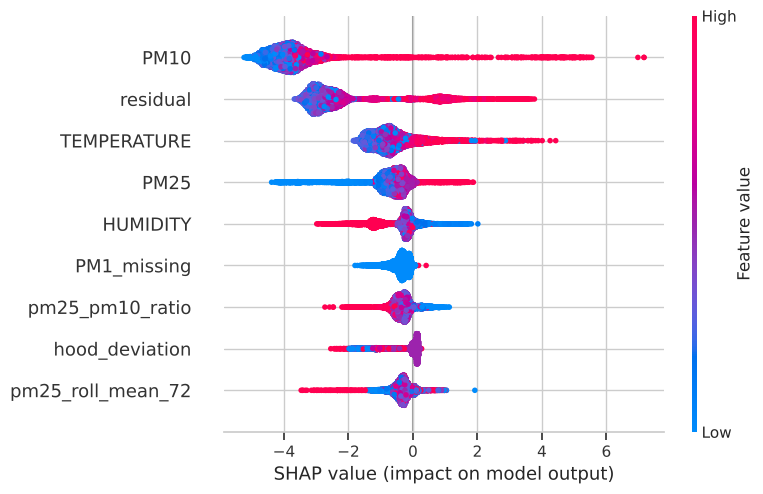

In [49]:
# ============================================================
# 14. SHAP EXPLAINABILITY (all validation rows)
# ============================================================
prep = meta_model.named_steps['prep']
clf  = meta_model.named_steps['clf']

X_val_prep  = prep.transform(val[meta_features])
explainer   = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_val_prep)

# Global summary
shap.summary_plot(shap_values, X_val_prep, feature_names=meta_features, show=True)

### 14.2 Local explanation: highest-probability flagged anomaly

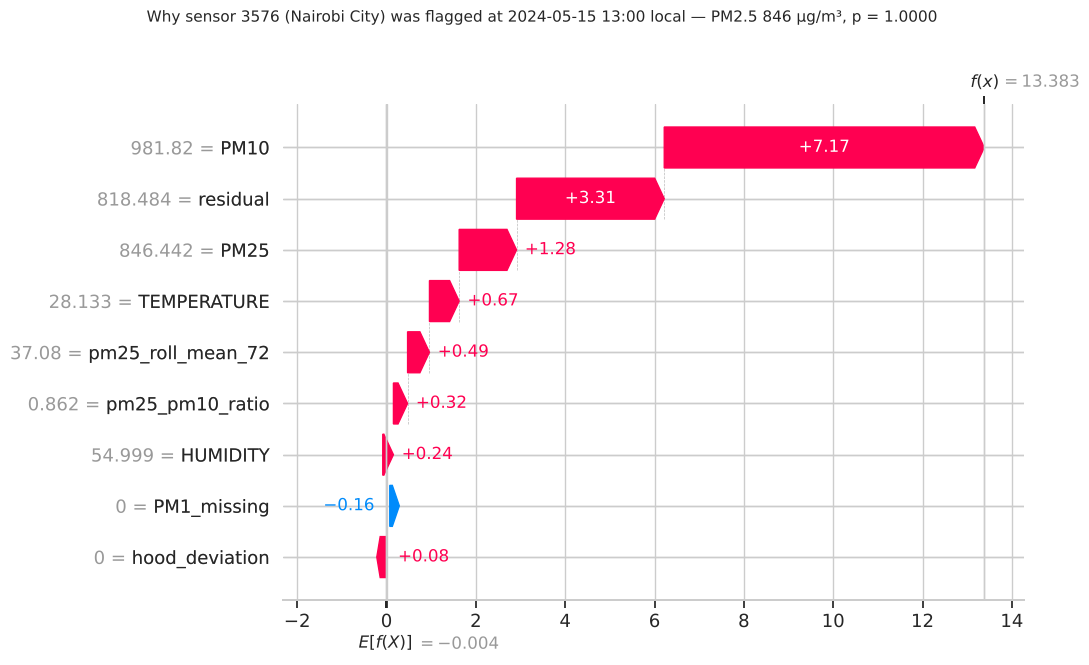

In [50]:
# Local explanation for the highest-probability flagged anomaly in validation
flagged_local = np.where(val_proba >= best_thr)[0]
if len(flagged_local) > 0:
    i = flagged_local[np.argmax(val_proba[flagged_local])]
    row = val.iloc[i]
    expl = shap.Explanation(values=shap_values[i], base_values=explainer.expected_value,
                            data=val[meta_features].iloc[i].values, feature_names=meta_features)
    shap.plots.waterfall(expl, max_display=12, show=False)
    fig = plt.gcf(); fig.set_size_inches(11, 6.5)
    fig.suptitle(f"Why sensor {row['LOCATION']} ({row['NEIGHBORHOOD']}) was flagged at "
                 f"{row['DATETIME']:%Y-%m-%d %H:%M} local — PM2.5 {row['PM25']:.0f} µg/m³, p = {val_proba[i]:.4f}",
                 fontsize=11, y=1.02)
    plt.tight_layout(); plt.show()
else:
    print("No flagged anomalies in validation.")

---
# Part E: Interpretation

## 15. Severity Tagging and Cause Classification

**Goal:** turn raw flags into something an operator can triage.

### Severity (flagged readings only)

The previous rule used the meta-model probability (`> 0.9` Critical, `> 0.7` Alert). After SMOTE the probability is uncalibrated and the frozen threshold is about 0.97–0.99, so **every** flag passed the probability test and severity collapsed to a single tier (579 Critical, 2 Alert, 0 Watch). Severity now combines *how unusual* a reading is (robust z of the residual, using the training median/MAD from 11.1) with *how unhealthy* it is (US EPA 2024 PM2.5 breakpoints):

| Tier | Rule |
|---|---|
| **Critical** | robust z ≥ 10 **or** PM2.5 ≥ 125.5 µg/m³ ("Very Unhealthy") |
| **Alert** | robust z ≥ 6 **or** PM2.5 ≥ 55.5 µg/m³ ("Unhealthy") |
| **Watch** | any other flagged reading |
| **Normal** | not flagged |

Thresholds live in `configs/config.yaml` and can be overridden per API request.

### Likely cause (continuous neighbour evidence)

The earlier rule asked whether a neighbour was *also flagged*. That is a very high bar (≥ 3 of 5 detectors, then the probability cutoff), so real events were almost always labelled as faults. The cause is now judged on **how much of the reading's excess its neighbours share**:

`nbr_resid` = mean residual of the *other* sensors in the same neighbourhood and hour.
A flagged reading is **supported** when `sign(own residual) × nbr_resid ≥ NBR_SUPPORT × |own residual|` (floor of 1 µg/m³). Using the sign means sensor dropouts (negative residuals) are handled too.

| Label | Condition |
|---|---|
| `genuine` | Flagged, neighbours reported, and they show at least `NBR_SUPPORT` of the excess |
| `likely_sensor_fault` | Flagged, neighbours reported, and they do **not** show it |
| `unverifiable` | Only one sensor reported in the neighbourhood |

`NBR_SUPPORT` (default 0.5) is tuned in 15.3 using a sweep and a diagnostic.

### Cause classifier: random forest

A **random forest** is trained on flagged validation readings to see whether the *remaining* features can recover the cause, and is then evaluated on the **test** set. The neighbour-evidence feature (`nbr_resid`) is deliberately **excluded** from its inputs, because it defines the label. The classifier is therefore a neighbour-free approximation, useful when a reading has no reporting neighbours. `residual` is still an input and is part of the label rule, so treat the scores as an upper bound.

### 15.1 Severity tiers

In [51]:
# ============================================================
# 15.1 SEVERITY TAGGING (flagged readings only)
# ============================================================
val['ensemble_proba'] = val_proba
val['flag'] = val_pred
SEV = CFG['severity']

def severity_tiers(d):
    z = np.abs(0.6745 * (d['residual'] - res_med) / res_mad)
    f = d['flag'] == 1
    out = pd.Series('Normal', index=d.index, dtype=object)
    out[f] = 'Watch'
    out[f & ((z >= SEV['alert_z']) | (d['PM25'] >= SEV['alert_pm25']))] = 'Alert'
    out[f & ((z >= SEV['critical_z']) | (d['PM25'] >= SEV['critical_pm25']))] = 'Critical'
    return out

val['severity'] = severity_tiers(val)
print("Severity distribution (validation):")
print(val['severity'].value_counts())
print("\nProbability of flagged readings (why probability cannot set tiers):")
print(val.loc[val['flag'] == 1, 'ensemble_proba'].describe().round(4).to_string())

Severity distribution (validation):
severity
Normal      20914
Critical      143
Alert          71
Name: count, dtype: int64

Probability of flagged readings (why probability cannot set tiers):
count    214.0000
mean       0.9966
std        0.0065
min        0.9704
25%        0.9966
50%        0.9997
75%        0.9999
max        1.0000


### 15.2 Cause labels from neighbour evidence

Defines `neighbour_evidence` and `assign_cause`. The same logic is written into `deployment/feature_pipeline.py` in Section 18.2 (with `NBR_SUPPORT` copied from here), and Section 18.5 asserts the two agree.

In [52]:
# ============================================================
# 15.2 CAUSE LABELS FROM CONTINUOUS NEIGHBOUR EVIDENCE
# ============================================================
NBR_SUPPORT = CFG['cause']['nbr_support']   # neighbours must show at least this share of the reading's excess

def neighbour_evidence(d):
    """Return (sensors reporting in the neighbourhood-hour, mean residual of the OTHER sensors)."""
    grp = d.groupby(['NEIGHBORHOOD', 'DATETIME'])
    n_sens = grp['LOCATION'].transform('nunique')
    n_rows = grp['residual'].transform('count')
    nbr = (grp['residual'].transform('sum') - d['residual']) / (n_rows - 1).where(n_rows > 1)
    return n_sens, nbr

def assign_cause(d, flag, support=None):
    support = NBR_SUPPORT if support is None else support
    n_sens, nbr = neighbour_evidence(d)
    own = d['residual']
    supported = (np.sign(own) * nbr) >= support * own.abs().clip(lower=1)
    f = pd.Series(np.asarray(flag).astype(int), index=d.index) == 1
    cause = pd.Series('not_flagged', index=d.index)
    cause[f & (n_sens < 2)] = 'unverifiable'
    cause[f & (n_sens >= 2) & supported]  = 'genuine'
    cause[f & (n_sens >= 2) & ~supported] = 'likely_sensor_fault'
    return cause, nbr

val['cause_label'], val['nbr_resid'] = assign_cause(val, val['flag'])
flagged = val['flag'] == 1
print(f"NBR_SUPPORT = {NBR_SUPPORT}")
print("Cause label distribution among flagged readings:")
print(val.loc[flagged, 'cause_label'].value_counts())

NBR_SUPPORT = 0.5
Cause label distribution among flagged readings:
cause_label
unverifiable           190
likely_sensor_fault     18
genuine                  6
Name: count, dtype: int64


In [53]:
n_sens, nbr = neighbour_evidence(val)
fl = val['flag'] == 1
multi = fl & (n_sens >= 2)

print(f"Flagged readings:                      {fl.sum():,}")
print(f"  ...with >=2 sensors reporting:       {multi.sum():,}")
print(f"  ...distinct sensors among those:     {val.loc[multi, 'LOCATION'].nunique()}")
print(f"Share of ALL val rows in multi-sensor neighbourhood-hours: {(n_sens >= 2).mean():.1%}")

print("\nNeighbour residual at flagged multi-sensor readings:")
print(nbr[multi].describe().round(2).to_string())

print("\nClass counts at different NBR_SUPPORT values (multi-sensor flags only):")
for s_ in [-0.5, 0.0, 0.1, 0.25, 0.5]:
    c_, _ = assign_cause(val, val['flag'], support=s_)
    print(f"  support={s_:>5}: {c_[multi].value_counts().to_dict()}")

Flagged readings:                      214
  ...with >=2 sensors reporting:       24
  ...distinct sensors among those:     3
Share of ALL val rows in multi-sensor neighbourhood-hours: 26.0%

Neighbour residual at flagged multi-sensor readings:
count     24.00
mean      32.54
std       32.37
min      -11.31
25%       11.34
50%       24.90
75%       49.43
max      107.27

Class counts at different NBR_SUPPORT values (multi-sensor flags only):
  support= -0.5: {'genuine': 24}
  support=  0.0: {'genuine': 21, 'likely_sensor_fault': 3}
  support=  0.1: {'genuine': 18, 'likely_sensor_fault': 6}
  support= 0.25: {'genuine': 13, 'likely_sensor_fault': 11}
  support=  0.5: {'likely_sensor_fault': 18, 'genuine': 6}


### 15.3 Diagnostic and tuning of `NBR_SUPPORT`

Two checks before training the classifier:
1. **Sweep:** how the genuine / fault split moves as `NBR_SUPPORT` changes. A sensible value gives a clear share of both classes; a split that never changes suggests the label is not sensitive to the choice.
2. **Fault-labelled flags:** which sensors they come from and how large the neighbour residual is. Neighbours near 0 with a large own residual means those flags really are isolated.

Change `NBR_SUPPORT` in 15.2 and re-run from there if you want a different operating point.

In [54]:
# ============================================================
# 15.3 DIAGNOSTIC: sensitivity to NBR_SUPPORT and who the "faults" are
# ============================================================
sweep = {}
for s_ in [0.1, 0.25, 0.5, 0.75, 1.0]:
    c_, _ = assign_cause(val, val['flag'], support=s_)
    sweep[s_] = c_[flagged].value_counts()
print("Flagged readings by cause for different NBR_SUPPORT values:")
print(pd.DataFrame(sweep).fillna(0).astype(int).T)

fault = val[val['cause_label'] == 'likely_sensor_fault']
print(f"\nSensors behind the {len(fault)} fault-labelled flags (top 10):")
print(fault['LOCATION'].value_counts().head(10).to_string())
print("\nMedian own residual vs mean neighbour residual at those flags (µg/m³):")
print(f"  own: {fault['residual'].median():.2f}   neighbours: {fault['nbr_resid'].median():.2f}")
print("\nNeighbour residual at fault-labelled flags:")
print(fault['nbr_resid'].describe().round(2).to_string())

Flagged readings by cause for different NBR_SUPPORT values:
      genuine  likely_sensor_fault  unverifiable
0.10       18                    6           190
0.25       13                   11           190
0.50        6                   18           190
0.75        3                   21           190
1.00        1                   23           190

Sensors behind the 18 fault-labelled flags (top 10):
LOCATION
3967    7
3966    6
3626    5

Median own residual vs mean neighbour residual at those flags (µg/m³):
  own: 94.74   neighbours: 14.57

Neighbour residual at fault-labelled flags:
count    18.00
mean     17.97
std      19.10
min     -11.31
25%      10.62
50%      14.57
75%      27.71
max      55.59


### 15.4 Random-forest cause classifier

| Step | Detail |
|---|---|
| Training data | Flagged **validation** readings labelled `genuine` or `likely_sensor_fault` |
| Model | Median imputation, `RobustScaler`, `RandomForestClassifier` (300 trees, `class_weight='balanced'`) |
| Cross-validation | `GroupKFold` by sensor when at least 3 sensors are present, otherwise stratified folds (warned) |
| Hold-out check | Evaluated on flagged **test** readings with labels from the same rule |
| Guard | Training stops with a clear message unless both classes have at least `MIN_PER_CLASS` rows |
| Persistence | The scripted pipeline saves the same model to `models/cause_model.joblib` |

`nbr_resid` is excluded from the features (it defines the label).

In [55]:
# ============================================================
# 15.4 RANDOM-FOREST CAUSE CLASSIFIER (always a random forest)
# ============================================================
sev_map = {'Watch': 1, 'Alert': 2, 'Critical': 3, 'Normal': 0}
val['severity_ord'] = val['severity'].map(sev_map)

# ensemble_proba / severity_ord don't exist for train rows, so they are dropped from the features
cause_features = ['PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE',
                  'pm25_roll_mean_24', 'pm25_roll_std_24', 'pm25_pm10_ratio', 'residual',
                  'PM1_missing', 'HUMIDITY_missing', 'TEMPERATURE_missing']
assert 'nbr_resid' not in cause_features

MIN_PER_CLASS = 30
pool = []
for d_ in (train, val):
    c_, n_ = assign_cause(d_, d_['pseudo_label'])          # consensus-flagged readings
    x_ = d_.assign(cause_label=c_, nbr_resid=n_)
    pool.append(x_[x_['cause_label'].isin(['genuine', 'likely_sensor_fault'])])
cause_df = pd.concat(pool, ignore_index=True)

vc = cause_df['cause_label'].value_counts()
print("Training label counts:", vc.to_dict(), "| sensors:", cause_df['LOCATION'].nunique())
assert len(vc) == 2 and vc.min() >= MIN_PER_CLASS, "Still too few of one class; see the Step 1 output."
cause_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  RobustScaler()),
    ('clf',     RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                       min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1))
])

# Cross-validation (by sensor if there are enough sensors)
n_sensors = cause_df['LOCATION'].nunique()
if n_sensors >= 3:
    cv_c, cv_kw = GroupKFold(n_splits=min(5, n_sensors)), {'groups': cause_df['LOCATION']}
    print(f"CV: GroupKFold by sensor ({min(5, n_sensors)} folds)")
else:
    cv_c, cv_kw = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), {}
    print("WARNING: fewer than 3 sensors; using stratified folds, which are NOT sensor-grouped "
          "and will look optimistic.")
cause_cv = cross_validate(cause_model, cause_df[cause_features], cause_df['cause_label'],
                          cv=cv_c, scoring=['f1_macro', 'balanced_accuracy'], **cv_kw)
print(f"Validation CV: macro-F1 = {cause_cv['test_f1_macro'].mean():.3f} "
      f"± {cause_cv['test_f1_macro'].std():.3f}, "
      f"balanced accuracy = {cause_cv['test_balanced_accuracy'].mean():.3f}")

cause_model.fit(cause_df[cause_features], cause_df['cause_label'])

# Feature importance
imp = pd.Series(cause_model.named_steps['clf'].feature_importances_, index=cause_features)
print("\nRandom-forest feature importance:")
print(imp.sort_values(ascending=False).round(3).to_string())

# Hold-out check on the test set (labels from the same neighbour-evidence rule)
test['severity'] = severity_tiers(test)
test['severity_ord'] = test['severity'].map(sev_map)
test['cause_label'], test['nbr_resid'] = assign_cause(test, test['flag'])
cause_test = test[test['cause_label'].isin(['genuine', 'likely_sensor_fault'])]
if cause_test['cause_label'].nunique() == 2:
    print("\nHold-out TEST report (flagged readings only):")
    print(classification_report(cause_test['cause_label'],
                                cause_model.predict(cause_test[cause_features]),
                                digits=3, zero_division=0))
else:
    print("\nTest set lacks both classes among flagged readings; hold-out report skipped:",
          cause_test['cause_label'].value_counts().to_dict())

# The deployed cause model is trained by the scripted pipeline (src/airq/train.py) with the
# same data and settings; Section 18 checks that it agrees with this one.

Training label counts: {'likely_sensor_fault': 304, 'genuine': 35} | sensors: 19
CV: GroupKFold by sensor (5 folds)


Validation CV: macro-F1 = 0.524 ± 0.156, balanced accuracy = 0.555



Random-forest feature importance:
TEMPERATURE            0.158
pm25_pm10_ratio        0.158
pm25_roll_std_24       0.140
HUMIDITY               0.128
pm25_roll_mean_24      0.107
PM10                   0.102
residual               0.094
PM25                   0.075
PM1_missing            0.035
TEMPERATURE_missing    0.001
HUMIDITY_missing       0.001

Hold-out TEST report (flagged readings only):
                     precision    recall  f1-score   support

            genuine      0.000     0.000     0.000         1
likely_sensor_fault      0.923     1.000     0.960        12

           accuracy                          0.923        13
          macro avg      0.462     0.500     0.480        13
       weighted avg      0.852     0.923     0.886        13



## 16. Spatial Validation (Moran's I + Cross-Sensor)

**Goal:** test whether anomalies cluster geographically. Clustered anomalies are more likely genuine; isolated ones are more likely malfunctions.

**Method**
- `NEIGHBORHOOD_LAT/LON` hold each **sensor's own site** (3-decimal archive coordinates, about 110 m), not a neighbourhood centroid; sensors in the same neighbourhood have different coordinates. The previous version took the first sensor's coordinates per neighbourhood, which misplaced the others.
- **16.1 Sensor level (primary):** anomaly rate and mean PM2.5 per sensor with at least 100 validation + test readings, at the sensor's coordinates.
- **16.2 Neighbourhood level:** the same per neighbourhood, at the mean of its sensors' coordinates (used by the map in 17.4).
- Spatial weights: k-nearest-neighbour (k = 5), row-standardised; 999 permutations. Under no spatial pattern, E[I] = −1/(n−1).
- With roughly ten sensors active after 2024, the test has little power; treat it as supporting evidence only.

| LISA code | Cluster type |
|---|---|
| 1 | High-High |
| 2 | Low-High |
| 3 | Low-Low |
| 4 | High-Low |

Requires `libpysal` and `esda`.

In [56]:
# ============================================================
# 16. SPATIAL VALIDATION
# ============================================================
spatial_src = pd.concat([val[['LOCATION', 'NEIGHBORHOOD', 'PM25', 'flag', 'NEIGHBORHOOD_LAT', 'NEIGHBORHOOD_LON']],
                         test[['LOCATION', 'NEIGHBORHOOD', 'PM25', 'flag', 'NEIGHBORHOOD_LAT', 'NEIGHBORHOOD_LON']]])

def unit_stats(key):
    return (spatial_src.groupby(key)
            .agg(PM25=('PM25', 'mean'), anomaly_rate=('flag', 'mean'), n=('PM25', 'size'),
                 NEIGHBORHOOD_LAT=('NEIGHBORHOOD_LAT', 'mean'), NEIGHBORHOOD_LON=('NEIGHBORHOOD_LON', 'mean'))
            .dropna().query('n >= 100'))

sensor_stats = unit_stats('LOCATION')
hood_stats   = unit_stats('NEIGHBORHOOD')
print(f"Sensors analysed: {len(sensor_stats)} | neighbourhoods analysed: {len(hood_stats)}")

try:
    from libpysal.weights import KNN
    from esda.moran import Moran, Moran_Local
    np.random.seed(RANDOM_STATE)
    for label, st in [('16.1 sensor level', sensor_stats), ('16.2 neighbourhood level', hood_stats)]:
        if len(st) < 6:
            print(f"{label}: too few units ({len(st)}) for Moran's I"); continue
        w = KNN.from_array(st[['NEIGHBORHOOD_LON', 'NEIGHBORHOOD_LAT']].values, k=min(5, len(st) - 1))
        w.transform = 'r'
        print(f"\n{label} (n = {len(st)}, E[I] under no pattern = {-1/(len(st)-1):.3f})")
        for var in ['PM25', 'anomaly_rate']:
            mi = Moran(st[var].values, w, permutations=999)
            verdict = ('clustered' if (mi.p_sim < 0.05 and mi.I > mi.EI)
                       else 'dispersed' if (mi.p_sim < 0.05 and mi.I < mi.EI) else 'no significant pattern')
            print(f"  Global Moran's I ({var}): {mi.I:.4f}, pseudo p = {mi.p_sim:.4f} → {verdict}")
        lisa = Moran_Local(st['anomaly_rate'].values, w, permutations=999)
        st['lisa_q'], st['lisa_p'] = lisa.q, lisa.p_sim
        sig = st.loc[st['lisa_p'] < 0.05, ['anomaly_rate', 'lisa_q', 'lisa_p']]
        print("  Significant local clusters (1=HH, 2=LH, 3=LL, 4=HL):", 'none' if sig.empty else '')
        if not sig.empty:
            print(sig.round(4).to_string())
except ImportError:
    print("Install libpysal and esda for Moran's I.")

Sensors analysed: 10 | neighbourhoods analysed: 8



16.1 sensor level (n = 10, E[I] under no pattern = -0.111)
  Global Moran's I (PM25): 0.1561, pseudo p = 0.0170 → clustered
  Global Moran's I (anomaly_rate): 0.0002, pseudo p = 0.0420 → clustered
  Significant local clusters (1=HH, 2=LH, 3=LL, 4=HL): 
          anomaly_rate  lisa_q  lisa_p
LOCATION                              
76              0.0006       3   0.044
3612            0.0056       3   0.032

16.2 neighbourhood level (n = 8, E[I] under no pattern = -0.143)
  Global Moran's I (PM25): 0.0539, pseudo p = 0.0280 → clustered
  Global Moran's I (anomaly_rate): -0.0568, pseudo p = 0.0800 → no significant pattern
  Significant local clusters (1=HH, 2=LH, 3=LL, 4=HL): 
                      anomaly_rate  lisa_q  lisa_p
NEIGHBORHOOD                                      
CBD division                0.0008       2   0.004
Kilimani sublocation        0.0054       3   0.001


## 17. Case Studies, Monthly Rates, Interactive Map and Dashboard

**Goal:** make the results tangible and explorable.

| Sub-section | Output |
|---|---|
| 17.1 | Top flagged events with a neighbourhood time-series comparison |
| 17.2 | Monthly anomaly rate over available readings only (gaps stay gaps) |
| 17.3 | Diagnostic: are monthly peaks network-wide or one sensor? |
| 17.4 | Folium map of neighbourhood anomaly rate |
| 17.5 | Plotly dashboard (time series, heatmap, bubble map, severity × cause) exported as one HTML file |

### 17.1 Case study: top flagged events

The highest-severity events are listed, and the top one is plotted against the other sensors in its neighbourhood (±48 h) to show whether neighbours saw the same thing.

           DATETIME  LOCATION       PM25  baseline   residual  ensemble_proba severity         cause_label
2024-05-15 13:00:00      3576 846.442444 27.958256 818.484188        0.999998 Critical        unverifiable
2024-05-15 12:00:00      3576 558.869019 28.994539 529.874479        0.999995 Critical        unverifiable
2024-10-23 10:00:00      3596 155.535721 23.831999 131.703722        0.999991 Critical        unverifiable
2024-05-15 15:00:00      3576 158.461960 27.567144 130.894815        0.999987 Critical        unverifiable
2024-09-16 13:00:00      3967 642.829956 11.311740 631.518216        0.999986 Critical likely_sensor_fault


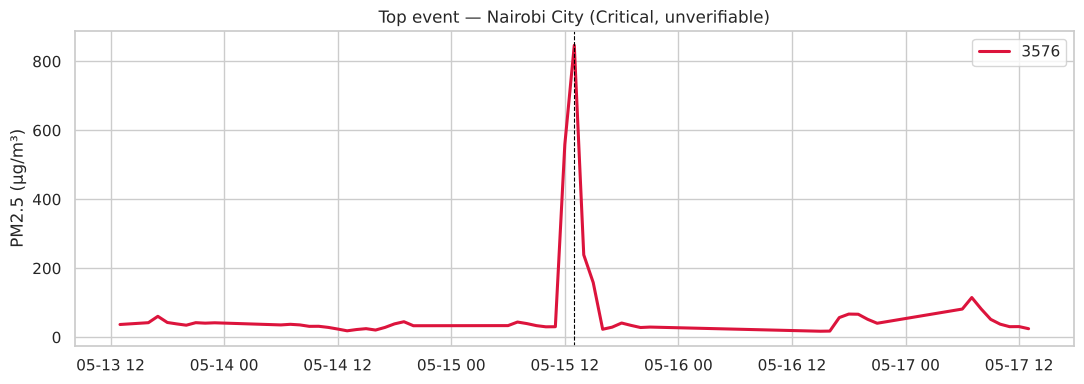

In [57]:
# ============================================================
# 17.1 CASE STUDY: TOP FLAGGED EVENTS
# ============================================================
top = (val[val['flag'] == 1]
       .assign(_sev=lambda x: x['severity_ord'])
       .sort_values(['_sev', 'ensemble_proba'], ascending=False)
       .head(5))
print(top[['DATETIME', 'LOCATION', 'PM25', 'baseline', 'residual',
           'ensemble_proba', 'severity', 'cause_label']].to_string(index=False))

# Time series around the top event: the flagged sensor vs. the rest of its neighbourhood
if len(top) > 0:
    r = top.iloc[0]
    window = val[(val['NEIGHBORHOOD'] == r['NEIGHBORHOOD']) &
                 ((val['DATETIME'] - r['DATETIME']).abs() <= pd.Timedelta('48h'))]
    fig, ax = plt.subplots(figsize=(11, 4))
    for loc_id, g in window.groupby('LOCATION'):
        g = g.sort_values('DATETIME')
        is_target = (loc_id == r['LOCATION'])
        ax.plot(g['DATETIME'], g['PM25'], lw=2.2 if is_target else 0.9,
                color='crimson' if is_target else 'grey', alpha=1 if is_target else 0.7,
                label=str(loc_id) if is_target else None)
    ax.axvline(r['DATETIME'], color='black', ls='--', lw=0.8)
    ax.set_title(f"Top event — {r['NEIGHBORHOOD']} ({r['severity']}, {r['cause_label']})")
    ax.set_ylabel('PM2.5 (µg/m³)'); ax.legend()
    plt.tight_layout(); plt.show()

### 17.2 Monthly anomaly rate (validation + test)

Rates are computed over available readings only; months with no readings stay `NaN` and are shaded, because the rate is undefined there.

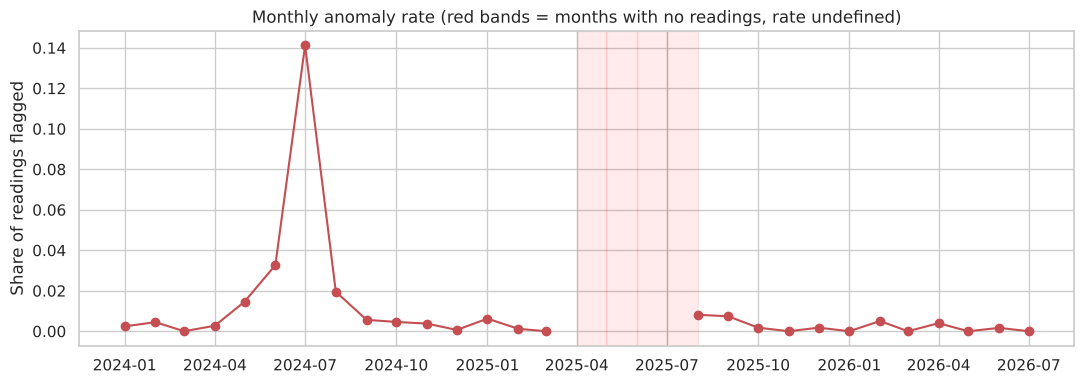

In [58]:
# ============================================================
# 17.2 MONTHLY ANOMALY RATE (validation + test, over available readings only)
# ============================================================
scored = pd.concat([val[['DATETIME', 'flag']], test[['DATETIME', 'flag']]])
monthly_rate = scored.set_index('DATETIME')['flag'].resample('ME').mean()
monthly_n    = scored.set_index('DATETIME')['flag'].resample('ME').count()
monthly_rate.index = monthly_rate.index.to_period('M')
monthly_n.index    = monthly_n.index.to_period('M')

scored_months = pd.period_range(monthly_rate.index.min(), monthly_rate.index.max(), freq='M')
monthly_rate = monthly_rate.reindex(scored_months)           # empty months stay NaN (no evidence)
monthly_n    = monthly_n.reindex(scored_months, fill_value=0)
monthly_rate[monthly_n == 0] = np.nan

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(scored_months.to_timestamp(), monthly_rate.values, marker='o', color='#C44E52')
for m in scored_months[monthly_n.values == 0]:
    ax.axvspan(m.to_timestamp(), (m + 1).to_timestamp(), color='red', alpha=0.08)
ax.set_title('Monthly anomaly rate (red bands = months with no readings, rate undefined)')
ax.set_ylabel('Share of readings flagged')
plt.tight_layout(); plt.show()

### 17.3 Monthly diagnostic: network-wide event or single sensor?

> **How to read it:** a high flag rate with a high top-sensor share suggests a single-sensor fault episode. A high rate spread over many sensors suggests a regional event, or a baseline that lacks a seasonal term.

In [59]:
# ============================================================
# 17.3 MONTHLY DIAGNOSTIC: are the peaks network-wide or one sensor?
# ============================================================
scored_full = pd.concat([val, test])
scored_full['month'] = scored_full['DATETIME'].dt.to_period('M')

month_summary = scored_full.groupby('month').agg(
    readings=('flag', 'size'),
    sensors=('LOCATION', 'nunique'),
    flag_rate=('flag', 'mean'),
)
top_share = (
    scored_full[scored_full['flag'] == 1]
    .groupby('month')['LOCATION']
    .agg(lambda s: s.value_counts(normalize=True).iloc[0])
    .rename('top_sensor_share_of_flags')
)
print(month_summary.join(top_share).round(3).to_string())
print("\nRead: a high flag rate with a high top-sensor share suggests a single-sensor fault episode; "
      "a high rate spread over many sensors suggests a regional event, or a baseline that lacks a seasonal term.")

         readings  sensors  flag_rate  top_sensor_share_of_flags
month                                                           
2024-01      2505        5      0.002                      0.500
2024-02      2680       10      0.004                      0.333
2024-03        12        4      0.000                        NaN
2024-04      1836        4      0.003                      0.600
2024-05      1436        4      0.015                      0.952
2024-06       735        2      0.033                      1.000
2024-07       446        1      0.141                      1.000
2024-08      2357        7      0.020                      0.652
2024-09      2662        6      0.006                      0.467
2024-10      3051        7      0.005                      0.571
2024-11      1859        8      0.004                      0.429
2024-12      1549        3      0.001                      1.000
2025-01      1770        3      0.006                      0.909
2025-02      1660        

### 17.4 Interactive map (Folium)

Neighbourhood markers; the top decile of anomaly rate is drawn in red. Markers sit at the mean of each neighbourhood's sensor coordinates and grow with the number of readings. The map renders inline in Jupyter, VS Code and Colab. It is also saved to `reports/figures/nairobi_sensor_map.html` for viewers that do not run JavaScript, such as GitHub.

In [60]:
# ============================================================
# 17.4 INTERACTIVE MAP (FOLIUM) — neighbourhood anomaly rate
# ============================================================
try:
    import folium
    m = folium.Map(location=[-1.286389, 36.817223], zoom_start=11, tiles='OpenStreetMap')
    hi = hood_stats['anomaly_rate'].quantile(0.9)
    for hood, row in hood_stats.iterrows():
        folium.CircleMarker(
            location=[row['NEIGHBORHOOD_LAT'], row['NEIGHBORHOOD_LON']],
            radius=float(5 + 3 * np.log10(max(row['n'], 1))),
            tooltip=hood,
            popup=(f"<b>{hood}</b><br>anomaly rate = {row['anomaly_rate']:.3%}<br>"
                   f"mean PM2.5 = {row['PM25']:.1f} µg/m³<br>readings = {int(row['n']):,}"),
            color='crimson' if row['anomaly_rate'] >= hi else 'steelblue',
            fill=True, fill_opacity=0.7
        ).add_to(m)
    m.fit_bounds([[hood_stats['NEIGHBORHOOD_LAT'].min(), hood_stats['NEIGHBORHOOD_LON'].min()],
                  [hood_stats['NEIGHBORHOOD_LAT'].max(), hood_stats['NEIGHBORHOOD_LON'].max()]], padding=(30, 30))
    m.save(FIG_DIR / 'nairobi_sensor_map.html')
    print('Saved', FIG_DIR / 'nairobi_sensor_map.html')
    display(m)
except ImportError:
    print("Install folium to render the interactive map.")

Saved /home/claude/repo/reports/figures/nairobi_sensor_map.html


### 17.5 Interactive Plotly dashboard

Four linked views, exported together as one self-contained HTML file (`interactive_dashboard.html`):

| Panel | Content |
|---|---|
| (a) | Sensor time series with baseline, flagged points, range slider and selector buttons |
| (b) | Anomaly rate by weekday × hour |
| (c) | Neighbourhood bubble map (size = readings, colour = anomaly rate) |
| (d) | Severity × likely cause (stacked bars, flagged only) |

Saved /home/claude/repo/reports/figures/interactive_dashboard.html


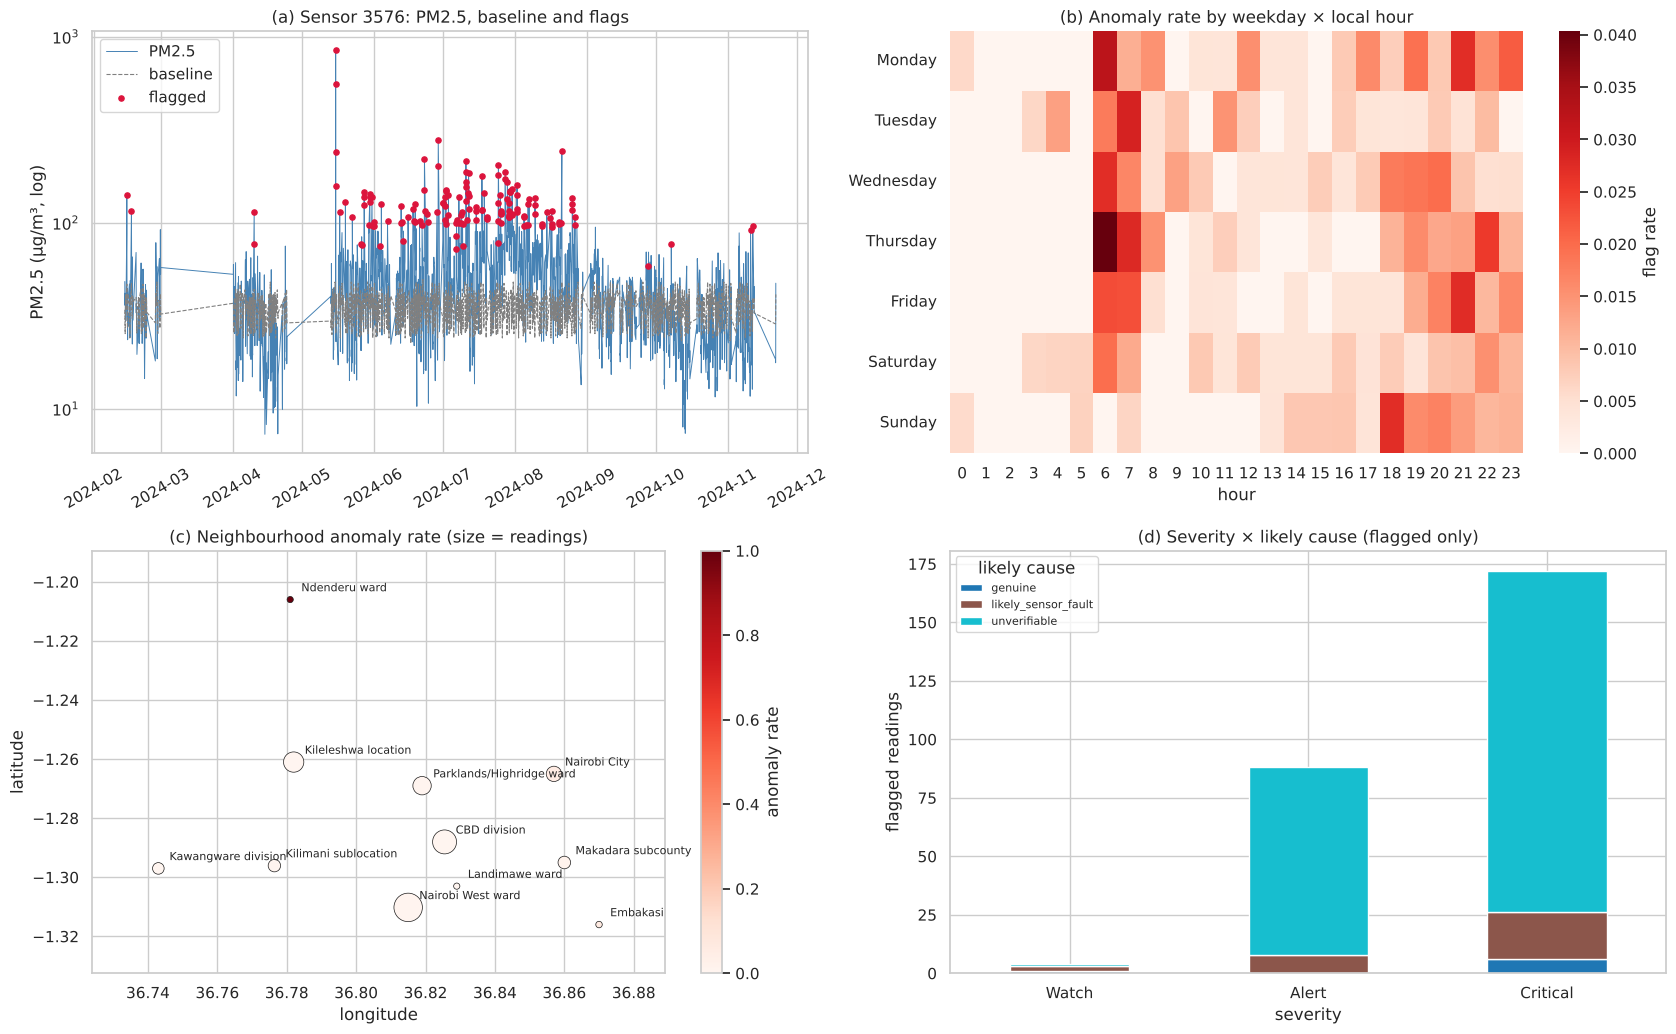

In [61]:
# ============================================================
# 17.5 INTERACTIVE PLOTLY DASHBOARD (self-contained HTML export)
# ============================================================
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# Emit standard HTML (with plotly.js) as well as Plotly's own format, so the charts render in
# JupyterLab, classic Notebook, VS Code and Colab. GitHub does not run JavaScript, so a static
# matplotlib snapshot of the same views is drawn at the end of this cell.
pio.renderers.default = 'notebook_connected+plotly_mimetype'

scored_all = pd.concat([val, test], ignore_index=True).copy()
scored_all['date'] = scored_all['DATETIME'].dt.floor('D')

# (a) Sensor time series with hover, zoom, rangeselector
target_sensor = (scored_all.loc[scored_all['flag'] == 1, 'LOCATION']
                 .value_counts().index[0]) if (scored_all['flag'] == 1).any() else scored_all['LOCATION'].iloc[0]
s_ts = scored_all[scored_all['LOCATION'] == target_sensor].sort_values('DATETIME')
fig_ts = go.Figure()
fig_ts.add_trace(go.Scatter(x=s_ts['DATETIME'], y=s_ts['PM25'], mode='lines',
                            name='PM2.5', line=dict(color='steelblue', width=1)))
fig_ts.add_trace(go.Scatter(x=s_ts['DATETIME'], y=s_ts['baseline'], mode='lines',
                            name='baseline', line=dict(color='grey', dash='dash', width=1)))
fl = s_ts[s_ts['flag'] == 1]
fig_ts.add_trace(go.Scatter(x=fl['DATETIME'], y=fl['PM25'], mode='markers',
                            name='flagged', marker=dict(color='crimson', size=7),
                            text=fl['severity'] + ' · ' + fl['cause_label'],
                            hovertemplate='%{x}<br>PM2.5=%{y:.1f}<br>%{text}<extra></extra>'))
fig_ts.update_layout(title=f'Interactive time series — sensor {target_sensor}',
                     xaxis=dict(rangeslider=dict(visible=True),
                                rangeselector=dict(buttons=[
                                    dict(count=1, label='1m', step='month', stepmode='backward'),
                                    dict(count=3, label='3m', step='month', stepmode='backward'),
                                    dict(count=6, label='6m', step='month', stepmode='backward'),
                                    dict(step='all')])),
                     height=460, hovermode='x unified', margin=dict(t=60, b=40),
                     legend=dict(orientation='h', y=1.12), yaxis_title='PM2.5 (µg/m³)')
fig_ts.show()

# (b) Interactive hour × weekday heatmap of anomaly rate
wd_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
val_hw = scored_all.pivot_table(index='WEEKDAY', columns='HOUR', values='flag', aggfunc='mean').reindex(wd_order)
fig_hw = px.imshow(val_hw, color_continuous_scale='Reds', aspect='auto',
                   labels=dict(x='Hour', y='Weekday', color='Flag rate'),
                   title='Anomaly rate by weekday × hour (hover for exact values)')
fig_hw.update_layout(height=380); fig_hw.show()

# (c) Neighbourhood bubble map
hood_plot = (scored_all.groupby('NEIGHBORHOOD')
             .agg(anomaly_rate=('flag', 'mean'),
                  mean_pm25=('PM25', 'mean'),
                  n=('flag', 'size'),
                  lat=('NEIGHBORHOOD_LAT', 'mean'),
                  lon=('NEIGHBORHOOD_LON', 'mean'))
             .reset_index().dropna())
# plotly >= 6 renamed scatter_mapbox -> scatter_map (MapLibre); support both
_map_fn = getattr(px, 'scatter_map', None) or px.scatter_mapbox
_style = {'map_style': 'open-street-map'} if hasattr(px, 'scatter_map') else {'mapbox_style': 'open-street-map'}
fig_map = _map_fn(
    hood_plot, lat='lat', lon='lon',
    size='n', color='anomaly_rate', hover_name='NEIGHBORHOOD',
    hover_data={'mean_pm25': ':.1f', 'n': ':,', 'lat': False, 'lon': False},
    color_continuous_scale='Reds', size_max=40, zoom=10.5,
    **_style, title='Neighbourhood anomaly rate (bubble size = readings)')
fig_map.update_layout(height=520, margin=dict(l=0, r=0, t=40, b=0))
fig_map.show()

# (d) Severity × cause stacked bar
cross = (scored_all[scored_all['flag'] == 1]
         .groupby(['severity', 'cause_label']).size().reset_index(name='n'))
if len(cross):
    fig_cross = px.bar(cross, x='severity', y='n', color='cause_label', barmode='stack',
                       category_orders={'severity': ['Watch', 'Alert', 'Critical']},
                       title='Severity × likely cause (flagged only)', labels={'n': 'flagged readings'})
    fig_cross.update_layout(height=420)
    fig_cross.show()
else:
    print('No flagged readings to plot in the severity × cause chart.')

# (e) Save a single self-contained interactive dashboard
try:
    with open(FIG_DIR / 'interactive_dashboard.html', 'w', encoding='utf-8') as f:
        f.write(fig_ts.to_html(full_html=False, include_plotlyjs='cdn'))
        f.write(fig_hw.to_html(full_html=False, include_plotlyjs=False))
        f.write(fig_map.to_html(full_html=False, include_plotlyjs=False))
        if len(cross):
            f.write(fig_cross.to_html(full_html=False, include_plotlyjs=False))
    print('Saved', FIG_DIR / 'interactive_dashboard.html')
except Exception as e:
    print('Dashboard export skipped:', e)

# (f) Static snapshot of the four views (shown everywhere, including GitHub)
fig, axes = plt.subplots(2, 2, figsize=(17, 10.5))
ax = axes[0, 0]
ax.plot(s_ts['DATETIME'], s_ts['PM25'], lw=0.7, color='steelblue', label='PM2.5')
ax.plot(s_ts['DATETIME'], s_ts['baseline'], lw=0.8, ls='--', color='grey', label='baseline')
ax.scatter(fl['DATETIME'], fl['PM25'], color='crimson', s=14, zorder=3, label='flagged')
ax.set_yscale('log'); ax.set_ylabel('PM2.5 (µg/m³, log)'); ax.legend(loc='upper left')
ax.set_title(f'(a) Sensor {target_sensor}: PM2.5, baseline and flags'); ax.tick_params(axis='x', rotation=30)
sns.heatmap(val_hw, cmap='Reds', ax=axes[0, 1], cbar_kws={'label': 'flag rate'})
axes[0, 1].set_title('(b) Anomaly rate by weekday × local hour'); axes[0, 1].set_xlabel('hour'); axes[0, 1].set_ylabel('')
ax = axes[1, 0]
sc = ax.scatter(hood_plot['lon'], hood_plot['lat'], s=20 + 400 * hood_plot['n'] / hood_plot['n'].max(),
                c=hood_plot['anomaly_rate'], cmap='Reds', edgecolor='k', linewidth=0.5)
for _, r_ in hood_plot.iterrows():
    ax.annotate(r_['NEIGHBORHOOD'], (r_['lon'], r_['lat']), xytext=(8, 6), textcoords='offset points', fontsize=8)
plt.colorbar(sc, ax=ax, label='anomaly rate')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_title('(c) Neighbourhood anomaly rate (size = readings)')
ax.margins(0.15)
if len(cross):
    pv = cross.pivot(index='severity', columns='cause_label', values='n').reindex(['Watch', 'Alert', 'Critical']).fillna(0)
    pv.plot(kind='bar', stacked=True, ax=axes[1, 1], colormap='tab10', rot=0)
    axes[1, 1].set_ylabel('flagged readings'); axes[1, 1].legend(title='likely cause', fontsize=8)
axes[1, 1].set_title('(d) Severity × likely cause (flagged only)')
plt.tight_layout(); plt.show()


---
# Part F: Delivery

## 18. Deployment: scripted pipeline, FastAPI service and Docker

The course requires a scripted, reproducible pipeline and a model served behind an API in a container. The notebook therefore no longer writes deployment files itself; the system lives in the repository:

| Component | Location | Role |
|---|---|---|
| Data pipeline | `src/airq/data/`, `notebooks/01_data_pipeline.ipynb` | Raw sensors.AFRICA archive → hourly dataset |
| Training pipeline | `src/airq/train.py` → `python -m airq.pipeline train` | Sections 5–15 as a script; writes `models/` and `reports/metrics.json` |
| Batch scoring | `python -m airq.pipeline predict --input … --output …` | The proposal's re-runnable batch workflow |
| Scoring core | `src/airq/scoring.py` (`AnomalyScorer`) | One code path for the batch CLI, the API and this parity check |
| API | `api/main.py` (FastAPI) | `GET /health`, `GET /model-info`, `POST /predict` (JSON), `POST /predict/file` (CSV/XLSX) |
| Containers | `Dockerfile`, `Dockerfile.pipeline`, `docker-compose.yml` | API on :8000, Streamlit dashboard on :8501, pipeline service for retraining |
| Dashboard | `dashboard/app.py` | Proposal stretch goal; a thin client of the API |

```
docker compose up --build                 # API http://localhost:8000/docs, dashboard http://localhost:8501
docker compose run --rm pipeline train    # retrain from data/processed into models/ and reports/
```

### Model artifacts (`models/`)

| File | Content |
|---|---|
| `meta_model.joblib` | SMOTE + XGBoost pipeline (SMOTE is skipped at prediction time) |
| `preprocess.joblib` | Training-period imputation tables, seasonal baseline, residual median/MAD |
| `cause_model.joblib` | Random-forest cause model and its CV report |
| `model_config.json` | Feature list, frozen threshold, severity settings, data SHA-256, package versions |

### 18.1 Load (or train) the scripted pipeline's artifacts

In [62]:
# ============================================================
# 18.1 LOAD THE SCRIPTED PIPELINE'S ARTIFACTS (train them if missing)
# ============================================================
from airq.scoring import AnomalyScorer, build_features
if not resolve('models/meta_model.joblib').exists():
    from airq.train import run_training
    print('models/ is empty -> running the scripted training pipeline (about 2-3 minutes)')
    run_training(CFG)
scorer = AnomalyScorer(cfg=CFG)
print('Deployed features :', scorer.meta_features)
print('Notebook features :', meta_features)
print(f'Deployed threshold: {scorer.threshold:.6f} | notebook threshold: {best_thr:.6f}')

Deployed features : ['residual', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE', 'pm25_pm10_ratio', 'hood_deviation', 'pm25_roll_mean_72', 'PM1_missing']
Notebook features : ['residual', 'PM25', 'PM10', 'HUMIDITY', 'TEMPERATURE', 'pm25_pm10_ratio', 'hood_deviation', 'pm25_roll_mean_72', 'PM1_missing']
Deployed threshold: 0.970382 | notebook threshold: 0.970382


### 18.2 Parity check: the deployed code reproduces this notebook

Features rebuilt from the **raw** dataset by `airq.scoring.build_features` must equal this notebook's validation features; the deployed model must give the same probabilities and the same flags; severity and cause labels must agree. **Do not deploy if this fails.**

In [63]:
# ============================================================
# 18.2 PARITY CHECK
# ============================================================
feats_dep, faults_dep, rep_dep = build_features(df.drop(columns=['DATETIME']), scorer.prep, CFG)
assert len(faults_dep) == len(range_faults), 'Sensor-range faults differ'

chk = feats_dep.merge(val[['LOCATION', 'DATETIME'] + meta_features], on=['LOCATION', 'DATETIME'],
                      suffixes=('_dep', '_nb'))
print(f"Validation rows matched: {len(chk):,} of {len(val):,}")
assert len(chk) == len(val)
worst = 0.0
for f_ in meta_features:
    a_, b_ = chk[f_ + '_dep'].astype(float), chk[f_ + '_nb'].astype(float)
    both = a_.notna() & b_.notna()
    diff = float(np.abs(a_[both] - b_[both]).max()) if both.any() else 0.0
    worst = max(worst, diff)
    print(f"  {f_:22s} max|diff| = {diff:.2e}   NaN mismatches = {int((a_.isna() != b_.isna()).sum())}")
assert worst < 1e-6, "Rebuilt features differ from the notebook's"
assert scorer.meta_features == meta_features, "Feature lists differ"

X_dep = chk[[f + '_dep' for f in meta_features]].rename(columns=lambda s: s[:-4])
p_dep = scorer.meta_model.predict_proba(X_dep)[:, 1]
p_nb  = meta_model.predict_proba(X_dep)[:, 1]
print(f"Max probability difference (deployed vs notebook model): {np.abs(p_dep - p_nb).max():.2e}")
print(f"Threshold difference: {abs(scorer.threshold - best_thr):.2e}")
assert np.abs(p_dep - p_nb).max() < 1e-6 and abs(scorer.threshold - best_thr) < 1e-9

# End-to-end: score the raw validation-period rows with the deployed scorer
# score the whole raw file so rolling windows and interpolation see the same history as the notebook
scored_dep, info_dep = scorer.score(df.drop(columns=['DATETIME']))
s_ = scored_dep[(scored_dep['rule'] == 'meta_model') | (scored_dep['rule'] == '')]
s_ = s_[(s_['DATETIME'] >= TRAIN_END) & (s_['DATETIME'] < VAL_END)]
m_ = val[['LOCATION', 'DATETIME', 'flag', 'severity', 'cause_label']].merge(
    s_[['LOCATION', 'DATETIME', 'is_anomaly', 'severity', 'cause_label']], on=['LOCATION', 'DATETIME'], suffixes=('_nb', '_dep'))
print(f"Flags agree:    {(m_['flag'] == m_['is_anomaly']).mean():.4%}")
print(f"Severity agrees:{(m_['severity_nb'] == m_['severity_dep']).mean():.4%}")
print(f"Cause agrees:   {(m_['cause_label_nb'] == m_['cause_label_dep']).mean():.4%}")
print(f"Sensor-range faults labelled by rule (whole file): {(scored_dep['rule'] == 'pm_above_sensor_range').sum()}")
print("Parity check passed." if (m_['flag'] == m_['is_anomaly']).all() else "WARNING: flags differ (rolling-window history at the boundary?)")

Validation rows matched: 21,128 of 21,128
  residual               max|diff| = 0.00e+00   NaN mismatches = 0
  PM25                   max|diff| = 0.00e+00   NaN mismatches = 0
  PM10                   max|diff| = 0.00e+00   NaN mismatches = 0
  HUMIDITY               max|diff| = 0.00e+00   NaN mismatches = 0
  TEMPERATURE            max|diff| = 0.00e+00   NaN mismatches = 0
  pm25_pm10_ratio        max|diff| = 0.00e+00   NaN mismatches = 0
  hood_deviation         max|diff| = 0.00e+00   NaN mismatches = 0
  pm25_roll_mean_72      max|diff| = 0.00e+00   NaN mismatches = 0
  PM1_missing            max|diff| = 0.00e+00   NaN mismatches = 0
Max probability difference (deployed vs notebook model): 0.00e+00
Threshold difference: 0.00e+00


Flags agree:    100.0000%
Severity agrees:100.0000%
Cause agrees:   100.0000%
Sensor-range faults labelled by rule (whole file): 439
Parity check passed.


### 18.3 API smoke test

Starts the FastAPI app in-process (no server needed) and sends one week of readings from a single sensor, including the May 2024 spike from the case study (17.1).

In [64]:
# ============================================================
# 18.3 API SMOKE TEST (in-process)
# ============================================================
from fastapi.testclient import TestClient
sys.path.insert(0, str(ROOT))
from api.main import app

body = json.loads(resolve('data/sample/sample_request.json').read_text())
with TestClient(app) as client:
    print('GET /health ->', client.get('/health').json())
    r = client.post('/predict', json=body)
    print('POST /predict ->', r.status_code, r.json()['info']['flagged'], 'flagged of', len(body['readings']))
    top = max((p for p in r.json()['predictions'] if p['is_anomaly']), key=lambda p: p['anomaly_probability'])
    print(json.dumps({k: top[k] for k in ['DATETIME_LOCAL', 'PM25', 'baseline', 'severity', 'cause_label',
                                          'cause_model_guess', 'route_to', 'explanation']}, indent=2, default=str))

GET /health -> {'status': 'ok', 'model_loaded': True, 'threshold': 0.9703824520111084}


POST /predict -> 200 4 flagged of 42
{
  "DATETIME_LOCAL": "2024-05-15T13:00:00",
  "PM25": 846.4424438476562,
  "baseline": 27.95825576782227,
  "severity": "Critical",
  "cause_label": "unverifiable",
  "cause_model_guess": "likely_sensor_fault",
  "route_to": "Data analyst (manual review)",
  "explanation": "Flagged mainly because of PM10 reading of 982 \u00b5g/m\u00b3; PM2.5 is +818 \u00b5g/m\u00b3 from the usual 28 \u00b5g/m\u00b3 for Nairobi City at 13:00 on a Wednesday; PM2.5 reading of 846 \u00b5g/m\u00b3."
}


## 19. Monitoring and Retraining

**Goal:** keep the deployed model trustworthy over time.

| Signal | What to watch | Tool |
|---|---|---|
| Input drift | Feature distributions vs the training reference | Evidently |
| Anomaly rate | Shifts outside a target band | Monthly rate (17.2), MLflow metrics |
| SHAP stability | Changes in which features drive flags | SHAP summary over time |
| Experiments | Parameters, metrics, models | MLflow |
| Automation | Scheduled retrain and redeploy | GitHub Actions (CI/CD) |

**Retrain when** drift exceeds a threshold or the anomaly rate moves outside the target band.

### 19.1 MLflow tracking (example)

In [65]:
# ============================================================
# 19.1 MLFLOW TRACKING (example)
# ============================================================
try:
    import mlflow, mlflow.xgboost
    mlflow.set_tracking_uri((ROOT / 'mlruns').as_uri())
    with mlflow.start_run():
        mlflow.log_param("n_estimators", 500)
        mlflow.log_param("learning_rate", 0.05)
        mlflow.log_param("threshold", best_thr)
        mlflow.log_metric("val_pr_auc", float(average_precision_score(y_val, val_proba)))
        mlflow.log_metric("val_roc_auc", float(roc_auc_score(y_val, val_proba)))
        mlflow.xgboost.log_model(clf, "model")
    print("MLflow run logged.")
except ImportError:
    print("Install mlflow to enable experiment tracking.")

Install mlflow to enable experiment tracking.


### 19.2 Evidently drift report (train vs validation)

In [66]:
# ============================================================
# 19.2 EVIDENTLY DRIFT REPORT
# ============================================================
try:
    from evidently.report import Report
    from evidently.metric_preset import DataDriftPreset
    report = Report(metrics=[DataDriftPreset()])
    report.run(reference_data=train[meta_features], current_data=val[meta_features])
    report.save_html(str(FIG_DIR / 'drift_report.html'))
    print('Saved', FIG_DIR / 'drift_report.html')
except ImportError:
    print("Install evidently to enable drift monitoring.")
except Exception as e:
    print("Evidently API differs by version; adapt this cell to your installed release:", e)

Install evidently to enable drift monitoring.


---
## 20. Technique Justification

### What was used, and why it fits this problem

| Choice | Why it fits |
|---|---|
| **Seasonal baseline residual** (median by neighbourhood × local hour × weekday) | "Anomalous" means unusual *for this place and time*. A raw threshold flags every rush hour; the residual removes the predictable diurnal/weekly cycle with a robust, assumption-free statistic that is cheap to serve as a lookup table. |
| **Five unsupervised detectors with different notions of "normal"** | There are no labels. Each paradigm misses things the others catch: MAD (univariate extremity), LOF (local density), One-Class SVM (smooth global boundary), DBSCAN (cluster membership), STL (deviation from the sensor's own recent trend and daily cycle). Requiring 3 of 5 to agree suppresses each method's idiosyncratic false alarms. |
| **Scalable variants** (Nystroem + SGD One-Class SVM; KD-tree DBSCAN noise rule; LOF novelty mode) | Exact kernel SVM and full DBSCAN are quadratic in rows. These variants fit the *whole* 245k-row training period, so no result depends on a subsample. |
| **Stacked XGBoost meta-model** | Turns five slow detectors (STL needs the whole series; DBSCAN needs the training cloud) into one fast scorer that needs only a reading and its recent history. Gradient boosting handles mixed-scale, non-linear features and missing values natively, and works with exact TreeSHAP. |
| **SMOTE inside the pipeline** | Pseudo-positives are about 0.7% of training rows. SMOTE runs only on training folds (imblearn pipeline), so no synthetic point reaches validation. Its distortion of the probability scale is handled by choosing the threshold on validation and not using probability for severity. |
| **Temporal split + StratifiedGroupKFold** | A monitoring system is always applied to the future, and sensors appear in every period, so time is the primary leakage guard; grouping by sensor stops CV memorising devices. |
| **SHAP (TreeSHAP)** | Exact, fast attributions for tree ensembles; every flag gets per-feature reasons that the API turns into a sentence an official can read. |
| **Neighbour evidence for cause** | A genuine pollution event is seen by nearby sensors; a fault is not. This is physical, transparent reasoning that needs no labels. |
| **Moran's I, corroboration, documented events** | Validation evidence that does not come from the detectors themselves, which keeps the evaluation from being purely circular. |

### What was considered and ruled out

| Alternative | Why not |
|---|---|
| **Isolation Forest** | A tree-partitioning detector would overlap heavily with the boosted meta-model and with LOF's "few and different" notion; a sixth vote mostly duplicates information. It is a reasonable swap-in for LOF if serving cost mattered for the detectors. |
| **Autoencoders, LSTM / Transformer forecasters** | Need long, regular sequences; most sensors here have short, gappy histories (attrition after 2022, whole missing months), and the reconstruction/forecast error would still need a threshold with no labels to tune it. Their gain over STL + rolling features would be unverifiable without ground truth, and they are harder to explain to officials. Listed as future work. |
| **Supervised classifier on real labels** | No ground-truth anomaly labels exist. Training on the consensus is explicitly a *reproduction* of the detectors (Section 13.4 measures how much). |
| **Fixed thresholds (e.g. PM2.5 > 35 µg/m³)** | Flags every normal rush hour and dry-season day, and cannot tell a fault from an event; used only for the certain sensor-range faults and as a health band in severity. |
| **Global median imputation of PM1 / humidity** | PM1 missingness is structural (SDS011 has no PM1 channel); filling it would invent data. Indicators plus tree models keep the information. |
| **Random K-fold or random train/test split** | Leaks the future into training through autocorrelated hourly readings and repeated sensors. |
| **Probability-based severity** | The SMOTE-trained probability is uncalibrated and saturates above the threshold (Section 15.1). |
| **Calibration against reference monitors** | Would be the best correction for humidity bias, but no co-located reference data were available; the API instead marks `humidity_artefact_risk`. |
| **Real-time streaming (Kafka / MQTT)** | The archive is published monthly and the proposal's use case is batch triage; a re-runnable batch job plus an API is proportionate. |

---
## 21. Conclusion, Limitations and Future Work

### Summary

| Theme | What was delivered |
|---|---|
| **Reproducible data** | The raw sensors.AFRICA archive is rebuilt into this hourly dataset by a scripted, tested pipeline (`notebooks/01_data_pipeline.ipynb`, `src/airq/data/`) |
| **Leakage-safe modelling** | Every fitted quantity comes from the training period; hours and weekdays are local; certain sensor-range faults are set aside instead of inflating metrics |
| **Detection** | Five complementary detectors produce a consensus label; a SMOTE-balanced XGBoost meta-model reproduces it from a pruned feature set without seeing the flags |
| **Explainability** | Global and local SHAP; the API returns the top-3 drivers and a plain-language reason for each flag |
| **Triage** | Three-tier severity (unusualness + health band), cause from neighbour evidence, routing to the stakeholder who acts on it, humidity-artefact warning |
| **Independent evidence** | Cross-sensor corroboration, flag concentration, Moran's I at sensor level, documented-event lift |
| **Deployment** | Scripted pipeline (`ingest`, `train`, `predict`), FastAPI service, Docker / docker-compose, Streamlit client, tests and CI; parity with this notebook is asserted in Section 18 |

The actual numbers for this run are printed in Sections 12–16 and saved by the scripted pipeline to `reports/metrics.json`; `docs/REPORT.md` interprets them.

### Limitations

1. **No ground truth.** Pseudo-labels come from detector consensus, so label metrics measure how well the consensus is reproduced, not accuracy against truth.
2. **The meta-model mostly re-learns the residual.** Section 13.4 shows `|residual|` alone recovers most of the validation PR-AUC, and removing PM-level features collapses it to near chance.
3. **Validation and test differ.** After removing the sensor-range faults, validation is still dominated by one sensor's events (13.6), and the test period has only about 7 sensors; test PR-AUC is well below validation.
4. **Cause attribution is mostly unverifiable.** Most flags come from sensors with no reporting neighbour that hour, and the neighbour-free random forest is close to chance in sensor-grouped CV, so its guess is advisory only. Genuinely local sources (a roadside burn) can look like faults.
5. **Few sensors for spatial statistics.** Moran's I has little power with about ten active sensors.
6. **Missing months and attrition.** Months with no readings are no evidence, not clean air; coverage falls sharply after 2022.
7. **No humidity calibration.** Optical sensors over-read at high humidity; no reference-grade correction is applied.
8. **Documented events need citations.** The event check uses a small, recurring event set until sourced events are added.

### Future Work

- Calibration against reference-grade monitors (e.g. co-location campaigns) and a humidity correction.
- Expert-labelled events to replace or audit the pseudo-labels; then calibrate probabilities (isotonic) on labelled data.
- Sequence models (LSTM / transformer) once longer, cleaner series are available.
- Scheduled monthly ingestion + retraining (GitHub Actions or a cron job) with Evidently drift gates.
- Integration with Nairobi County environment officers' workflow for alert routing.

## 22. References

> **Verify every entry against the original source before submitting.** Entries marked *(verify)* were supplied without full bibliographic details.

**Domain**
- World Health Organization (2021). *WHO Global Air Quality Guidelines: particulate matter (PM2.5 and PM10), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide.* Geneva: WHO.
- U.S. EPA (2024). *Final updates to the Air Quality Index (AQI) for particulate matter* (PM2.5 breakpoints used for severity bands).
- Kassandros et al. (2026). Long-term air quality monitoring in Africa. *(verify)*
- Rollo et al. (2023). AirSense anomaly detection for low-cost networks. *(verify)*
- Ali et al. (2024). Temporal context for low-cost sensor calibration. *(verify)*
- sensors.AFRICA / Code for Africa. *sensorsAFRICA air quality archive (Nairobi)*, openAFRICA. Data source.

**Methods**
- Breunig, M. M., Kriegel, H.-P., Ng, R. T. & Sander, J. (2000). LOF: identifying density-based local outliers. *SIGMOD*.
- Schölkopf, B. et al. (2001). Estimating the support of a high-dimensional distribution. *Neural Computation*, 13(7).
- Ester, M., Kriegel, H.-P., Sander, J. & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD*.
- Cleveland, R. B., Cleveland, W. S., McRae, J. E. & Terpenning, I. (1990). STL: a seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics*, 6(1).
- Iglewicz, B. & Hoaglin, D. (1993). *How to Detect and Handle Outliers* (modified z-score).
- Chawla, N. V. et al. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *JAIR*, 16.
- Chen, T. & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD*.
- Lundberg, S. M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.
- Anselin, L. (1995). Local indicators of spatial association — LISA. *Geographical Analysis*, 27(2).
- Le et al. (2022). SHAP for ensemble anomaly detection. *(verify)*

**Course material**
- DSA 8401 Applied Machine Learning, course notes and capstone brief (Strathmore University, 2026).

---
### Appendix: Environment info

In [67]:
import sys
print(sys.executable)
print(sys.version)

/usr/local/bin/python3
3.13.18 (main, Oct 26 2026, 14:08:19) [Clang 23.1.3 ]
